# Analysing Second Hand Car Sales Data with Supervised and Unsupervised Learning Models

In this notebook I have analysed a mock dataset of second hand car sales in the UK. The dataset contains 50,000 rows, with each row corresponding to the sale of a second hand car. For each car sold, the dataset contains the following information:

- __Manufacturer –__ the name of the manufacturer that produced the car.
- __Model –__ the name of the model of the car.
- __Engine size –__ the size of the engine, in litres.
- __Fuel type –__ the type of fuel that the engine uses.
- __Year of manufacture –__ the year in which the car was made.
- __Mileage –__ the total number of miles that the car has been driven.
- __Price –__ the price that the car was sold for, in Pound Sterling (GBP).

__NOTE:__ whilst the names of the car manufacturers and models in this dataset may be familiar, be aware that this is a mock dataset of imaginary car sales data that is generated. In particular, the prices given in this dataset are not intended to be a realistic representation of the actual price of a given car. Furthermore, the years of manufacture contained in this dataset do not necessarily reflect the actual years in which a particular model was in production in the real world.

__Goal__
The goal is to explore how supervised learning models can be used to predict the price of a second hand car, based on the information contained in this dataset. I have also studied how unsupervised learning techniques can be used to identify clustering patterns in this dataset.

# 1. Importing Required Libraries

In [1]:
#! pip install kneed
#!pip install keras
#!pip install tensorflow

In [2]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
#import tensorflow as tf
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.cluster import KMeans, AgglomerativeClustering,DBSCAN
from kneed import KneeLocator
from sklearn.metrics import davies_bouldin_score, silhouette_score, calinski_harabasz_score
from sklearn.preprocessing import MinMaxScaler
from keras.models import Sequential
from keras.layers import Dense, Dropout
from keras.callbacks import EarlyStopping
from keras.losses import mean_squared_error
from keras.optimizers import Adam
from itertools import product
%matplotlib inline
from warnings import filterwarnings
filterwarnings("ignore")

# 2. Importing Dataset

In [3]:
# Read the file and assign it to "df"
df = pd.read_csv ("/kaggle/input/usedcar-sales-data/car_sales_data.csv")
# show the imported dataframe
df

,Manufacturer,Model,Engine size,Fuel type,Year of manufacture,Mileage,Price
0,Ford,Fiesta,1.0,Petrol,2002,127300,3074
1,Porsche,718 Cayman,4.0,Petrol,2016,57850,49704
2,Ford,Mondeo,1.6,Diesel,2014,39190,24072
3,Toyota,RAV4,1.8,Hybrid,1988,210814,1705
4,VW,Polo,1.0,Petrol,2006,127869,4101
...,...,...,...,...,...,...,...
49995,BMW,M5,5.0,Petrol,2018,28664,113006
49996,Toyota,Prius,1.8,Hybrid,2003,105120,9430
49997,Ford,Mondeo,1.6,Diesel,2022,4030,49852
49998,Ford,Focus,1.0,Diesel,2016,26468,23630


# 3. Exploratory Data Analysis (EDA)

In [4]:
# describe all the columns in "df" 
df.describe(include="all")

,Manufacturer,Model,Engine size,Fuel type,Year of manufacture,Mileage,Price
count,50000,50000,50000.000000,50000,50000.000000,50000.000000,50000.000000
unique,5,15,NaN,3,NaN,NaN,NaN
top,Ford,Mondeo,NaN,Petrol,NaN,NaN,NaN
freq,14959,5058,NaN,25488,NaN,NaN,NaN
mean,NaN,NaN,1.773058,NaN,2004.209440,112497.320700,13828.903160
std,NaN,NaN,0.734108,NaN,9.645965,71632.515602,16416.681336
min,NaN,NaN,1.000000,NaN,1984.000000,630.000000,76.000000
25%,NaN,NaN,1.400000,NaN,1996.000000,54352.250000,3060.750000
50%,NaN,NaN,1.600000,NaN,2004.000000,100987.500000,7971.500000
75%,NaN,NaN,2.000000,NaN,2012.000000,158601.000000,19026.500000


In [5]:
# look at the info of "df" ,and check the data type and missing values of the data frame
df.info()

<class 'pandas.core.frame.DataFrame'>

RangeIndex: 50000 entries, 0 to 49999

Data columns (total 7 columns):

 #   Column               Non-Null Count  Dtype  

---  ------               --------------  -----  

 0   Manufacturer         50000 non-null  object 

 1   Model                50000 non-null  object 

 2   Engine size          50000 non-null  float64

 3   Fuel type            50000 non-null  object 

 4   Year of manufacture  50000 non-null  int64  

 5   Mileage              50000 non-null  int64  

 6   Price                50000 non-null  int64  

dtypes: float64(1), int64(3), object(3)

memory usage: 2.7+ MB


In [6]:
# Examine the types of the column labels
all(isinstance(column, str) for column in df.columns)

True

In [7]:
#Evaluating for Missing Data
df.isnull().sum()

Manufacturer           0
Model                  0
Engine size            0
Fuel type              0
Year of manufacture    0
Mileage                0
Price                  0
dtype: int64

In [8]:
# calculate the correlation between variables
df[['Engine size', 'Year of manufacture', 'Mileage', 'Price']].corr()

,Engine size,Year of manufacture,Mileage,Price
Engine size,1.000000,-0.000675,0.004470,0.398371
Year of manufacture,-0.000675,1.000000,-0.807458,0.714209
Mileage,0.004470,-0.807458,1.000000,-0.632692
Price,0.398371,0.714209,-0.632692,1.000000


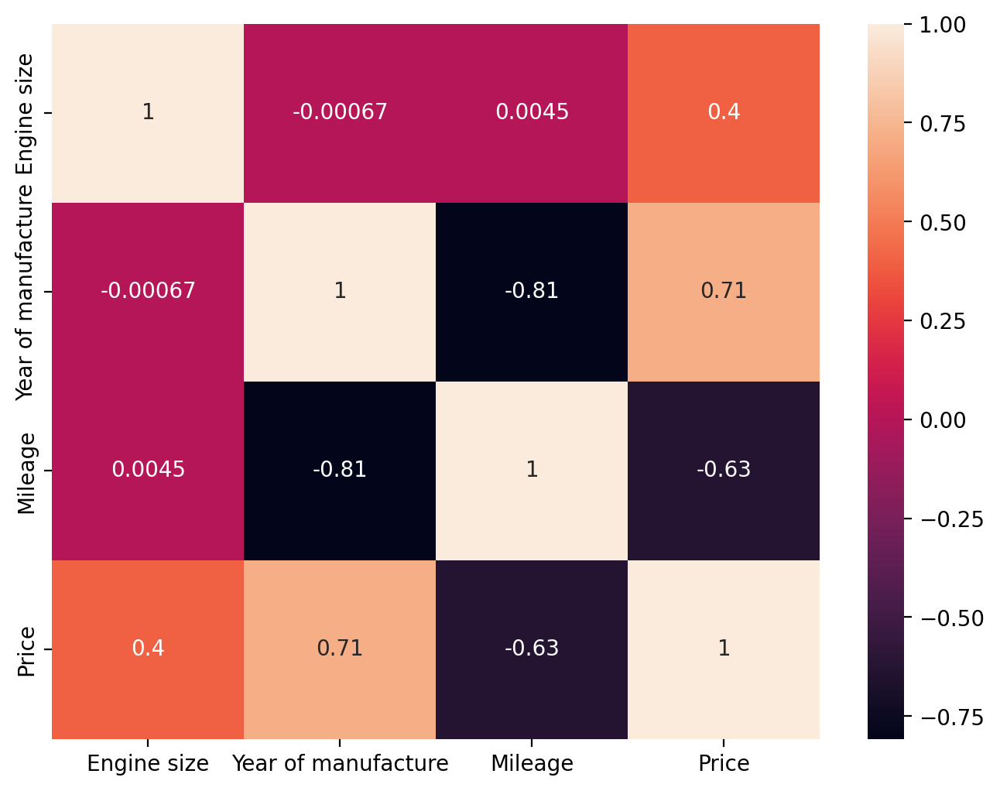

In [9]:
# Plot heatmap of correlations

# Set the figure size and DPI
plt.figure(figsize=(8, 6), dpi=200)
# List of columns for correlation analysis
column_list = ['Engine size', 'Year of manufacture', 'Mileage', 'Price']
# Create a heatmap of the correlation matrix for the specified columns
sns.heatmap(df[column_list].corr(), annot=True)
# Display the plot
plt.show()

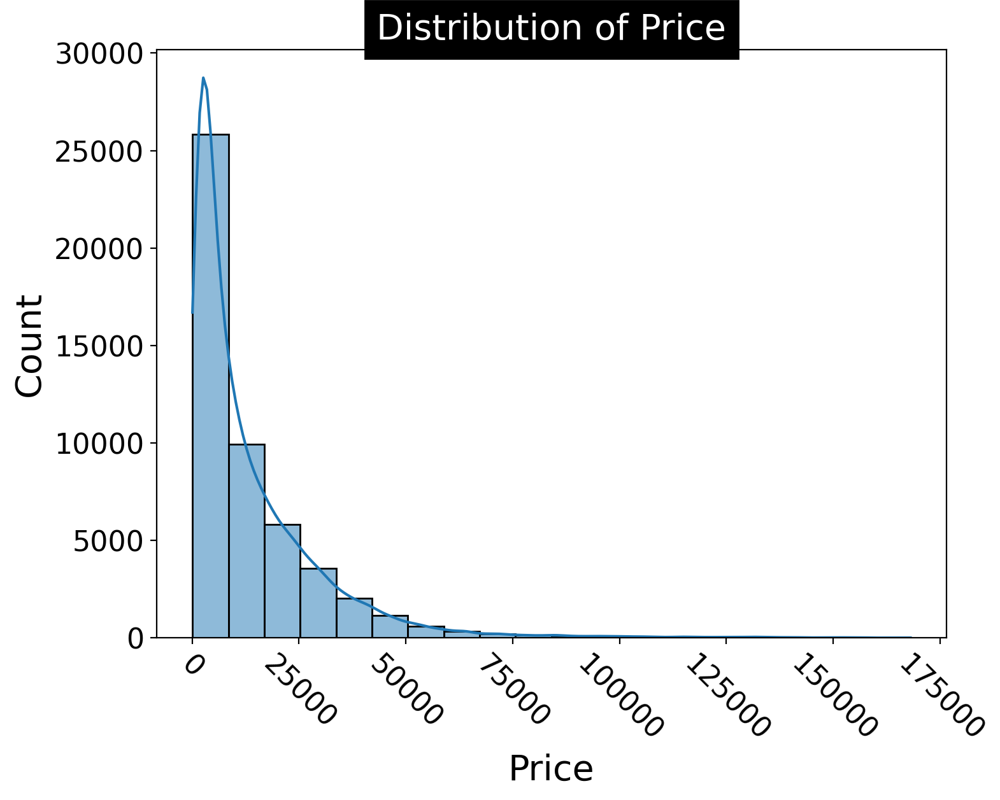

In [23]:
# Plot the distribution of "Price" column

# Set the figure size and DPI
plt.figure(figsize=(8, 6), dpi=200)
# Create a histogram of the 'Price' column with specified bins and kde
sns.histplot(df["Price"], bins=20, kde=True)
# Add a title to the plot with specified background color, text color, and fontsize
plt.title('Distribution of Price', backgroundcolor='black', color='white', fontsize=20)
# Set x and y axis labels with fontsize
plt.xlabel('Price', fontsize=20)
plt.ylabel('Count', fontsize=20)
# Increase the font size of x and y ticks
plt.xticks(fontsize=16, rotation=-45)
plt.yticks(fontsize=16)
# Display the plot
plt.show()

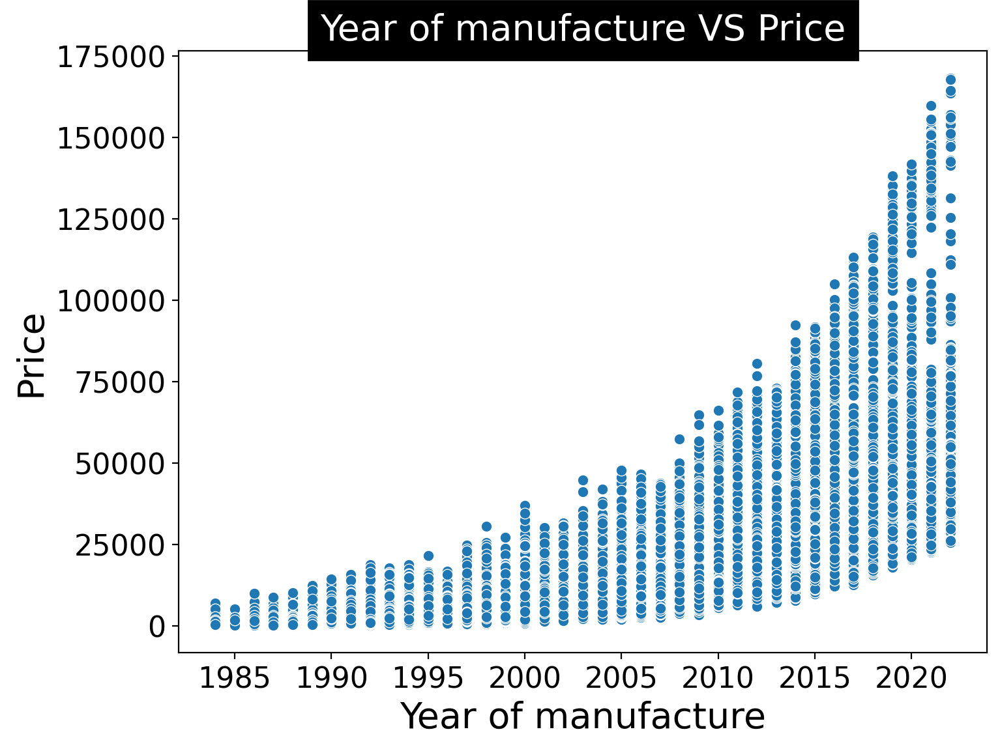

In [18]:
# Year of manufacture: continuous numerical variable

# Set the figure size and DPI
plt.figure (figsize=(8,6), dpi = 200)
# Create a scatter plot
sns.scatterplot(data = df, x = 'Year of manufacture', y = 'Price')
# Add a title to the plot
plt.title('Year of manufacture VS Price',backgroundcolor='black',color='white',fontsize=20)
# Set x and y axis labels with fontsize
plt.xlabel('Year of manufacture', fontsize=20)
plt.ylabel('Price', fontsize=20)
# Increase the font size of x and y ticks
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
# Display the plot
plt.show()

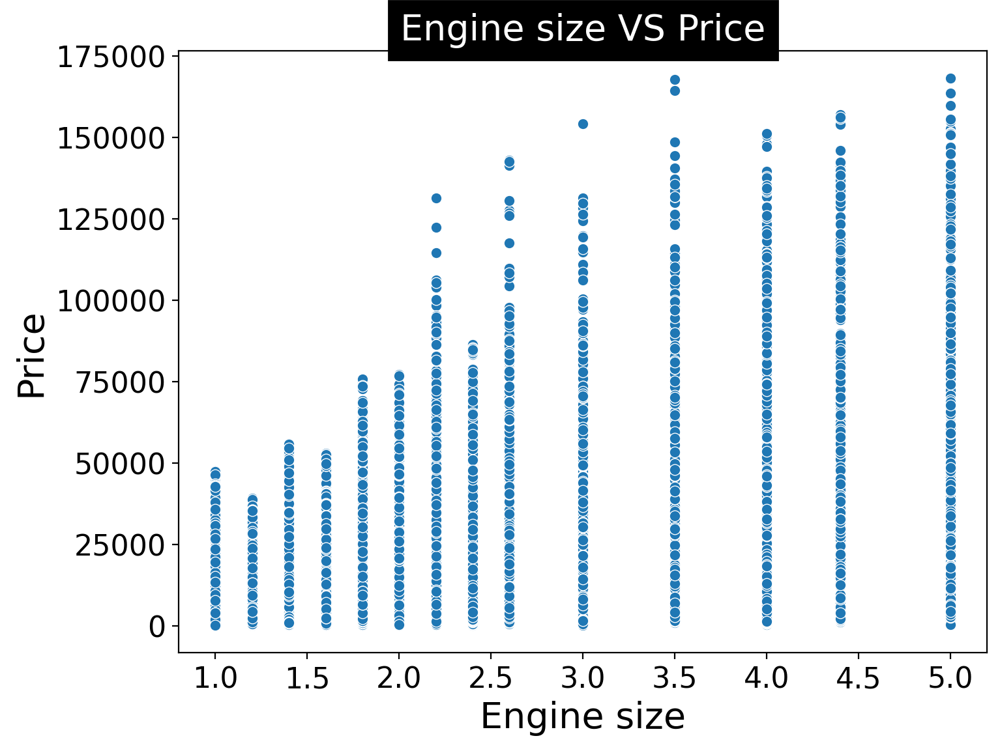

In [17]:
# Engine size: continuous numerical variable

# Set the figure size and DPI
plt.figure (figsize=(8,6), dpi = 200)
# Create a scatter plot
sns.scatterplot(data = df, x = 'Engine size', y = 'Price')
# Add a title to the plot
plt.title('Engine size VS Price',backgroundcolor='black',color='white',fontsize=20)
# Set x and y axis labels with fontsize
plt.xlabel('Engine size', fontsize=20)
plt.ylabel('Price', fontsize=20)
# Increase the font size of x and y ticks
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
# Display the plot
plt.show()

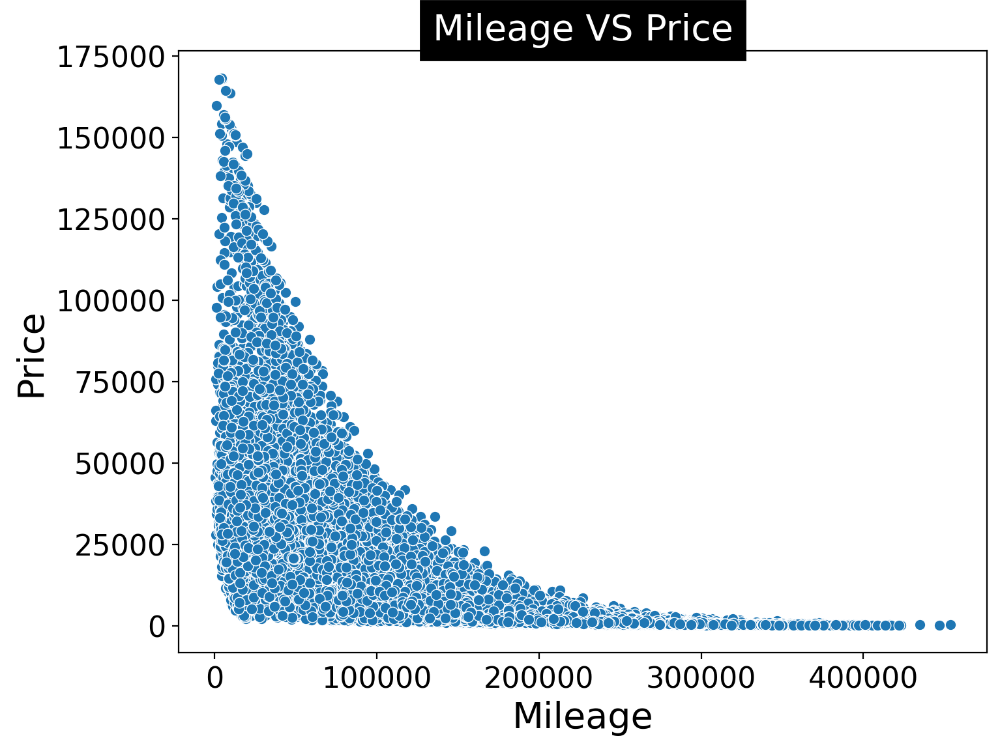

In [16]:
# Mileage: continuous numerical variable

# Set the figure size and DPI 
plt.figure (figsize=(8,6), dpi = 200)
# Create a scatter plot
sns.scatterplot(data = df, x = 'Mileage', y = 'Price')
# Add a title to the plot
plt.title('Mileage VS Price',backgroundcolor='black',color='white',fontsize=20)
# Set x and y axis labels with fontsize
plt.xlabel('Mileage', fontsize=20)
plt.ylabel('Price', fontsize=20)
# Increase the font size of x and y ticks
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
# Display the plot
plt.show()

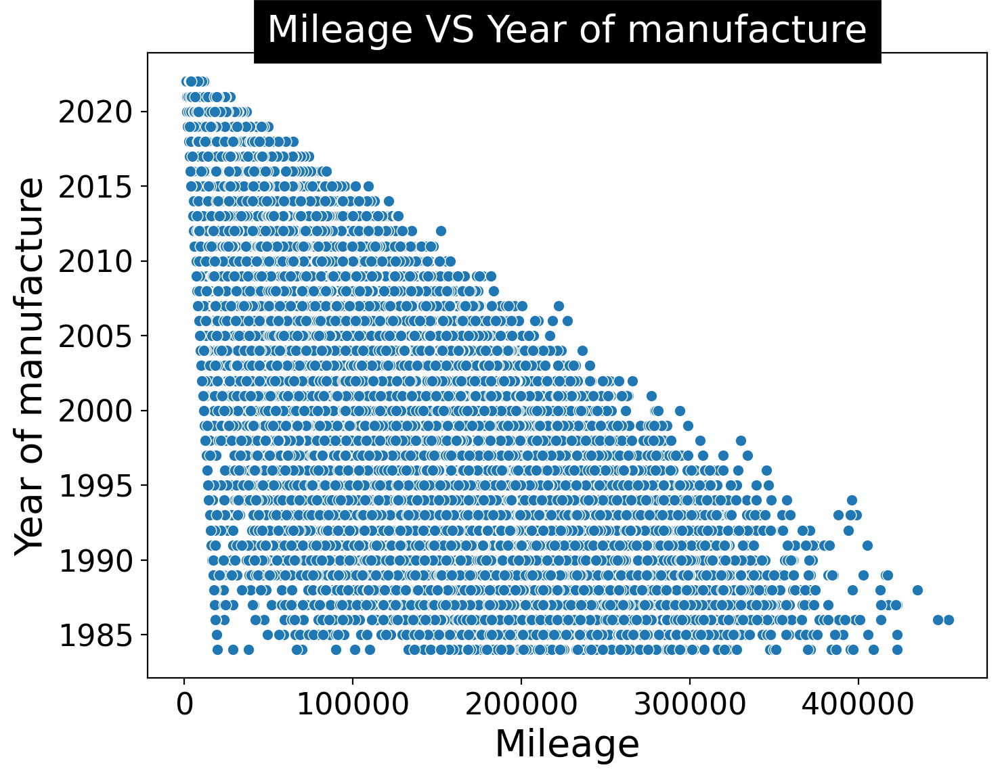

In [25]:
# Mileage VS Year of manufacture

# Set the figure size and DPI 
plt.figure (figsize=(8,6), dpi = 200)
# Create a scatter plot
sns.scatterplot(data = df, x = 'Mileage', y = 'Year of manufacture')
# Add a title to the plot
plt.title('Mileage VS Year of manufacture',backgroundcolor='black',color='white',fontsize=20)
# Set x and y axis labels with fontsize
plt.xlabel('Mileage', fontsize=20)
plt.ylabel('Year of manufacture', fontsize=20)
# Increase the font size of x and y ticks
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
# Display the plot
plt.show()

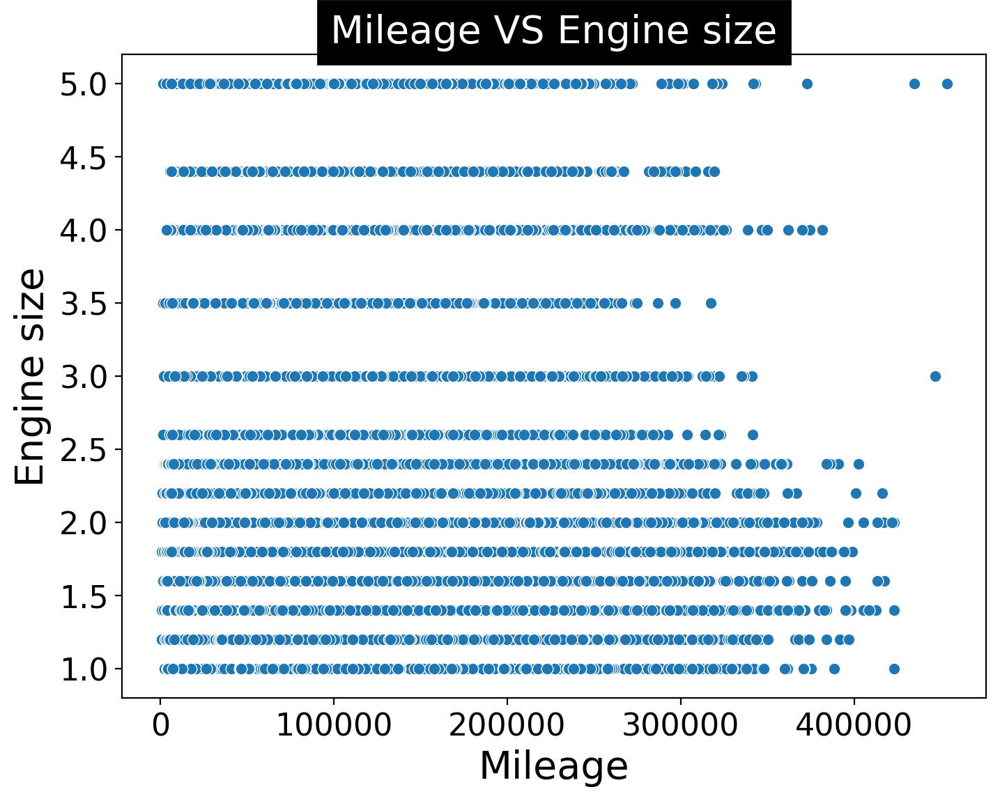

In [26]:
# Mileage VS Engine size

# Set the figure size and DPI 
plt.figure (figsize=(8,6), dpi = 200)
# Create a scatter plot
sns.scatterplot(data = df, x = 'Mileage', y = 'Engine size')
# Add a title to the plot
plt.title('Mileage VS Engine size',backgroundcolor='black',color='white',fontsize=20)
# Set x and y axis labels with fontsize
plt.xlabel('Mileage', fontsize=20)
plt.ylabel('Engine size', fontsize=20)
# Increase the font size of x and y ticks
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
# Display the plot
plt.show()

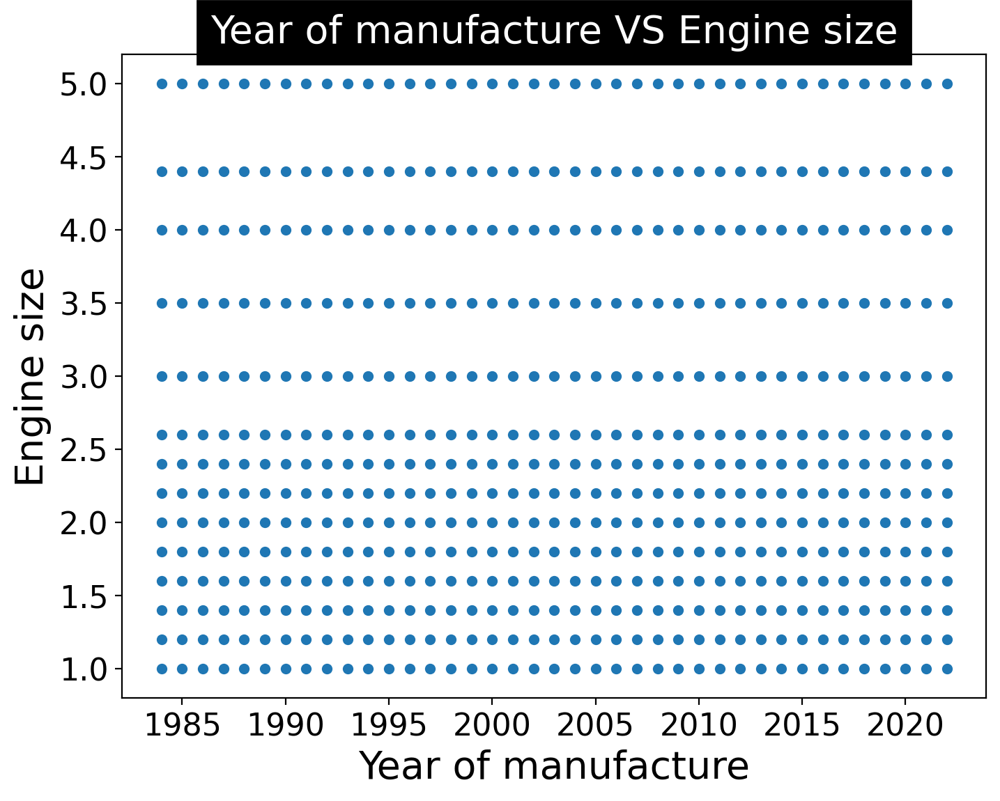

In [27]:
# Year of manufacture VS Engine size

# Set the figure size and DPI 
plt.figure (figsize=(8,6), dpi = 200)
# Create a scatter plot
sns.scatterplot(data = df, x = 'Year of manufacture', y = 'Engine size')
# Add a title to the plot
plt.title('Year of manufacture VS Engine size',backgroundcolor='black',color='white',fontsize=20)
# Set x and y axis labels with fontsize
plt.xlabel('Year of manufacture', fontsize=20)
plt.ylabel('Engine size', fontsize=20)
# Increase the font size of x and y ticks
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
# Display the plot
plt.show()

If we want to know, on average, which type of Fuel for a car is most valuable, we can group and average it.

In [15]:
# Create an empty dictionary
Fuel_dic = {}
# Loop through unique fuel types in the "Fuel type" column
for Fuel in df["Fuel type"].unique():
    # Create a DataFrame with "Price" statistics for the current fuel type
    Fuel_dic[Fuel] = df[df["Fuel type"] == Fuel]["Price"].describe()
# Create a DataFrame from the dictionary of fuel type statistics
Fuel_stats = pd.DataFrame(Fuel_dic)
# Display the resulting DataFrame
print(Fuel_stats)

,Petrol,Diesel,Hybrid
count,25488.000000,13268.000000,11244.000000
mean,13690.617742,13145.078158,14949.288154
std,18430.791774,13085.271179,14985.775971
min,76.000000,122.000000,176.000000
25%,2768.000000,3269.750000,3579.750000
50%,7266.000000,8348.500000,9357.000000
75%,17581.250000,19450.500000,22084.250000
max,168081.000000,125357.000000,86353.000000


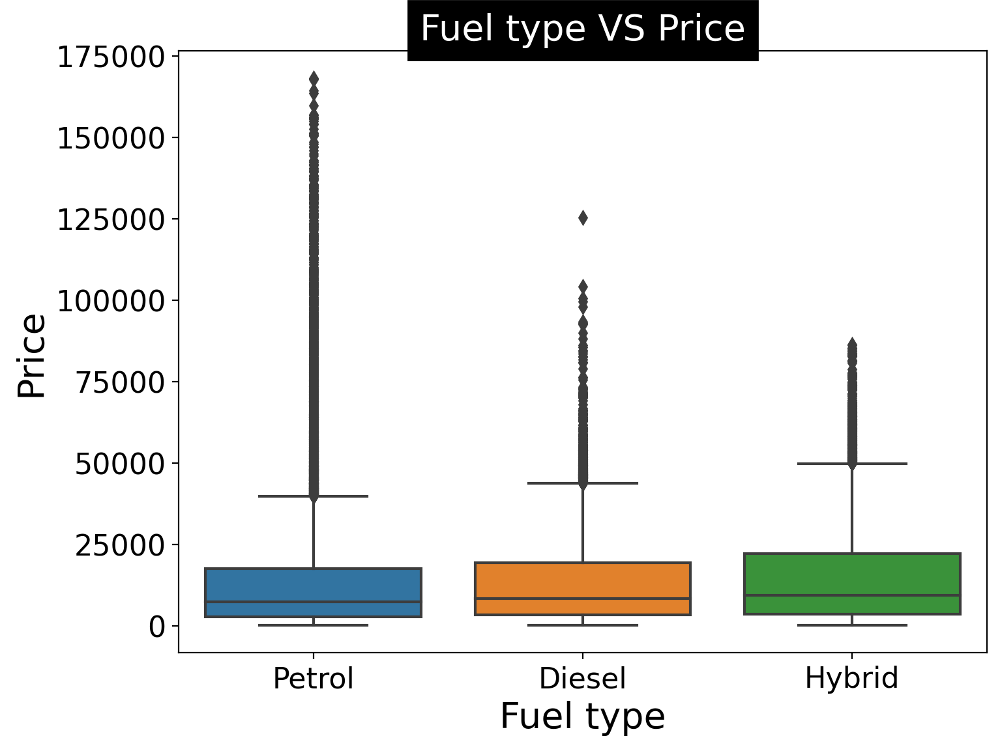

In [28]:
# 'Fuel type': Categorical feature

# Set the figure size and DPI 
plt.figure (figsize=(8,6), dpi = 200)
# Create a box plot
sns.boxplot(x='Fuel type', y='Price', data=df)
# Add a title to the plot
plt.title('Fuel type VS Price',backgroundcolor='black',color='white',fontsize=20)
# Set x and y axis labels with fontsize
plt.xlabel('Fuel type', fontsize=20)
plt.ylabel('Price', fontsize=20)
# Increase the font size of x and y ticks
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
# Display the plot
plt.show()

# 4. Model Development

## A. Supervised learning models to predict Price

### A1. Simple Linear Regression

### A.1.1 Year of manufacture - Price

In [29]:
# Selecting feature and target columns
x = df[["Year of manufacture"]]
y = df["Price"]

In [30]:
# Create a StandardScaler object
scale = StandardScaler()
# Fit the scaler to the "Year of manufacture" feature and transform it to a normalized form
x_norm = scale.fit_transform(x)

In [31]:
# Split the data into training and testing sets
x_train, x_test, y_train, y_test = train_test_split(x_norm, y, test_size = 0.2, random_state = 42)

# check the size of the training and testing sets.
print (f'The size of training set: {x_train.shape[0]} data points')
print (f'The size of testing set: {x_test.shape[0]} data points')

The size of training set: 40000 data points

The size of testing set: 10000 data points


In [32]:
# Create a LinearRegression model
lr = LinearRegression()
# Train the model using the training data
lr.fit(x_train, y_train)

LinearRegression()

In [33]:
# Extract the slope (gradient) and intercept from the trained linear regression model
gradient = lr.coef_[0]
intercept = lr.intercept_
# Print the values of the slope and intercept
print(f"Slope (Gradient): {gradient:.3f}")
print(f"Intercept: {intercept:.3f}")

Slope (Gradient): 11715.456

Intercept: 13825.710


In [34]:
# make prediction on the test data
price_pred = lr.predict(x_test)

In [35]:
# Calculate and print the evaluation metrics
print("Evaluation Metrics for S.L.Regression Model")
print("=============================================")
print(f"Mean Absolte Error: {mean_absolute_error(y_test, price_pred):.2f}")
print(f"Mean Squared Error: {mean_squared_error(y_test, price_pred):.2f}")
print(f"Root Mean Squared Error:: {np.sqrt(mean_squared_error(y_test, price_pred)):.2f}")
print(f"R2 Score: {r2_score(y_test, price_pred):.2f}")

Evaluation Metrics for S.L.Regression Model


Mean Absolte Error: 7031.04

Mean Squared Error: 132678999.95

Root Mean Squared Error:: 11518.64

R2 Score: 0.51


In [36]:
# Generate a range of x values for prediction
x_fit = np.arange(1984, 2024, 1).reshape(-1, 1)
# Scale the x values using the same StandardScaler
x_fit_scaled = scale.transform(x_fit)
# Use the linear regression model to predict y values for the scaled x values
y_fit = lr.predict(x_fit_scaled)

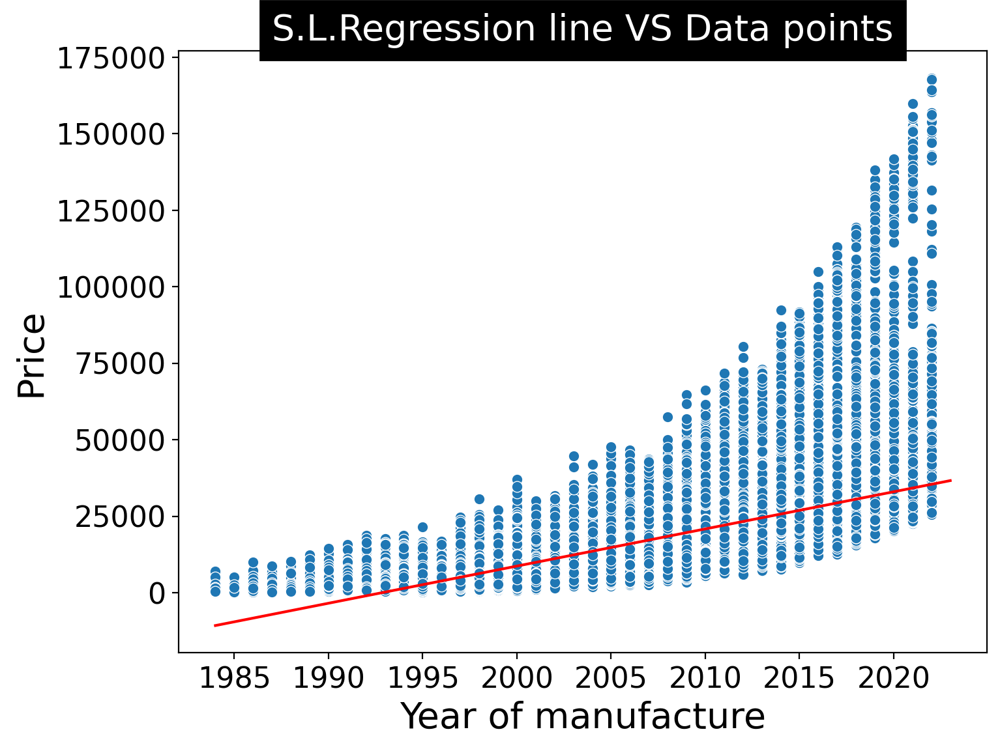

In [37]:
# Scatter plot of original data points vs Regression line
plt.figure (figsize=(8,6), dpi = 200)
# Create a scatter plot
sns.scatterplot(data=df, x="Year of manufacture", y="Price")
# Plot the regression line in red
plt.plot(x_fit, y_fit, color="red")
# Add a title to the plot
plt.title('S.L.Regression line VS Data points',backgroundcolor='black',color='white',fontsize=20)
# Set x and y axis labels with fontsize
plt.xlabel('Year of manufacture', fontsize=20)
plt.ylabel('Price', fontsize=20)
# Increase the font size of x and y ticks
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
# Display the plot
plt.show()

### A.1.2. Mileage - Price

In [38]:
# Selecting feature column (target calumn is the same as before).
x2 = df[["Mileage"]]

In [39]:
# Create a StandardScaler object
scale2 = StandardScaler()
# Fit the scaler to the "Mileage" feature and transform it to a normalized form
x_norm2 = scale2.fit_transform(x2)

In [40]:
# Split the data into training and testing sets
x_train2, x_test2, y_train2, y_test2 = train_test_split(x_norm2, y, test_size = 0.2, random_state = 42)

In [41]:
# Create a LinearRegression model
lr2 = LinearRegression()
# Train the model using the training data
lr2.fit(x_train2, y_train2)

LinearRegression()

In [42]:
# Extract the slope (gradient) and intercept from the trained linear regression model
gradient2 = lr2.coef_[0]
intercept2 = lr2.intercept_
# Print the values of the slope and intercept
print("gradient: ", gradient2)
print("intercept: ", intercept2)

gradient:  -10383.851164835316

intercept:  13814.105147747927


In [43]:
# Use the trained linear regression model to make predictions on the test data
price_pred2 = lr2.predict(x_test2)

In [44]:
# Calculate and print the evaluation metrics
print("Evaluation Metrics for S.L.Regression Model")
print("=============================================")
print(f"Mean Absolte Error: {mean_absolute_error(y_test2, price_pred2):.2f}")
print(f"Mean Squared Error: {mean_squared_error(y_test2, price_pred2):.2f}")
print(f"Root Mean Squared Error:: {np.sqrt(mean_squared_error(y_test2, price_pred2)):.2f}")
print(f"R2 Score: {r2_score(y_test2, price_pred2):.2f}")

Evaluation Metrics for S.L.Regression Model


Mean Absolte Error: 7964.78

Mean Squared Error: 162468566.87

Root Mean Squared Error:: 12746.32

R2 Score: 0.40


In [45]:
# Generate a range of x values for prediction
x_fit2 = np.arange(630, 454000, 1).reshape(-1, 1)
# Scale the x values using the same StandardScaler
x_fit_scaled2 = scale2.transform(x_fit2)
# Use the linear regression model to predict y values for the scaled x values
y_fit2 = lr2.predict(x_fit_scaled2)

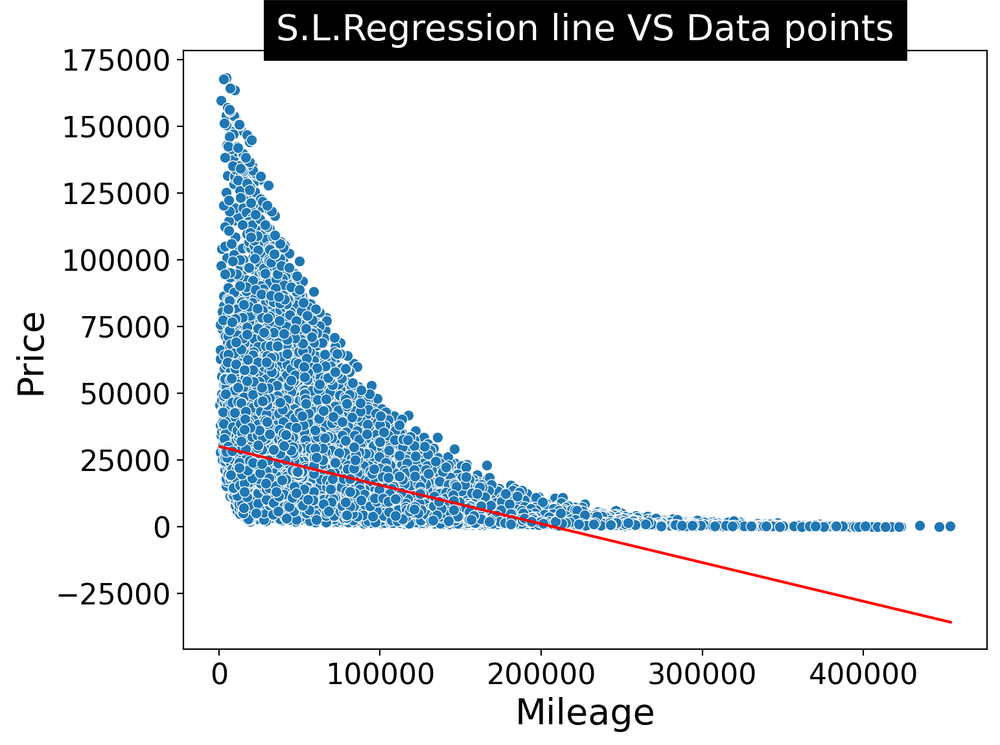

In [46]:
# Scatter plot of original data points
plt.figure (figsize=(8,6), dpi = 200)
sns.scatterplot(data = df, x = "Mileage", y = "Price")
# Plot the regression line in red
plt.plot(x_fit2, y_fit2, color = "red")
# Add a title to the plot
plt.title('S.L.Regression line VS Data points',backgroundcolor='black',color='white',fontsize=20)
# Set x and y axis labels with fontsize
plt.xlabel('Mileage', fontsize=20)
plt.ylabel('Price', fontsize=20)
# Increase the font size of x and y ticks
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
# Display the plot
plt.show()

### A.1.3. Engine size - Price

In [47]:
# Selecting feature column (target calumn is the same as before)
x3 = df[["Engine size"]]

In [48]:
# Create a StandardScaler object
scale3 = StandardScaler()
# Fit the scaler to the "Engine size" feature and transform it to a normalized form
x_norm3 = scale3.fit_transform(x3)

In [49]:
# Split the data into training and testing sets
x_train3, x_test3, y_train3, y_test3 = train_test_split(x_norm3, y, test_size = 0.2, random_state = 42)

In [50]:
# Create a LinearRegression model
lr3 = LinearRegression()
# Train the model using the training data
lr3.fit(x_train3, y_train3)

LinearRegression()

In [51]:
# Extract the slope (gradient) and intercept from the trained linear regression model
gradient3 = lr3.coef_[0]
intercept3 = lr3.intercept_
# Print the values of the slope and intercept
print("gradient: ", gradient3)
print("intercept: ", intercept3)

gradient:  6538.708704515958

intercept:  13853.141213791609


In [52]:
# make prediction on the test data
price_pred3 = lr3.predict(x_test3)

In [53]:
# Calculate and print the evaluation metrics
print("Evaluation Metrics for S.L.Regression Model")
print("=============================================")
print(f"Mean Absolte Error: {mean_absolute_error(y_test3, price_pred3):.2f}")
print(f"Mean Squared Error: {mean_squared_error(y_test3, price_pred3):.2f}")
print(f"Root Mean Squared Error:: {np.sqrt(mean_squared_error(y_test3, price_pred3)):.2f}")
print(f"R2 Score: {r2_score(y_test3, price_pred3):.2f}")

Evaluation Metrics for S.L.Regression Model


Mean Absolte Error: 10817.49

Mean Squared Error: 230499154.45

Root Mean Squared Error:: 15182.20

R2 Score: 0.15


In [54]:
# Generate a range of x values for prediction
x_fit3 = np.arange(1, 6, 1).reshape(-1, 1)
# Scale the x values using the same StandardScaler
x_fit_scaled3 = scale3.transform(x_fit3)
# Use the linear regression model to predict y values for the scaled x values
y_fit3 = lr3.predict(x_fit_scaled3)

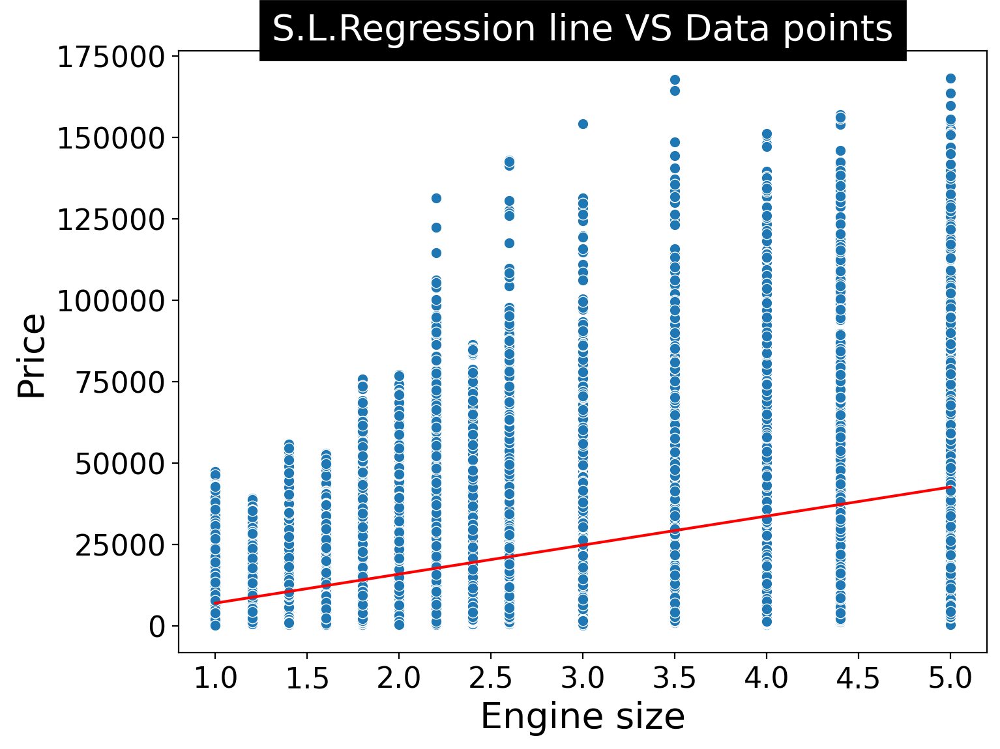

In [55]:
# Scatter plot of original data points
plt.figure (figsize=(8,6), dpi = 200)
sns.scatterplot(data = df, x = "Engine size", y = "Price")
# Plot the regression line in red
plt.plot(x_fit3, y_fit3, color = "red")
# Add a title to the plot
plt.title('S.L.Regression line VS Data points',backgroundcolor='black',color='white',fontsize=20)
# Set x and y axis labels with fontsize
plt.xlabel('Engine size', fontsize=20)
plt.ylabel('Price', fontsize=20)
# Increase the font size of x and y ticks
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
# Display the plot
plt.show()

### A2. Polynomial Regression

In [56]:
def poly_degree_evaluator (x_train, x_test, y_train, y_test ):
    """
    Evaluate polynomial regression models with degrees ranging from 2 to 5.

    Parameters:
    - x_train (array): Training data for the independent variable.
    - x_test (array): Test data for the independent variable.
    - y_train (array): Training data for the dependent variable.
    - y_test (array): Test data for the dependent variable.

    This function prints evaluation metrics such as Mean Absolute Error,
    Mean Squared Error, Root Mean Squared Error, and R2 Score for polynomial
    regression models with degrees from 2 to 5. It also plots the R2 scores
    for the test data.
    """
    # Initialize a linear regression model
    price_poly = LinearRegression()
    # create an empty list
    Rsqu_test = []
    
    # Loop through polynomial degrees from 2 to 5
    for deg in range(2, 6):
        # Create polynomial features
        poly = PolynomialFeatures(degree=deg, include_bias=False)
        # Transform training and test data to polynomial features
        x_train_pr = poly.fit_transform(x_train)
        x_test_pr = poly.transform(x_test)
        # Train the model using the polynomial features
        price_poly.fit(x_train_pr, y_train)
        
        # Predict on the test set
        price_pred_pr = price_poly.predict(x_test_pr)
        
        # Calculate R-squared score and store it
        Rsqu_test.append(r2_score(y_test, price_pred_pr))
        
        # Print evaluation metrics for the current polynomial degree
        print(f"Evaluation Metrics for polynomial degree {deg}")
        print("===============================================")
        print(f"Mean Absolute Error: {mean_absolute_error(y_test, price_pred_pr):.4f}")
        print(f"Mean Squared Error: {mean_squared_error(y_test, price_pred_pr):.4f}")
        print(f"Root Mean Squared Error: {np.sqrt(mean_squared_error(y_test, price_pred_pr)):.4f}")
        print(f"R2 Score: {r2_score(y_test, price_pred_pr):.4f}\n")
    
    # Plot R-squared scores for different polynomial degrees
    plt.plot(range(2,6), Rsqu_test)
    plt.xlabel('order')
    plt.ylabel('R2_score')
    plt.title('R2_score Using Test Data')
    plt.show()

In [67]:
def plot_poly (x_train, x_test, y_train, y_test, scale, range1, range2, title):
    """
    Plot polynomial regression models for different degrees (degree 2-5).

    Parameters:
    - x_train (array-like): Training data for the independent variable.
    - x_test (array-like): Test data for the independent variable.
    - y_train (array-like): Training data for the dependent variable.
    - y_test (array-like): Test data for the dependent variable.
    - scale (object): Scaler object used for transforming x values.
    - range1 (float): Lower bound of the x values range for plotting.
    - range2 (float): Upper bound of the x values range for plotting.
    - title (str): Title for the plots.

    This function creates a 2x2 subplot grid and plots polynomial regression
    models for degrees 2 to 5. It includes scatter plots of original data
    points and the fitted curves for each degree. The x values are transformed,
    and the range of x values for plotting
    is specified by the 'range1' and 'range2' parameters.
    """
    # Create a 2x2 subplot grid with a specified figure size
    fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(12,9))
    # Add a main title to the entire figure
    plt.suptitle(f"Polynomial Regression ({title}-Price)",backgroundcolor='black',color='white',fontsize=14)
    # Adjust vertical spacing between subplots for better readability
    plt.subplots_adjust(hspace=0.3)
    plt.subplots_adjust(wspace=0.3)
    # Initialize subplot indices
    i = 0
    j = 0
    # Loop through polynomial degrees from 2 to 5
    for deg in range(2, 6):
        # Create polynomial features
        poly = PolynomialFeatures(degree=deg, include_bias=False)
        x_train_pr = poly.fit_transform(x_train)
        x_test_pr = poly.transform(x_test)
        # Train a linear regression model
        price_poly = LinearRegression()
        price_poly.fit(x_train_pr, y_train)
        # Generate x values for plotting the fitted curve
        x_fit = np.arange(range1, range2, 1).reshape(-1, 1)
        # Scale the x values using a pre-defined 'scale' transformation
        x_fit_scaled = scale.transform(x_fit)
        # Transform the scaled x values to polynomial features
        x_fit_scaled_poly = poly.fit_transform(x_fit_scaled)
        # Predict y values for the fitted curve
        y_fit = price_poly.predict(x_fit_scaled_poly)

        # Scatter plot of original data points
        axs[i, j].scatter(df[title], df["Price"])
        # Plot the fitted curve in red
        axs[i, j].plot(x_fit, y_fit, color="red")
        # Set subplot title and axis labels
        axs[i, j].set_title(f'Degree {deg}',backgroundcolor='black',color='white',fontsize=10)
        axs[i, j].set_xlabel(title)
        axs[i, j].set_ylabel('Price (Pound)')
        # Update subplot indices for the next iteration
        if i < 1:
            i += 1
        else:
            i = 0
            j += 1
    # Display the entire figure
    plt.show()

### Year of manufacture VS Price

Evaluation Metrics for polynomial degree 2


Mean Absolute Error: 5387.1091

Mean Squared Error: 105993894.2019

Root Mean Squared Error: 10295.3336

R2 Score: 0.6094



Evaluation Metrics for polynomial degree 3


Mean Absolute Error: 5186.8689

Mean Squared Error: 103043508.1453

Root Mean Squared Error: 10151.0348

R2 Score: 0.6203



Evaluation Metrics for polynomial degree 4


Mean Absolute Error: 5162.8840

Mean Squared Error: 102720854.7323

Root Mean Squared Error: 10135.1297

R2 Score: 0.6215



Evaluation Metrics for polynomial degree 5


Mean Absolute Error: 5160.7727

Mean Squared Error: 102654671.4653

Root Mean Squared Error: 10131.8642

R2 Score: 0.6217




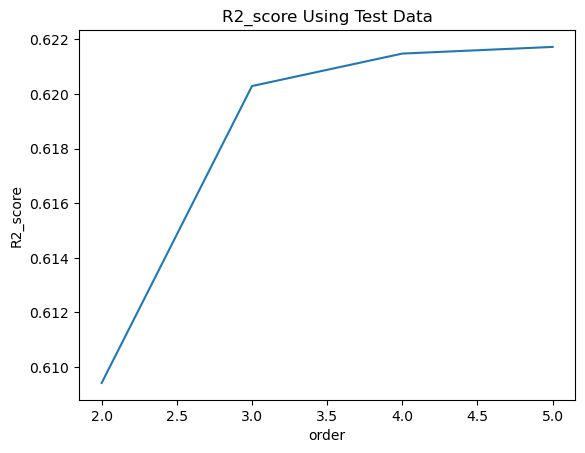

In [59]:
# Call the poly_degree_evaluator function with 'Year of manufacture' VS 'Price' dataset

poly_degree_evaluator (x_train, x_test, y_train, y_test )

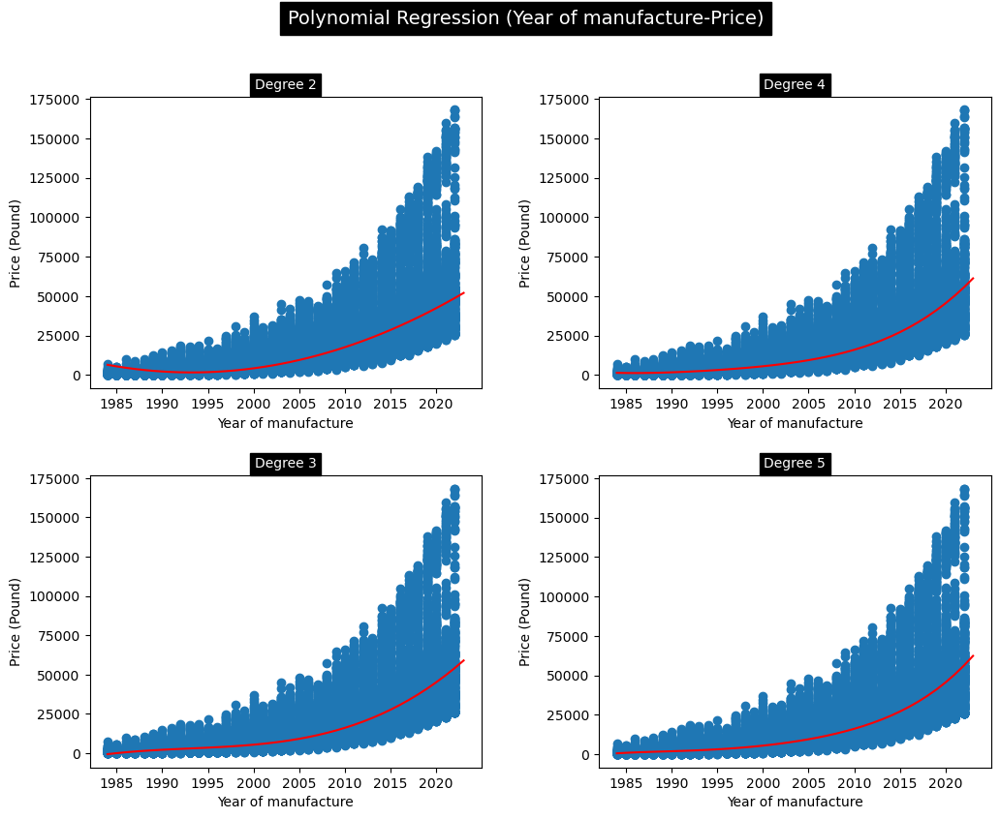

In [68]:
# Call the plot_poly function with specified arguments for 'Year of manufacture' VS 'Price' dataset

plot_poly (x_train, x_test, y_train, y_test, scale, 1984, 2024, 'Year of manufacture')

### Mileage - Price

Evaluation Metrics for polynomial degree 2


Mean Absolute Error: 6409.9116

Mean Squared Error: 129620312.1626

Root Mean Squared Error: 11385.0917

R2 Score: 0.5224



Evaluation Metrics for polynomial degree 3


Mean Absolute Error: 5815.6694

Mean Squared Error: 122123243.4158

Root Mean Squared Error: 11050.9386

R2 Score: 0.5500



Evaluation Metrics for polynomial degree 4


Mean Absolute Error: 5719.6716

Mean Squared Error: 120800573.8461

Root Mean Squared Error: 10990.9314

R2 Score: 0.5549



Evaluation Metrics for polynomial degree 5


Mean Absolute Error: 5698.0122

Mean Squared Error: 120626997.2626

Root Mean Squared Error: 10983.0322

R2 Score: 0.5555




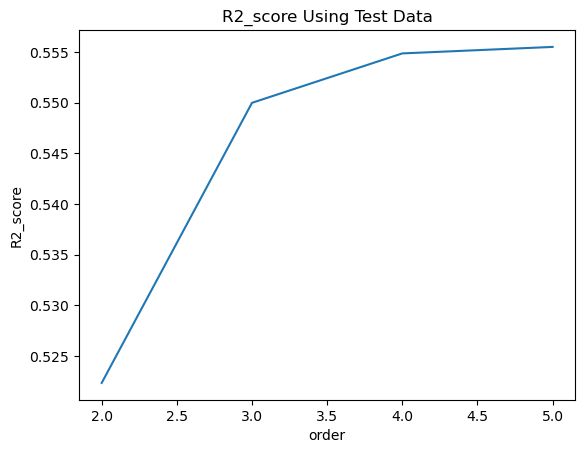

In [69]:
# Call the poly_degree_evaluator function with 'Mileage' VS 'Price' dataset

poly_degree_evaluator (x_train2, x_test2, y_train2, y_test2)

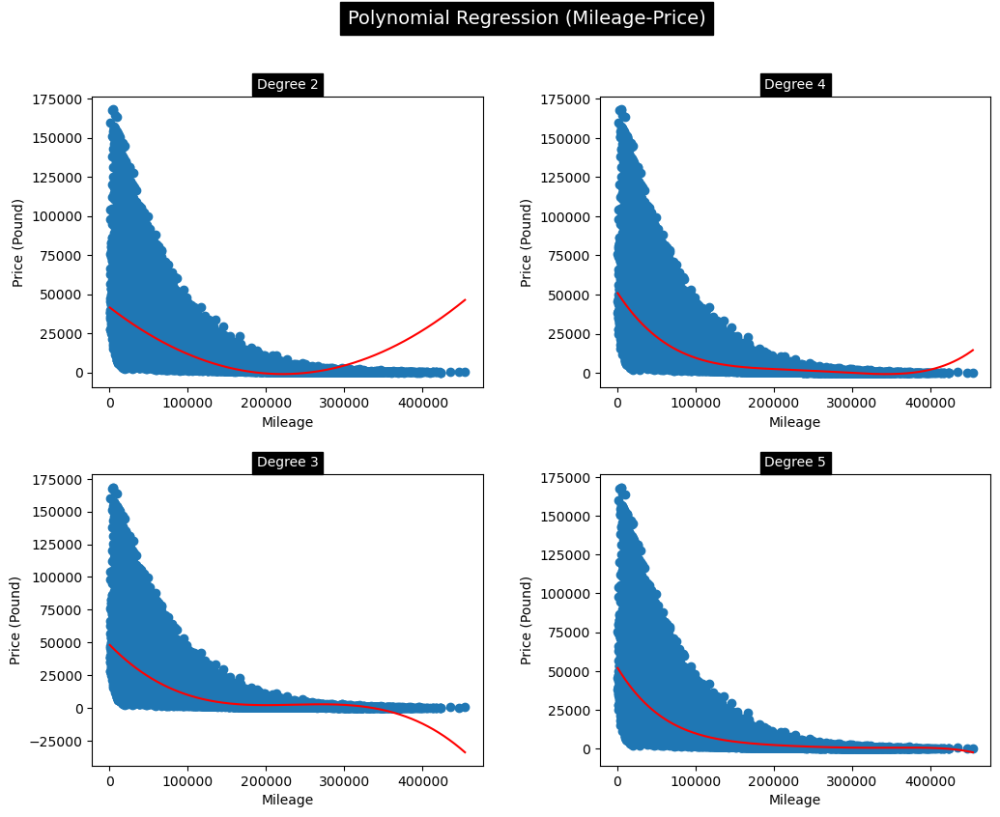

In [70]:
# Call the plot_poly function with specified arguments for 'Mileage' VS 'Price' dataset

plot_poly (x_train2, x_test2, y_train2, y_test2, scale2, 630, 454000, 'Mileage')

### Engine size - Price

Evaluation Metrics for polynomial degree 2


Mean Absolute Error: 10807.2623

Mean Squared Error: 230326165.9995

Root Mean Squared Error: 15176.5005

R2 Score: 0.1513



Evaluation Metrics for polynomial degree 3


Mean Absolute Error: 10802.8690

Mean Squared Error: 230076036.2678

Root Mean Squared Error: 15168.2575

R2 Score: 0.1522



Evaluation Metrics for polynomial degree 4


Mean Absolute Error: 10801.4463

Mean Squared Error: 230012047.3260

Root Mean Squared Error: 15166.1481

R2 Score: 0.1524



Evaluation Metrics for polynomial degree 5


Mean Absolute Error: 10801.1384

Mean Squared Error: 230001460.4786

Root Mean Squared Error: 15165.7990

R2 Score: 0.1525




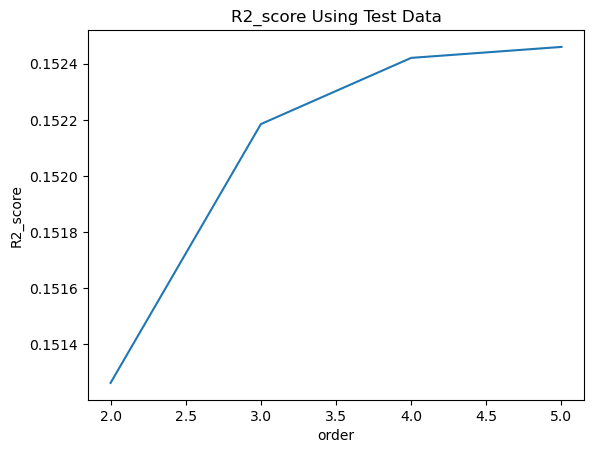

In [71]:
# Call the poly_degree_evaluator function with 'Engine size' VS 'Price' dataset

poly_degree_evaluator (x_train3, x_test3, y_train3, y_test3)

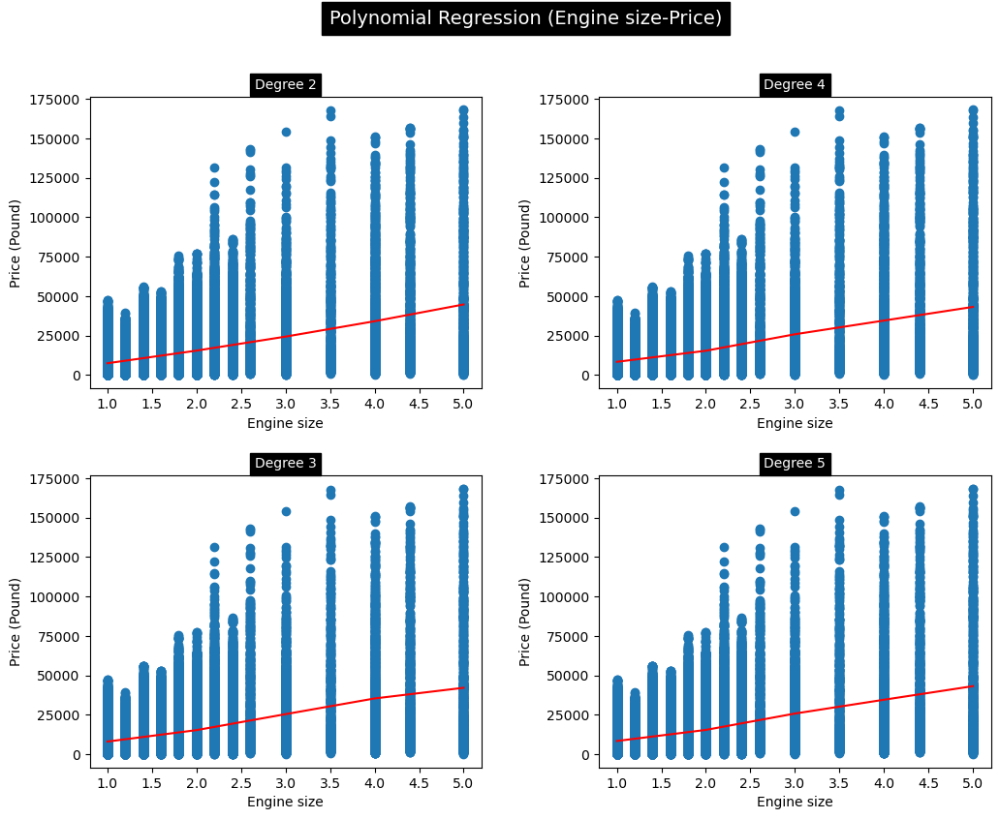

In [72]:
# Call the plot_poly function with specified arguments for 'Engine size' VS 'Price' dataset

plot_poly (x_train3, x_test3, y_train3, y_test3, scale3, 1, 6, 'Engine size')

## B. Multiple Input Regression models

### B1. Multiple Linear Regression

In [73]:
# Define a list of feature names
feature_names = ["Year of manufacture", "Mileage", "Engine size"]
# Create a new DataFrame containing only the selected features
x_multi = df[feature_names]

In [74]:
# Fit the scaler to the selected features and transform it to a normalized form
x_multi_norm = StandardScaler().fit(x_multi).transform(x_multi)

In [75]:
# Split the data into training and testing sets
x_train4, x_test4, y_train4, y_test4 = train_test_split(x_multi_norm, y, test_size = 0.2, random_state = 42)

In [76]:
# Create a LinearRegression model
lr4 = LinearRegression()
# Train the model using the training data
lr4.fit(x_train4, y_train4)

LinearRegression()

In [77]:
# Extract the slope (gradient) and intercept from the trained linear regression model
gradient4 = lr4.coef_
intercept4 = lr4.intercept_
# Print the values of the slope and intercept
print("gradient_multi: ", gradient4)
print("intercept_multi: ", intercept4)

gradient_multi:  [ 9523.53115353 -2722.98087711  6556.96999124]

intercept_multi:  13819.002455115193


In [78]:
# Use the trained linear regression model to make predictions on the test data
price_pred_multi = lr4.predict(x_test4)

In [79]:
# Calculate and print the evaluation metrics
print("Evaluation Metrics for Multiple Linear Regression")
print("==================================================")
print(f"Mean Absolte Error: {mean_absolute_error(y_test4, price_pred_multi):.2f}")
print(f"Mean Squared Error: {mean_squared_error(y_test4, price_pred_multi):.2f}")
print(f"Root Mean Squared Error: {np.sqrt(mean_squared_error(y_test4, price_pred_multi)):.2f}")
print(f"R2 Score: {r2_score(y_test4, price_pred_multi):.2f}")

Evaluation Metrics for Multiple Linear Regression


Mean Absolte Error: 6091.46

Mean Squared Error: 89158615.76

Root Mean Squared Error: 9442.38

R2 Score: 0.67


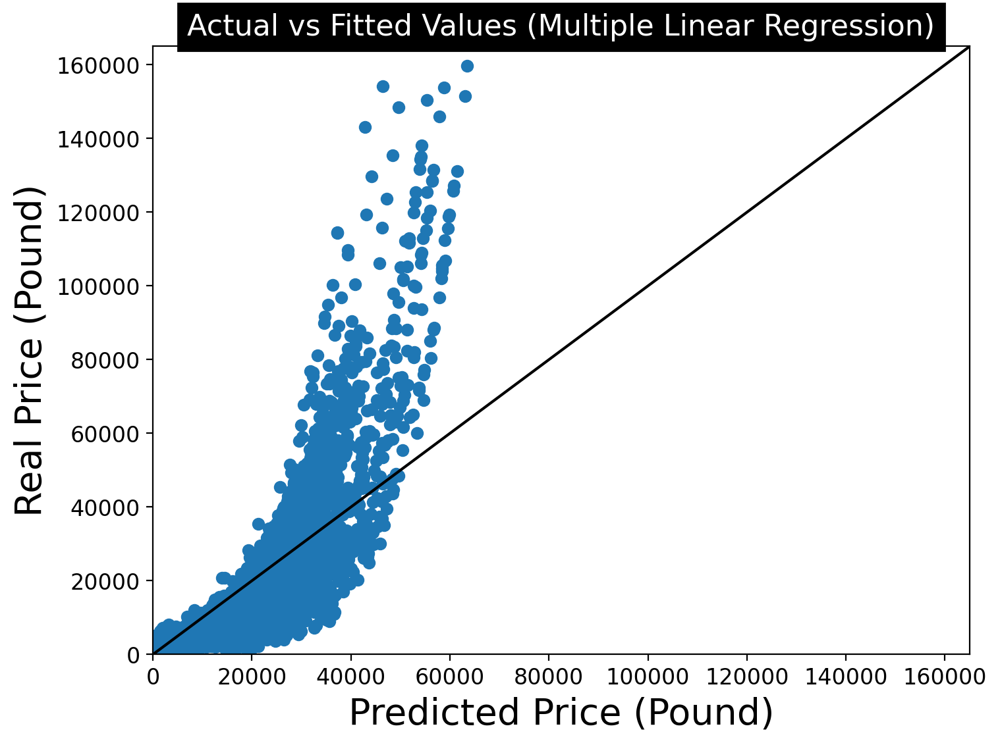

In [83]:
# Set the figure size and DPI for the scatter plot
plt.figure(figsize=(8, 6), dpi=200)
# Scatter plot of predicted prices vs. actual prices
plt.scatter(price_pred_multi, y_test4)
# Add a straight diagonal line to represent perfect predictions
plt.plot([0, 165000], [0, 165000], 'k-')
# Limit the range of values on both x and y axes
plt.xlim(0, 165000)
plt.ylim(0, 165000)
# Add title to the plot with specified background color, text color, and fontsize
plt.title('Actual vs Fitted Values (Multiple Linear Regression)', backgroundcolor='black', color='white', fontsize=16)
# Set x and y axis labels with specified fontsize
plt.xlabel("Predicted Price (Pound)", fontsize=20)
plt.ylabel("Real Price (Pound)", fontsize=20)
# Increase the font size of x and y axis ticks
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
# Display the plot
plt.show()

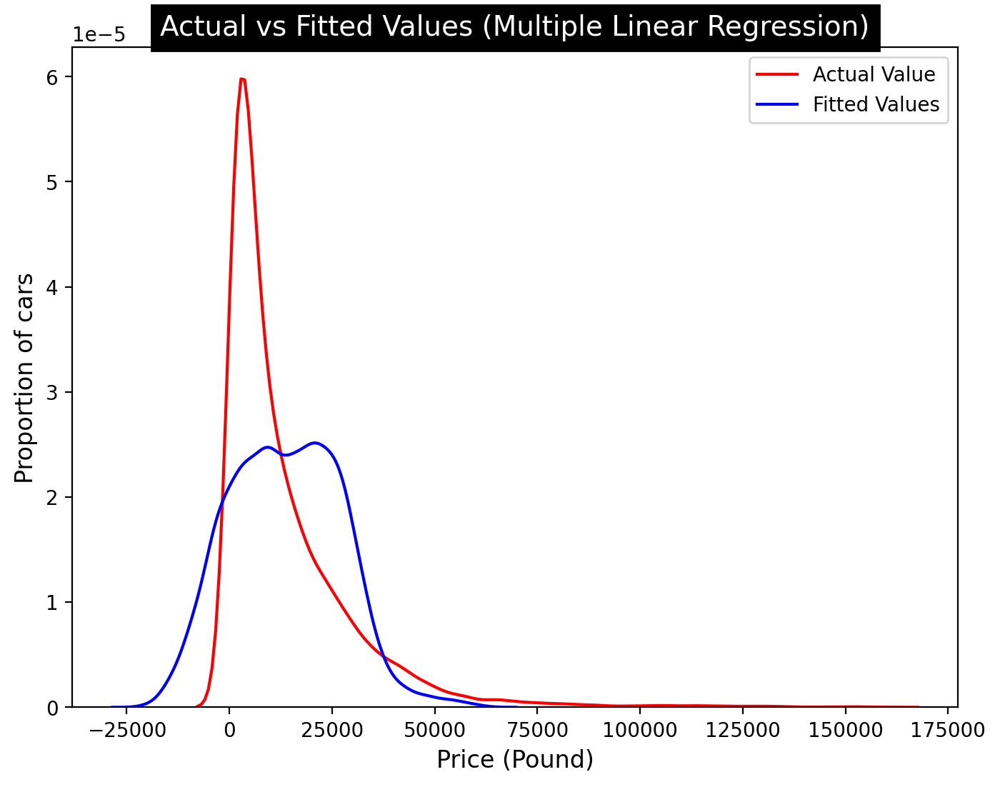

In [84]:
# Plotting the distribution of actual values (y_test4) and fitted values (price_pred_multi)
plt.figure (figsize=(8,6), dpi = 200)
ax1 = sns.distplot(y_test4, hist=False, color="r", label="Actual Value")
sns.distplot(price_pred_multi, hist=False, color="b", label="Fitted Values", ax=ax1)
# Adding title and labels to the plot
plt.title('Actual vs Fitted Values (Multiple Linear Regression)',backgroundcolor='black',color='white',fontsize=14)
plt.xlabel('Price (Pound)', fontsize = 12)
plt.ylabel('Proportion of cars', fontsize = 12)
# Displaying the legend for better interpretation
plt.legend()
# Show the plot
plt.show()

### B2. Decision Tree Regression

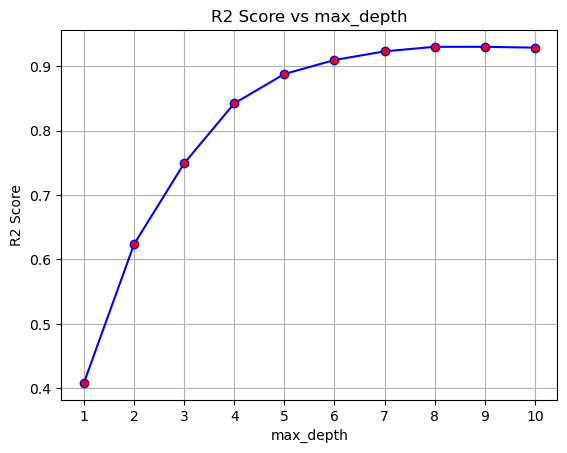

In [85]:
# List to store r2scores
List_r2score = []
# Loop through different values of max_depth
for depth in range(1, 11):
    # Create a DecisionTreeRegressor instance with the specified number of max_depth
    regression_tree = DecisionTreeRegressor(criterion = "absolute_error", max_depth = depth)
    # Fit the DecisionTreeRegressor model to the data
    regression_tree.fit(x_train4, y_train4)
    # Make predictions using the fitted model
    regtree_pred = regression_tree.predict(x_test4)
    # Append the R2 score to the list
    List_r2score.append(r2_score(y_test4, regtree_pred))
# Create a list of depth values
depth_values = [i for i in range(1, 11)]
# Plot the depth values against the number of max_depth
plt.plot(depth_values, List_r2score, marker='o', c='b', mfc='r')
# Set the x-axis label
plt.xlabel("max_depth")
# Set the y-axis label
plt.ylabel("R2 Score")
# Set custom ticks for the x-axis
plt.xticks(np.arange(1, 11, 1))
# Set the title of the plot
plt.title("R2 Score vs max_depth")
# Add grid lines to the plot
plt.grid()
# Display the plot
plt.show()

In [86]:
# Create a DecisionTreeRegressor instance with the specified number of max_depth
regression_tree = DecisionTreeRegressor(criterion = "absolute_error", max_depth=8)
# Fit the DecisionTreeRegressor model to the data
regression_tree.fit(x_train4, y_train4)
# Make predictions using the fitted model
regtree_pred = regression_tree.predict(x_test4)

In [89]:
# Print the evaluation metrics
print("Evaluation Metrics for Decision Tree Regression")
print("==================================================")
print(f"Mean Absolte Error: {mean_absolute_error(y_test4, regtree_pred):.2f}")
print(f"Mean Squared Error: {mean_squared_error(y_test4, regtree_pred):.2f}")
print(f"Root Mean Squared Error: {np.sqrt(mean_squared_error(y_test4, regtree_pred)):.2f}")
print(f"R2 Score: {r2_score(y_test4, regtree_pred):.3f}")

Evaluation Metrics for Decision Tree Regression


Mean Absolte Error: 2272.99

Mean Squared Error: 19020420.67

Root Mean Squared Error: 4361.24

R2 Score: 0.930


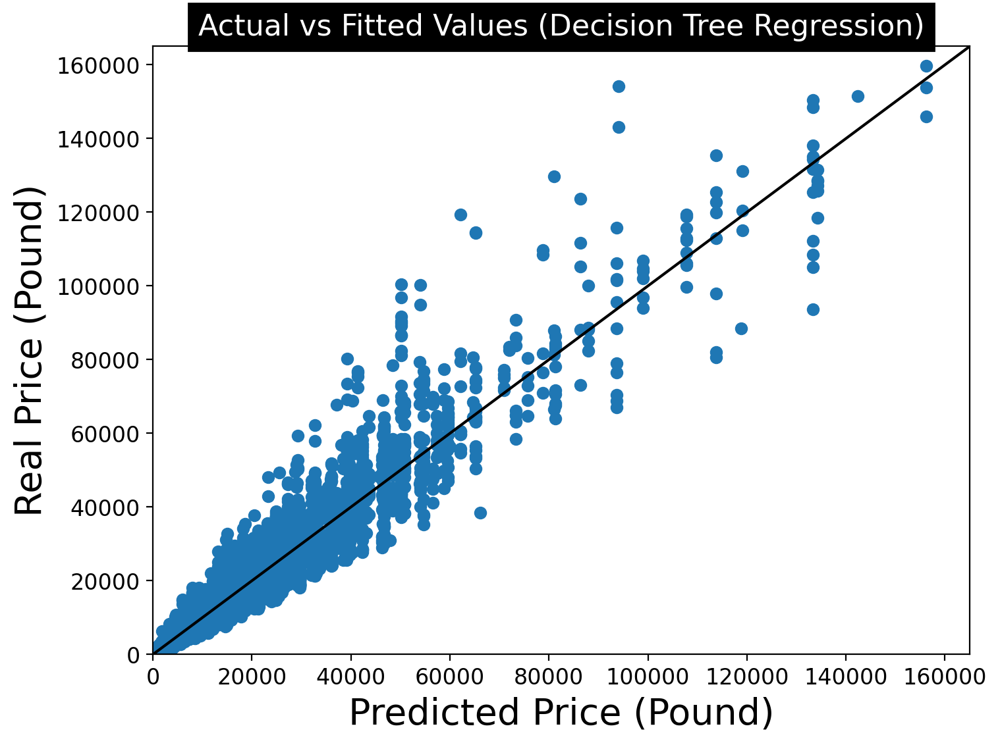

In [90]:
# Set the figure size and DPI for the scatter plot
plt.figure (figsize=(8,6), dpi = 200)
# Scatter plot of predicted prices vs. actual prices
plt.scatter(regtree_pred, y_test4)
# Add a straight diagonal line to the plot.
plt.plot([0, 165000], [0, 165000], 'k-')
# Limit the range of values on both x and y axes
plt.xlim(0, 165000)
plt.ylim(0, 165000)
# Add title to the plot with specified background color, text color, and fontsize
plt.title('Actual vs Fitted Values (Decision Tree Regression)',backgroundcolor='black',color='white',fontsize=16)
# Set x and y axis labels with specified fontsize
plt.xlabel("Predicted Price (Pound)", fontsize = 20)
plt.ylabel("Real Price (Pound)", fontsize = 20)
# Increase the font size of x and y axis ticks
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
# Show the plot
plt.show()

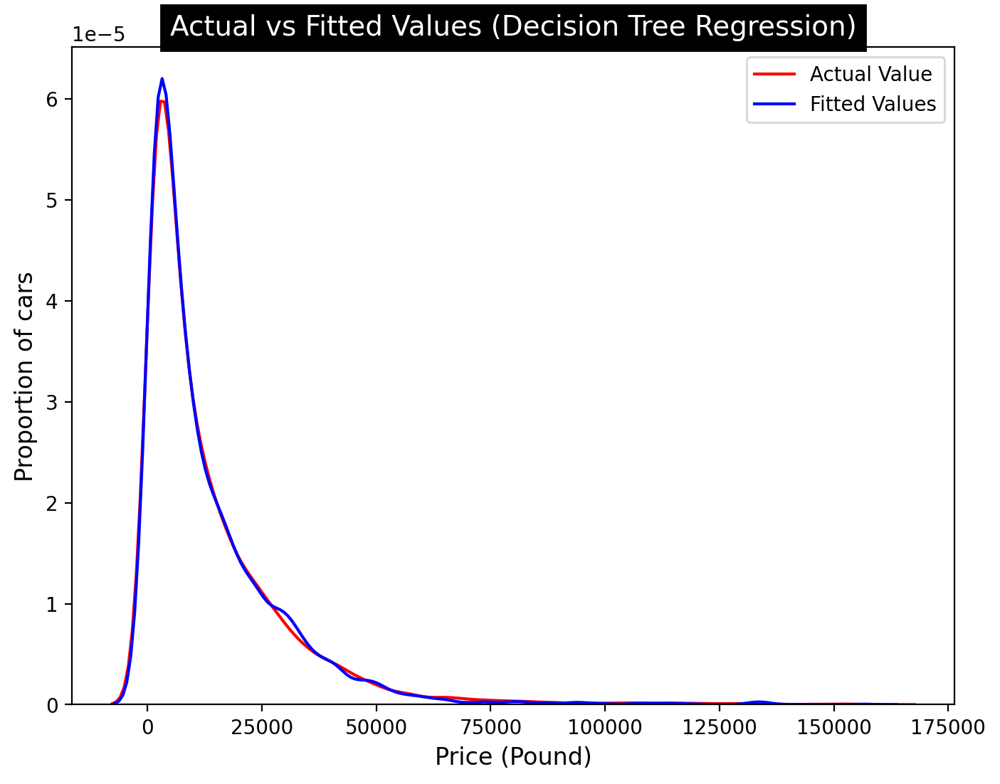

In [91]:
# Plotting the distribution of actual values (y_test4) and fitted values (regtree_pred)
plt.figure (figsize=(8,6), dpi = 200)
ax1 = sns.distplot(y_test4, hist=False, color="r", label="Actual Value")
sns.distplot(regtree_pred, hist=False, color="b", label="Fitted Values", ax=ax1)
# Adding title and labels to the plot
plt.title('Actual vs Fitted Values (Decision Tree Regression)',backgroundcolor='black',color='white',fontsize=14)
plt.xlabel('Price (Pound)', fontsize = 12)
plt.ylabel('Proportion of cars', fontsize = 12)
# Displaying the legend for better interpretation
plt.legend()
# Show the plot
plt.show()

### B3. Support Vector Regression (SVR)

In [92]:
# Create an SVR model
svr_model = SVR(kernel="linear")
# Fit the model to the training data
svr_model.fit(x_train4, y_train4)
# Make predictions on the test set
svr_pred = svr_model.predict(x_test4)

In [93]:
# Print the evaluation metrics
print("Evaluation Metrics for Support Vector Regression")
print("==================================================")
print(f"Mean Absolte Error: {mean_absolute_error(y_test4, svr_pred):.2f}")
print(f"Mean Squared Error: {mean_squared_error(y_test4, svr_pred):.2f}")
print(f"Root Mean Squared Error: {np.sqrt(mean_squared_error(y_test4, svr_pred)):.2f}")
print(f"R2 Score: {r2_score(y_test4, svr_pred):.2f}")

Evaluation Metrics for Support Vector Regression


Mean Absolte Error: 5442.81

Mean Squared Error: 130239613.13

Root Mean Squared Error: 11412.26

R2 Score: 0.52


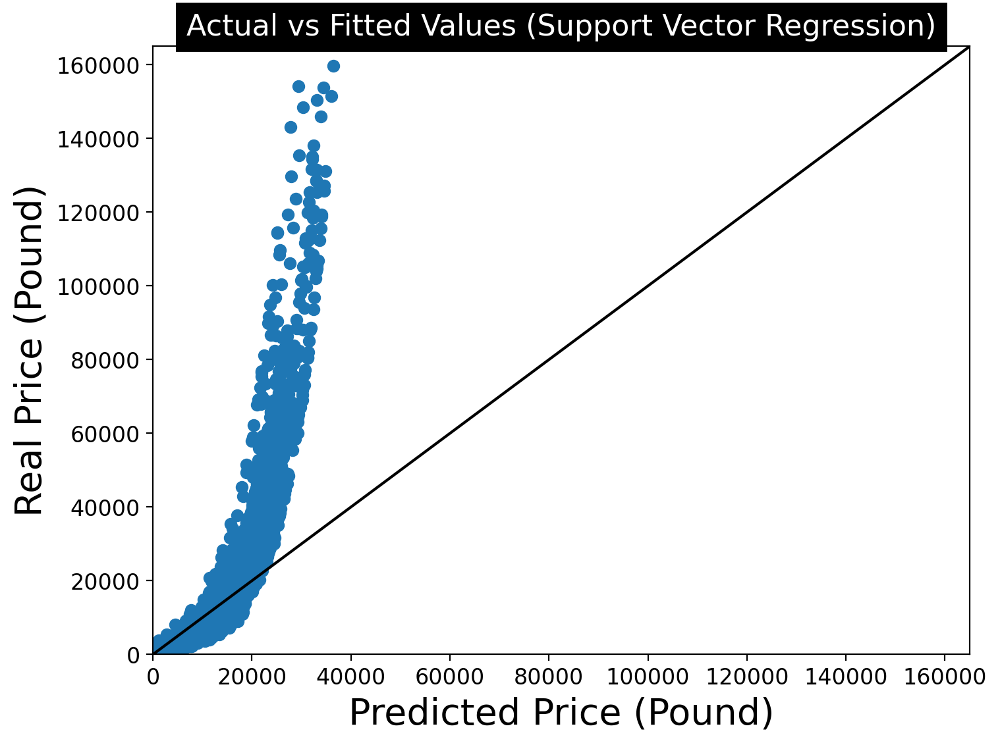

In [94]:
# Set the figure size and DPI for the scatter plot
plt.figure (figsize=(8,6), dpi = 200)
# Scatter plot of predicted prices vs. actual prices
plt.scatter(svr_pred, y_test4)
# Add a straight diagonal line to the plot.
plt.plot([0, 165000], [0, 165000], 'k-')
# Label both axes.
# Limit the range of values on both axes
plt.xlim(0, 165000)
plt.ylim(0, 165000)
# Add title to the plot with specified background color, text color, and fontsize
plt.title('Actual vs Fitted Values (Support Vector Regression)',backgroundcolor='black',color='white',fontsize=16)
# Set x and y axis labels with specified fontsize
plt.xlabel("Predicted Price (Pound)", fontsize = 20)
plt.ylabel("Real Price (Pound)", fontsize = 20)
# Increase the font size of x and y axis ticks
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
# Show the plot
plt.show()

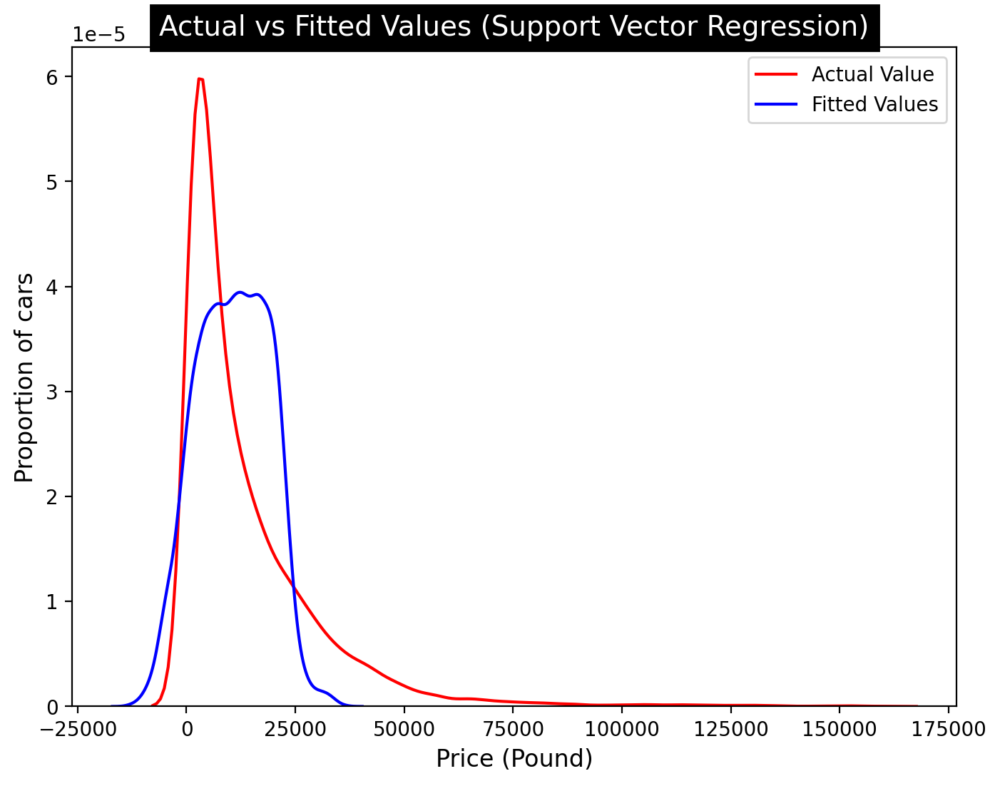

In [95]:
# Plotting the distribution of actual values (y_test4) and fitted values (svr_predictions)
plt.figure (figsize=(8,6), dpi = 200)
ax1 = sns.distplot(y_test4, hist=False, color="r", label="Actual Value")
sns.distplot(svr_pred, hist=False, color="b", label="Fitted Values", ax=ax1)
# Adding title and labels to the plot
plt.title('Actual vs Fitted Values (Support Vector Regression)',backgroundcolor='black',color='white',fontsize=14)
# Set x and y axis labels with specified fontsize
plt.xlabel('Price (Pound)', fontsize = 12)
plt.ylabel('Proportion of cars', fontsize = 12)
# Displaying the legend for better interpretation
plt.legend()
# Show the plot
plt.show()

## C: Multiple Input Regression Models ( using numerical and categorical variables )

In [96]:
# Define terget
y = df["Price"]

In [97]:
# Define a list of feature names
feature_names = ["Year of manufacture", "Mileage", "Engine size"]
# Create a new DataFrame 'x_multi' containing only the selected features
x_numerical = df[feature_names]

In [98]:
# Create an instance of the MinMaxScaler class for scaling numerical features
scale = MinMaxScaler()
# Fit and transform the MinMaxScaler to the numerical features (x_numerical)
x_numerical_scaled = scale.fit_transform(x_numerical)

In [99]:
# Extract the 'Manufacturer', 'Model', and 'Fuel type' columns as categorical data
x_cat = df[['Manufacturer', 'Model', 'Fuel type']]

# Create an instance of the LabelEncoder class for 'Manufacturer'
label1 = LabelEncoder()
# Fit and transform the label encoder to the 'Manufacturer' categorical data
x_cat['Manufacturer'] = label1.fit_transform(x_cat['Manufacturer'])

# Create an instance of the LabelEncoder class for 'Model'
label2 = LabelEncoder()
# Fit and transform the label encoder to the 'Model' categorical data
x_cat['Model'] = label2.fit_transform(x_cat['Model'])

# Create an instance of the LabelEncoder class for 'Fuel type'
label3 = LabelEncoder()
# Fit and transform the label encoder to the 'Fuel type' categorical data
x_cat['Fuel type'] = label3.fit_transform(x_cat['Fuel type'])

In [100]:
# Concatenate the scaled numerical features (x_numerical_scaled) and categorical features (x_cat)
# along the columns (axis=1) to create the combined feature matrix (x_num_cat)
x_num_cat = np.concatenate((x_numerical_scaled, x_cat), axis=1)

In [101]:
# Split the data into training and testing sets
x_train5, x_test5, y_train5, y_test5 = train_test_split(x_num_cat, y, test_size = 0.2, random_state = 42)

### C1. Decision Tree Regression

In [102]:
# Create a DecisionTreeRegressor instance with the specified number of max_depth
regression_tree2 = DecisionTreeRegressor(criterion = "absolute_error", max_depth=8)
# Fit the DecisionTreeRegressor model to the data
regression_tree2.fit(x_train5, y_train5)
# Make predictions using the fitted model
regtree_pred2 = regression_tree2.predict(x_test5)

In [103]:
# Print the evaluation metrics
print("Evaluation Metrics for Decision Tree Regression")
print("==================================================")
print(f"Mean Absolte Error: {mean_absolute_error(y_test5, regtree_pred2):.2f}")
print(f"Mean Squared Error: {mean_squared_error(y_test5, regtree_pred2):.2f}")
print(f"Root Mean Squared Error: {np.sqrt(mean_squared_error(y_test5, regtree_pred2)):.2f}")
print(f"R2 Score: {r2_score(y_test5, regtree_pred2):.2f}")

Evaluation Metrics for Decision Tree Regression


Mean Absolte Error: 1730.44

Mean Squared Error: 8610663.70

Root Mean Squared Error: 2934.39

R2 Score: 0.97


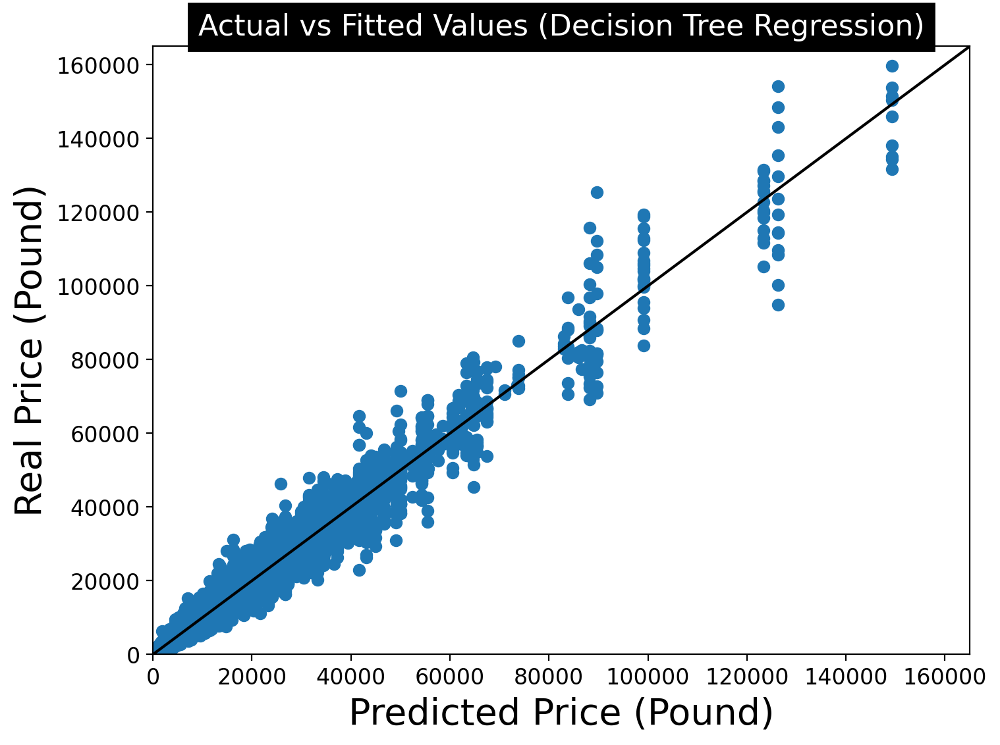

In [104]:
# Set the figure size and DPI for the scatter plot
plt.figure (figsize=(8,6), dpi = 200)
# Scatter plot of predicted prices vs. actual prices
plt.scatter(regtree_pred2, y_test5)
# Add a straight diagonal line to the plot.
plt.plot([0, 165000], [0, 165000], 'k-')
# Limit the range of values on both axes
plt.xlim(0, 165000)
plt.ylim(0, 165000)
# Add title to the plot with specified background color, text color, and fontsize
plt.title('Actual vs Fitted Values (Decision Tree Regression)',backgroundcolor='black',color='white',fontsize=16)
# Set x and y axis labels with specified fontsize
plt.xlabel("Predicted Price (Pound)", fontsize = 20)
plt.ylabel("Real Price (Pound)", fontsize = 20)
# Increase the font size of x and y axis ticks
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
# Show the plot
plt.show()

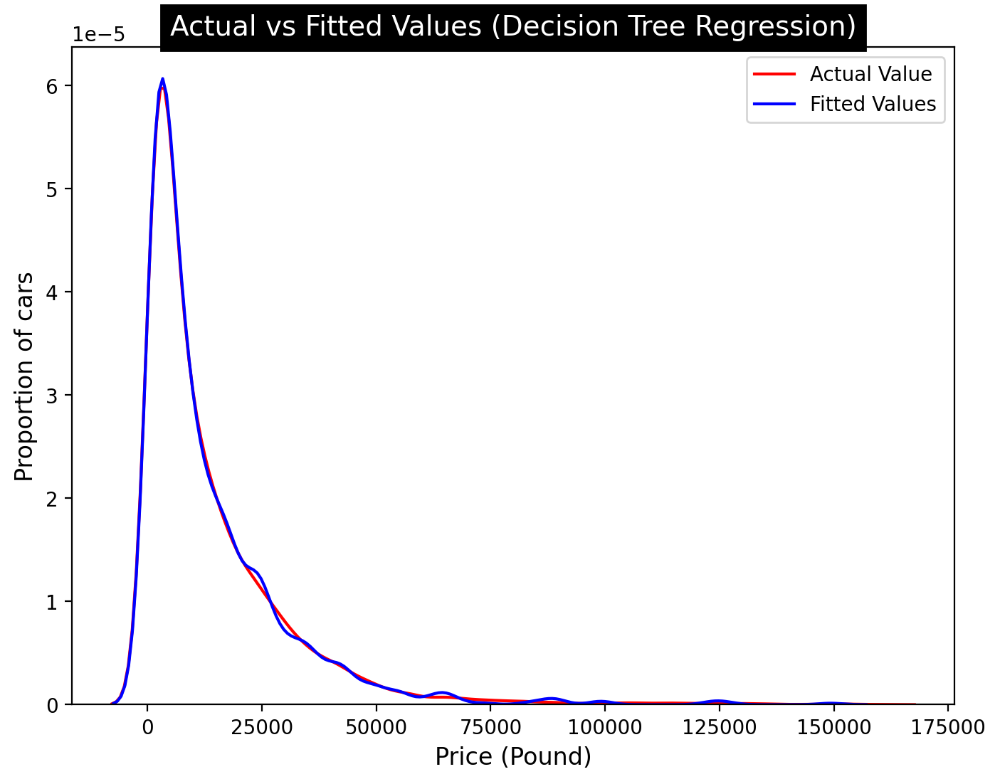

In [105]:
# Plotting the distribution of actual values (y_test4) and fitted values (regtree_pred)
plt.figure (figsize=(8,6), dpi = 200)
ax1 = sns.distplot(y_test5, hist=False, color="r", label="Actual Value")
sns.distplot(regtree_pred2, hist=False, color="b", label="Fitted Values", ax=ax1)
# Adding title and labels to the plot
plt.title('Actual vs Fitted Values (Decision Tree Regression)',backgroundcolor='black',color='white',fontsize=14)
plt.xlabel('Price (Pound)', fontsize = 12)
plt.ylabel('Proportion of cars', fontsize = 12)
# Displaying the legend for better interpretation
plt.legend()
# Show the plot
plt.show()

### C2. Random Forest Regression model

In [118]:
# Define the parameter grid to search
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}
param_grid2 = {
    'n_estimators': [10, 20, 30],
    'max_depth': [None, 10, 20]
}

# Create a RandomForestRegressor
rfr = RandomForestRegressor()

# Instantiate GridSearchCV
grid_search = GridSearchCV(rfr, param_grid2, cv=5, scoring='r2')

# Fit the model to the training data
grid_result = grid_search.fit(x_train5, y_train5)

# Print the best hyperparameters
print("Best Hyperparameters:", grid_search.best_params_)
print("Best Score: ", grid_result.best_score_)

# Make predictions on the test set using the best model
price_pred_rfr = grid_search.best_estimator_.predict(x_test5)

Best Hyperparameters: {'max_depth': None, 'n_estimators': 30}

Best Accuracy:  0.9973374301506557

R2 Score: 0.998


In [106]:
# Create a Random Forest Regression model using optimized hyperparameters
rfr_model = RandomForestRegressor(n_estimators=30, random_state=42, max_depth=None, oob_score=True)

# Fit the rfr_model with X_norm and y
rfr_model.fit(x_train5, y_train5)

# Use the trained linear regression model to make predictions on the test data
price_pred_rfr = rfr_model.predict(x_test5)

In [107]:
# Calculate and print the evaluation metrics
print("Evaluation Metrics for Multiple Linear Regression")
print("==================================================")
print(f"Mean Absolte Error: {mean_absolute_error(y_test5, price_pred_rfr):.2f}")
print(f"Mean Squared Error: {mean_squared_error(y_test5, price_pred_rfr):.2f}")
print(f"Root Mean Squared Error: {np.sqrt(mean_squared_error(y_test5, price_pred_rfr)):.2f}")
print(f"R2 Score: {r2_score(y_test5, price_pred_rfr):.3f}")

Evaluation Metrics for Multiple Linear Regression


Mean Absolte Error: 344.35

Mean Squared Error: 502189.68

Root Mean Squared Error: 708.65

R2 Score: 0.998


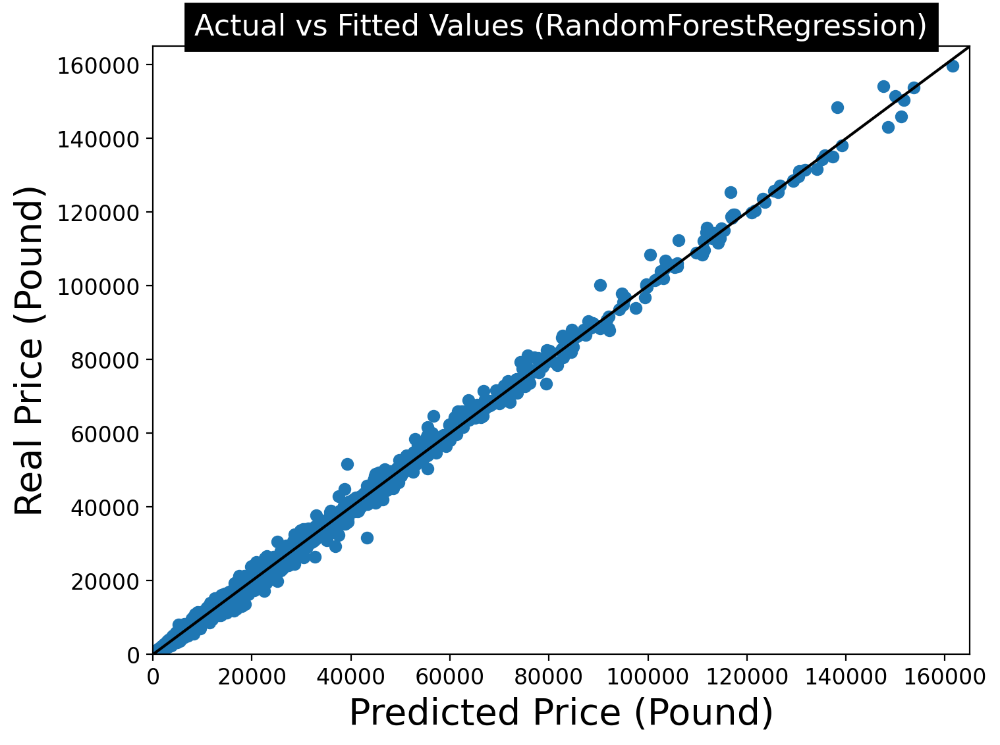

In [108]:
# Set the figure size and DPI for the scatter plot
plt.figure (figsize=(8,6), dpi = 200)
# Scatter plot of predicted prices vs. actual prices
plt.scatter(price_pred_rfr, y_test5)
# Add a straight diagonal line to the plot.
plt.plot([0, 165000], [0, 165000], 'k-')
# Limit the range of values on both axes
plt.xlim(0, 165000)
plt.ylim(0, 165000)
# Add title to the plot with specified background color, text color, and fontsize
plt.title('Actual vs Fitted Values (RandomForestRegression)',backgroundcolor='black',color='white',fontsize=16)
# Set x and y axis labels with specified fontsize
plt.xlabel("Predicted Price (Pound)", fontsize = 20)
plt.ylabel("Real Price (Pound)", fontsize = 20)
# Increase the font size of x and y axis ticks
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
# Show the plot
plt.show()

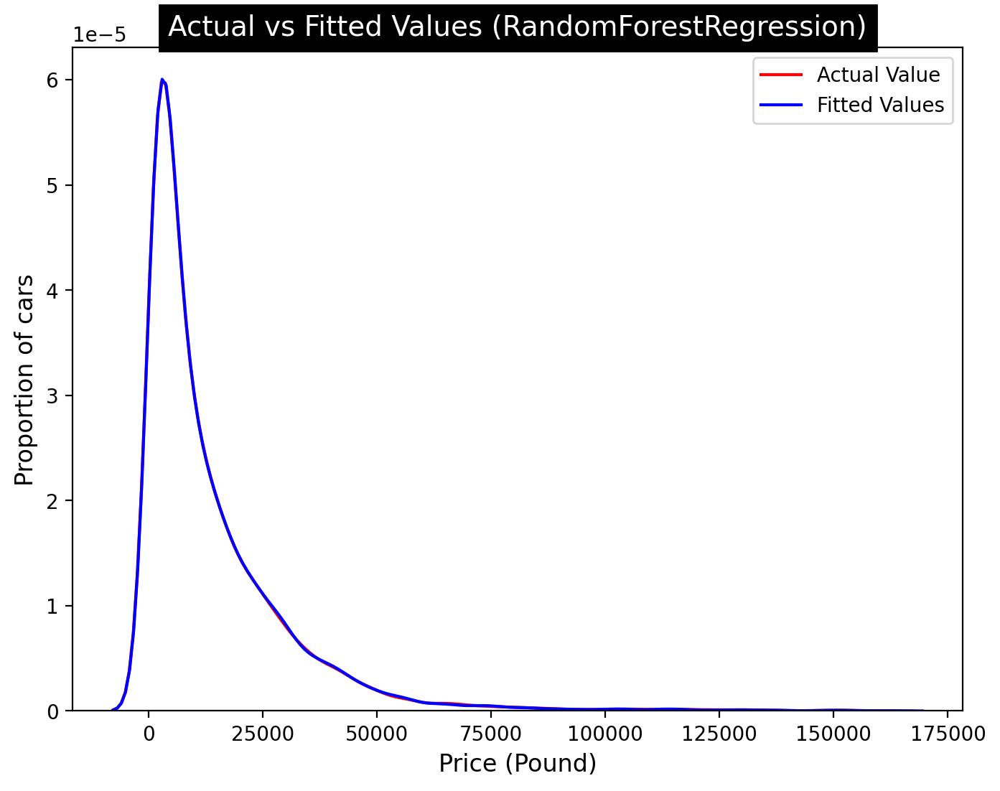

In [109]:
# Plotting the distribution of actual values (y_test4) and fitted values (price_pred_rfr)
plt.figure (figsize=(8,6), dpi = 200)
ax1 = sns.distplot(y_test5, hist=False, color="r", label="Actual Value")
sns.distplot(price_pred_rfr, hist=False, color="b", label="Fitted Values", ax=ax1)
# Adding title and labels to the plot
plt.title('Actual vs Fitted Values (RandomForestRegression)',backgroundcolor='black',color='white',fontsize=14)
plt.xlabel('Price (Pound)', fontsize = 12)
plt.ylabel('Proportion of cars', fontsize = 12)
# Displaying the legend for better interpretation
plt.legend()
# Show the plot
plt.show()

## D: Artifitial Neural Network (ANN)

A final output layer that uses the linear activation function, as we are considering a regression problem that predicts a continuous output variable.

In [10]:
# Define terget
y = df["Price"]

In [11]:
# Extract a list of numerical column names
feature_names = ["Year of manufacture", "Mileage", "Engine size"]
# Create a new DataFrame containing the selected features
x_numerical = df[feature_names]

In [12]:
# Create an instance of the MinMaxScaler class for scaling numerical features
scale = MinMaxScaler()
# Fit and transform the MinMaxScaler to the numerical features (x_numerical)
x_numerical_scaled = scale.fit_transform(x_numerical)

In [13]:
# Extract the 'Manufacturer', 'Model', and 'Fuel type' columns as categorical data
x_cat = df[['Manufacturer', 'Model', 'Fuel type']]

# Create an instance of the LabelEncoder class for 'Manufacturer'
label1 = LabelEncoder()
# Fit and transform the label encoder to the 'Manufacturer' categorical data
x_cat['Manufacturer'] = label1.fit_transform(x_cat['Manufacturer'])

# Create an instance of the LabelEncoder class for 'Model'
label2 = LabelEncoder()
# Fit and transform the label encoder to the 'Model' categorical data
x_cat['Model'] = label2.fit_transform(x_cat['Model'])

# Create an instance of the LabelEncoder class for 'Fuel type'
label3 = LabelEncoder()
# Fit and transform the label encoder to the 'Fuel type' categorical data
x_cat['Fuel type'] = label3.fit_transform(x_cat['Fuel type'])

In [14]:
# Concatenate the scaled numerical features (x_numerical_scaled) and categorical features (x_cat)
# along the columns (axis=1) to create the combined feature matrix (x_num_cat)
x_num_cat = np.concatenate((x_numerical_scaled, x_cat), axis=1)

In [15]:
# Split the data into training and testing sets
x_train5, x_test5, y_train5, y_test5 = train_test_split(x_num_cat, y, test_size = 0.2, random_state = 42)

In [16]:
# Define a function to create an Artificial Neural Network (ANN) configuration
def get_model(layers=2, units=32, learning_rate=0.001, activation='relu', dropout=0.2):
    """
    Create and configure an Artificial Neural Network (ANN) model for regression.

    Parameters:
    - layers (int): Number of hidden layers in the network.
    - units (int): Number of units/neurons in each hidden layer.
    - learning_rate (float): Learning rate for the Adam optimizer.
    - activation (str): Activation function used for hidden layers.
    - dropout (float): Dropout rate for preventing overfitting in the first hidden layer.

    Returns:
    - model (Sequential): Configured ANN model for regression.

    This function creates an ANN model with specified parameters for regression.
    It includes the choice of number of layers, units in each layer,
    learning rate, activation function, and dropout rate for the first hidden layer.
    The model is compiled using the mean squared error as the loss function.
    The summary of the model architecture is printed, and the configured model is returned.
    """
    # Choose the Adam optimizer with the specified learning rate
    optimizer = Adam(learning_rate=learning_rate)
    
    # Create an instance of the Sequential class for building the model
    model = Sequential()
    
    # Add the first hidden layer with specified units, input dimension, and activation function
    model.add(Dense(units, input_dim=6, activation=activation))
    
    # Specify a dropout rate for the first hidden layer to prevent overfitting
    model.add(Dropout(dropout))
    
    # Add additional hidden layers based on the specified number of layers
    for i in range(layers - 1):
        model.add(Dense(units, activation=activation))
    
    # Add the output layer with 1 output node and linear activation for regression
    model.add(Dense(1, activation='linear'))
    
    # Compile the model using Adam optimizer, mean squared error as the loss function, and mean squared error as a metric
    model.compile(optimizer=optimizer, loss='mean_squared_error', metrics=['mean_squared_error'])
    
    # Display a summary of the model architecture
    print(model.summary())
    
    # Return the configured model
    return model

In [17]:
# Define train_model() funaction to train the model
def train_model (x_train, y_train, model, epochs = 200):
    """
    Train an Artificial Neural Network (ANN) model using the provided training data.

    Parameters:
    - x_train (array-like): Input features for training the model.
    - y_train (array-like): Target values for training the model.
    - model (Sequential): ANN model to be trained.
    - epochs (int): Number of epochs for training.

    Returns:
    - history (History): Training history containing loss values and metrics.

    This function trains an ANN model using the provided input features (x_train)
    and target values (y_train5). The training is performed with the specified number
    of epochs. Early stopping is applied with a patience of 20 to monitor validation loss.
    The training history, containing loss values and metrics, is returned.
    """
    # Record the starting time for measuring the total runtime
    start = time.time()

    # Apply early stopping to prevent overfitting
    early_stopping = EarlyStopping(monitor='val_loss', patience=20)
    
    # Train the model using the provided training data
    history = model.fit(x=x_train, y=y_train, batch_size=None,
                        epochs=epochs, verbose="auto",
                        validation_split=0.1, callbacks=[early_stopping])
    
    # Calculate the total runtime and print the result
    tot_time = time.time() - start
    print(f"\nTotal Runtime: {tot_time:.2f} s ({(tot_time/60):.2f} min)")
    
    # Return the training history
    return history

In [18]:
# Plot ANN Measures for the model
def Plot_measures (price_pred_ann, y_test, history):
    """
    Plot evaluation measures and visualizations for an Artificial Neural Network (ANN) model.

    Parameters:
    - price_pred_ann (array-like): Predicted prices generated by the ANN model.
    - y_test (array-like): Actual prices from the test set.
    - history (History): Training history of the ANN model.

    This function generates and displays two plots:
    1. A scatter plot of predicted prices vs. actual prices with a diagonal reference line.
    2. A line plot of training and validation loss over epochs.

    Additionally, it prints evaluation metrics for the ANN model, including:
    - Mean Absolute Error
    - Mean Squared Error
    - Root Mean Squared Error
    - R2 Score
    """
    # Convert training history to a DataFrame for easy plotting and analysis
    history_df = pd.DataFrame(history.history)

    # Scatter Plot
    plt.figure(figsize=(8, 6), dpi=200)
    plt.scatter(price_pred_ann, y_test)
    plt.plot([0, 165000], [0, 165000], 'k-')  # Add a straight diagonal line to the plot.
    plt.title("Real price VS Predicted price", backgroundcolor='black', color='white', fontsize=14)
    plt.xlabel('Predicted Price (Pound)', fontsize=12)
    plt.xticks(np.arange(0, 160001, 25000), rotation=-45)
    plt.xlim(0, 165000)  # Limit x-axis range
    plt.ylabel('Real price (Pound)', fontsize=12)
    plt.ylim(0, 165000)  # Limit y-axis range
    plt.show()

    # Loss Plot
    plt.figure(figsize=(8, 6), dpi=200)
    plt.plot(history_df["loss"], label="Training")
    plt.plot(history_df["val_loss"], label="Validation")
    plt.title("Loss training VS Validation", backgroundcolor='black', color='white', fontsize=14)
    plt.legend()
    plt.xlabel('Epoch', fontsize=12)
    plt.ylabel('Loss = Mean Squared Error', fontsize=12)
    plt.show()

    # Print evaluation metrics for the ANN model
    print("Evaluation Metrics for ANN model")
    print("==================================================")
    print(f"Mean Absolte Error: {mean_absolute_error(y_test, price_pred_ann):.4f}")
    print(f"Mean Squared Error: {history_df.iloc[-1, 1]:.4f}")
    print(f"Root Mean Squared Error: {np.sqrt(history_df.iloc[-1, 1]):.4f}")
    print(f"R2 Score: {r2_score(y_test, price_pred_ann):.4f}")

#### Model with 2 hidden layers

In [25]:
# Define a model configuration with '2 hidden layers'
model = get_model(layers=2, units=64, learning_rate=0.001, activation='relu', dropout=0.2)

# Train the model with the specified configuration
history = train_model(x_train5, y_train5, model, epochs=200)

# Make predictions using the trained model on the test data
price_pred_ann = model.predict(x_test5)




Model: "sequential"

_________________________________________________________________

 Layer (type)                Output Shape              Param #   


 dense (Dense)               (None, 64)                448       

                                                                 

 dropout (Dropout)           (None, 64)                0         

                                                                 

 dense_1 (Dense)             (None, 64)                4160      

                                                                 

 dense_2 (Dense)             (None, 1)                 65        

                                                                 


Total params: 4673 (18.25 KB)

Trainable params: 4673 (18.25 KB)

Non-trainable params: 0 (0.00 Byte)

_________________________________________________________________

None

Epoch 1/200







1125/1125 [==============================] - 2s 1ms/step - loss: 327576672.0000 - mean_squared_error: 3275766

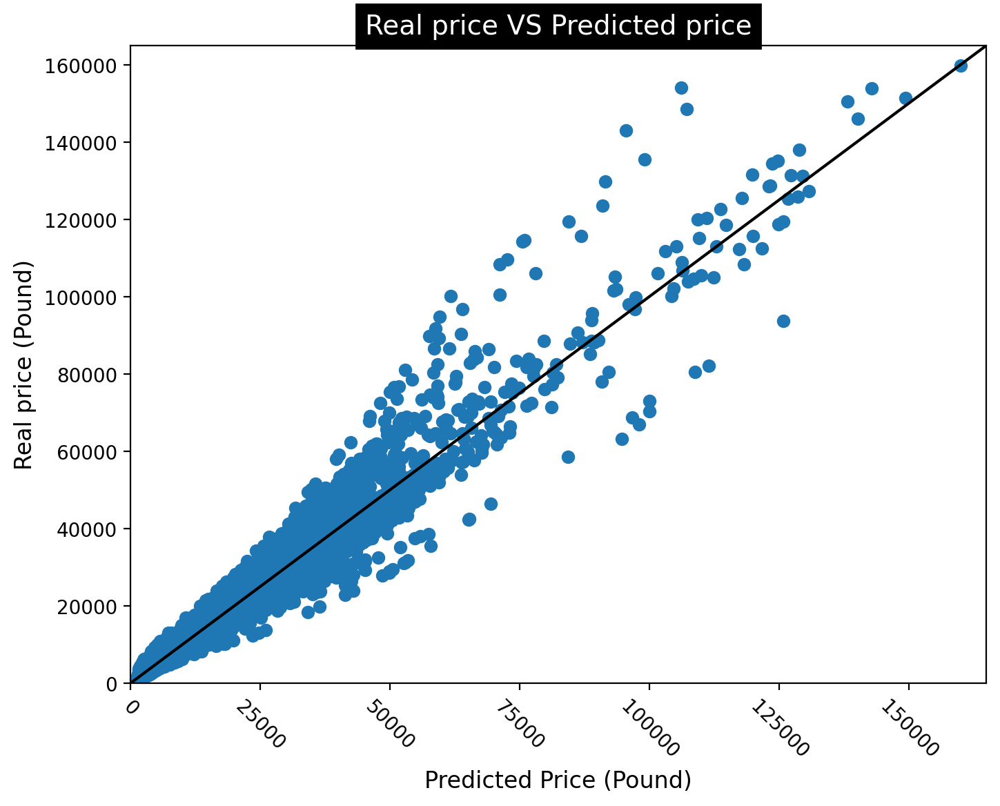

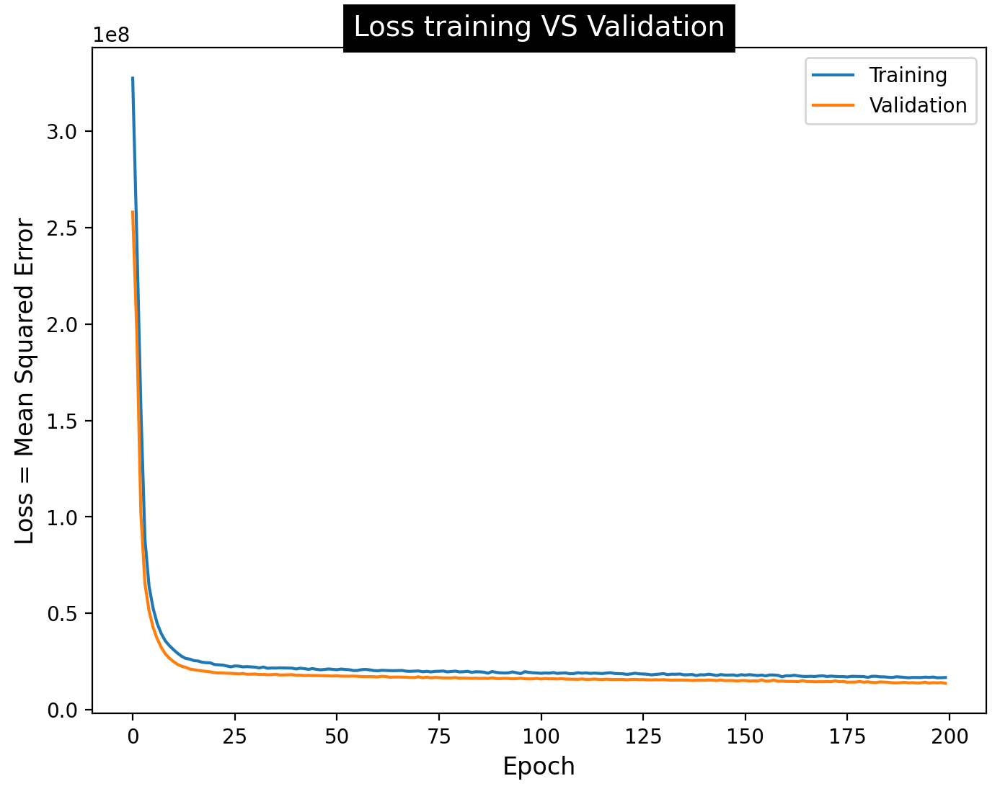

Evaluation Metrics for ANN model


Mean Absolte Error: 2015.4307

Mean Squared Error: 16680332.0000

Root Mean Squared Error: 4084.1562

R2 Score: 0.9484


In [28]:
# Plot measures for the ANN model
Plot_measures(price_pred_ann, y_test5, history)

#### Model with 3 hidden layers

In [29]:
# Define a model configuration with '3 hidden layers'
model = get_model(layers=3, units=64, learning_rate=0.001, activation='relu', dropout=0.2)

# Train the model with the specified configuration
history = train_model(x_train5, y_train5, model, epochs=200)

# Make predictions using the trained model on the test data
price_pred_ann = model.predict(x_test5)

Model: "sequential_1"

_________________________________________________________________

 Layer (type)                Output Shape              Param #   


 dense_3 (Dense)             (None, 64)                448       

                                                                 

 dropout_1 (Dropout)         (None, 64)                0         

                                                                 

 dense_4 (Dense)             (None, 64)                4160      

                                                                 

 dense_5 (Dense)             (None, 64)                4160      

                                                                 

 dense_6 (Dense)             (None, 1)                 65        

                                                                 


Total params: 8833 (34.50 KB)

Trainable params: 8833 (34.50 KB)

Non-trainable params: 0 (0.00 Byte)

_________________________________________________________________

N

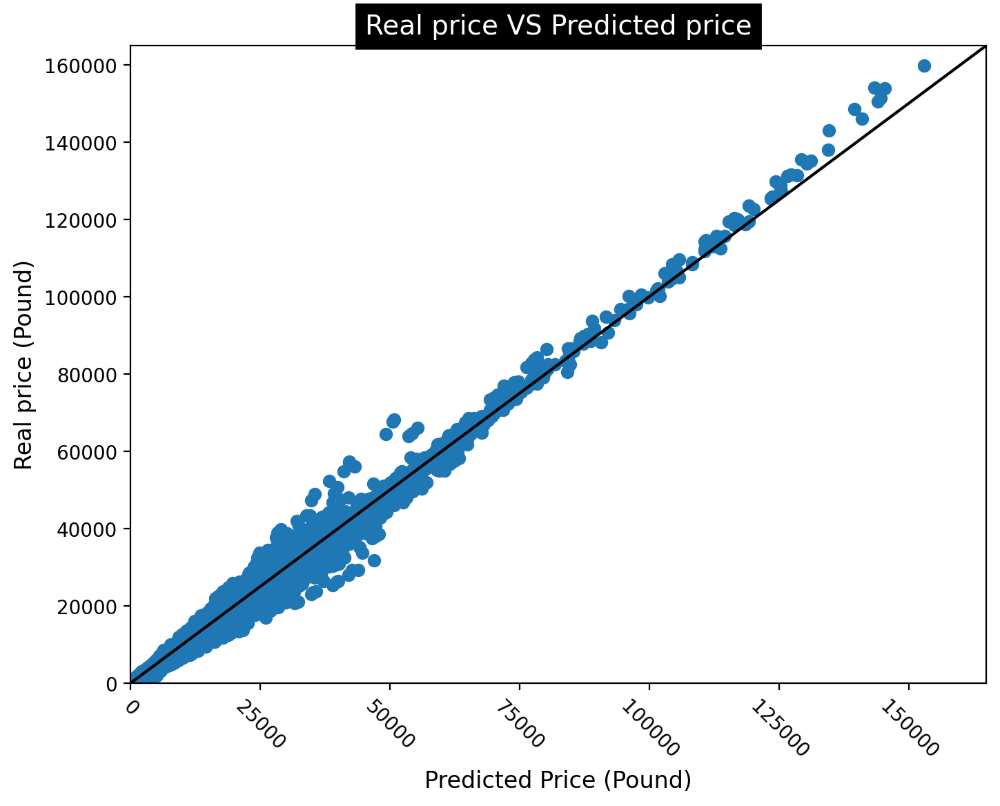

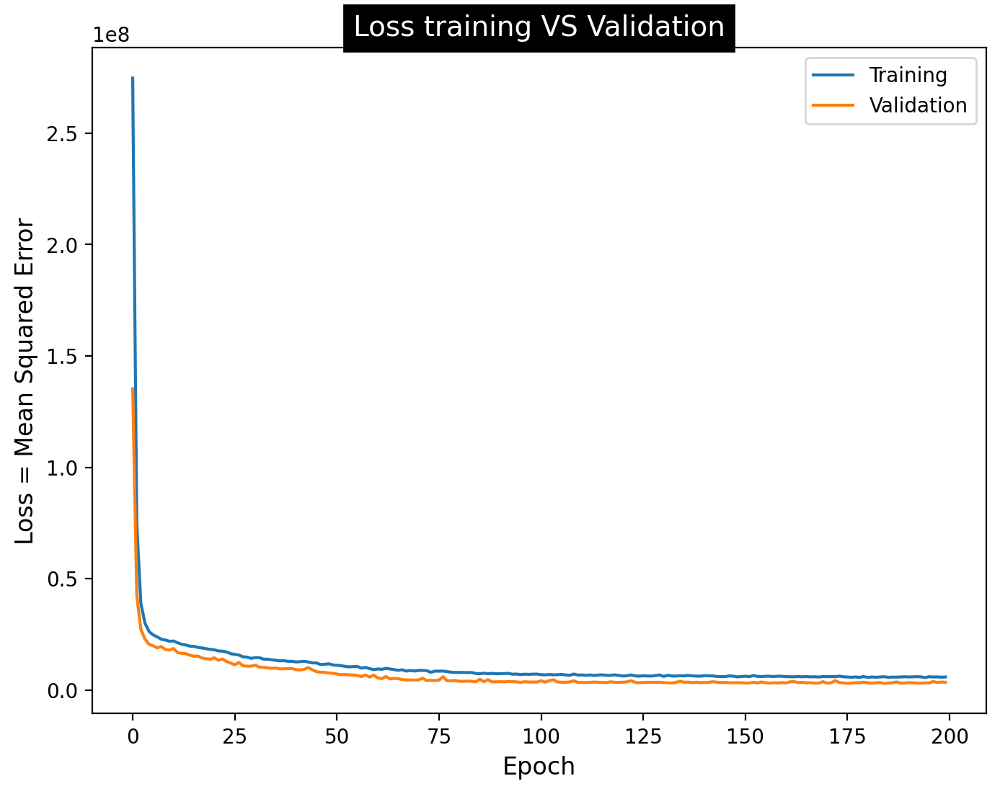

Evaluation Metrics for ANN model


Mean Absolte Error: 1179.5651

Mean Squared Error: 5851082.5000

Root Mean Squared Error: 2418.9011

R2 Score: 0.9874


In [30]:
# Plot measures for the ANN model
Plot_measures (price_pred_ann, y_test5, history)

The predicted price is now much closer to the actual values than what we saw in the previous model.
The history of the training and validation losses also shows a drop with much steep slope. However, the early
stopping criterion was not triggered again. We will therefore continue with this architecture, using three hidden layers.

#### Learning rate = 0.01

In [19]:
# Define a model configuration with '3 hidden layers' and 'learning_rate = 0.01'
model = get_model(layers=3, units=64, learning_rate=0.01, activation='relu', dropout=0.2)

# Train the model with the specified configuration
history = train_model(x_train5, y_train5, model, epochs=200)

# Make predictions using the trained model on the test data
price_pred_ann = model.predict(x_test5)




Model: "sequential"

_________________________________________________________________

 Layer (type)                Output Shape              Param #   


 dense (Dense)               (None, 64)                448       

                                                                 

 dropout (Dropout)           (None, 64)                0         

                                                                 

 dense_1 (Dense)             (None, 64)                4160      

                                                                 

 dense_2 (Dense)             (None, 64)                4160      

                                                                 

 dense_3 (Dense)             (None, 1)                 65        

                                                                 


Total params: 8833 (34.50 KB)

Trainable params: 8833 (34.50 KB)

Non-trainable params: 0 (0.00 Byte)

_________________________________________________________________



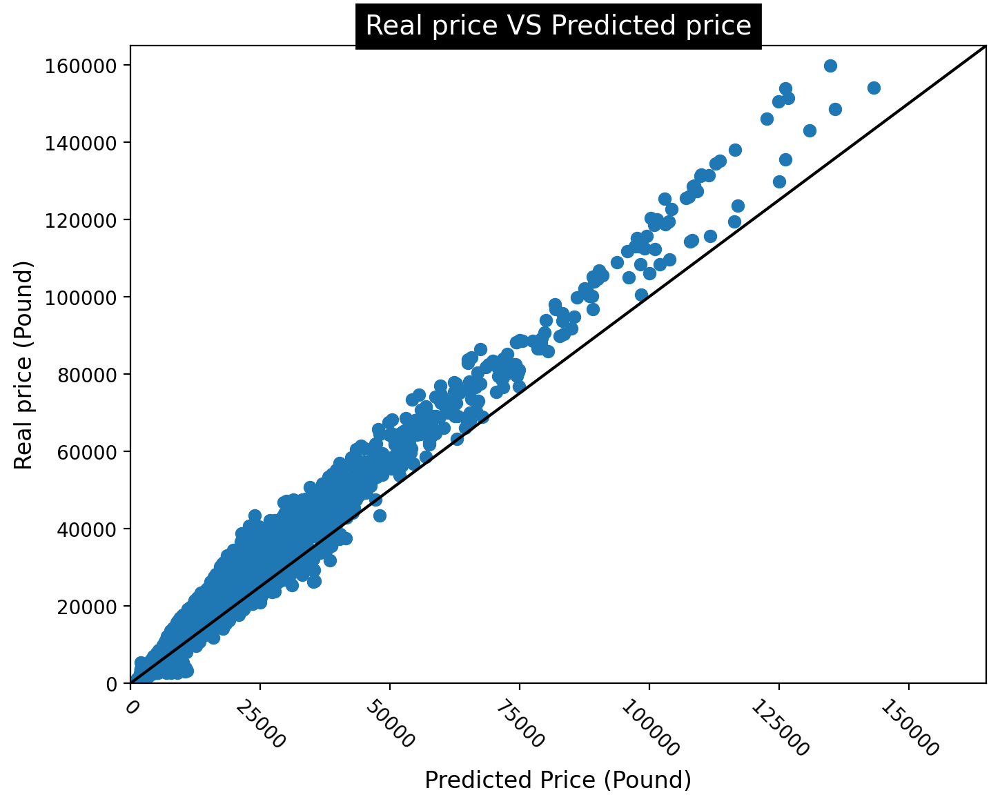

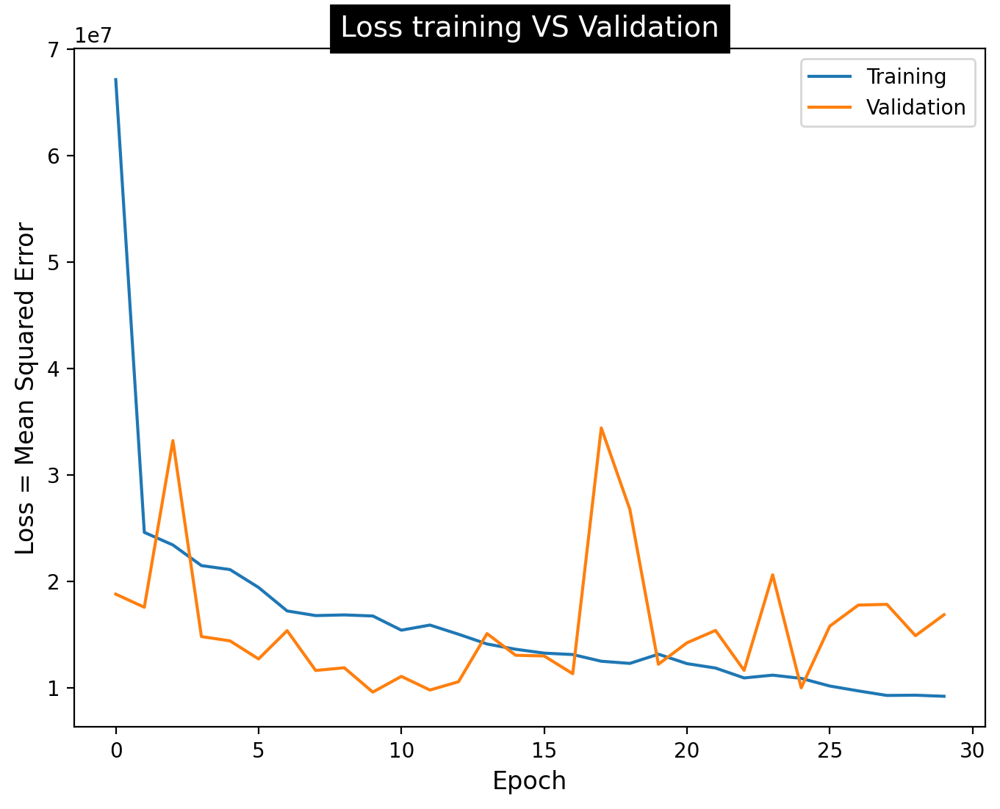

Evaluation Metrics for ANN model


Mean Absolte Error: 2615.5415

Mean Squared Error: 9198375.0000

Root Mean Squared Error: 3032.8823

R2 Score: 0.9379


In [20]:
# Plot measures for the ANN model
Plot_measures(price_pred_ann, y_test5, history)

The model trains faster with a larger learning rate, but may not improve the errors and can sometimes produce worse predicted values. As an alternative approach, try repeating this model with a smaller learning rate.

#### Learning rate = 0.0001

In [21]:
# Define a model configuration with '3 hidden layers' and 'learning_rate = 0.0001'
model = get_model(layers=3, units=64, learning_rate=0.0001, activation='relu', dropout=0.2)

# Train the model with the specified configuration
history = train_model(x_train5, y_train5, model, epochs=200)

# Make predictions using the trained model on the test data
price_pred_ann = model.predict(x_test5)

Model: "sequential_1"

_________________________________________________________________

 Layer (type)                Output Shape              Param #   


 dense_4 (Dense)             (None, 64)                448       

                                                                 

 dropout_1 (Dropout)         (None, 64)                0         

                                                                 

 dense_5 (Dense)             (None, 64)                4160      

                                                                 

 dense_6 (Dense)             (None, 64)                4160      

                                                                 

 dense_7 (Dense)             (None, 1)                 65        

                                                                 


Total params: 8833 (34.50 KB)

Trainable params: 8833 (34.50 KB)

Non-trainable params: 0 (0.00 Byte)

_________________________________________________________________

N

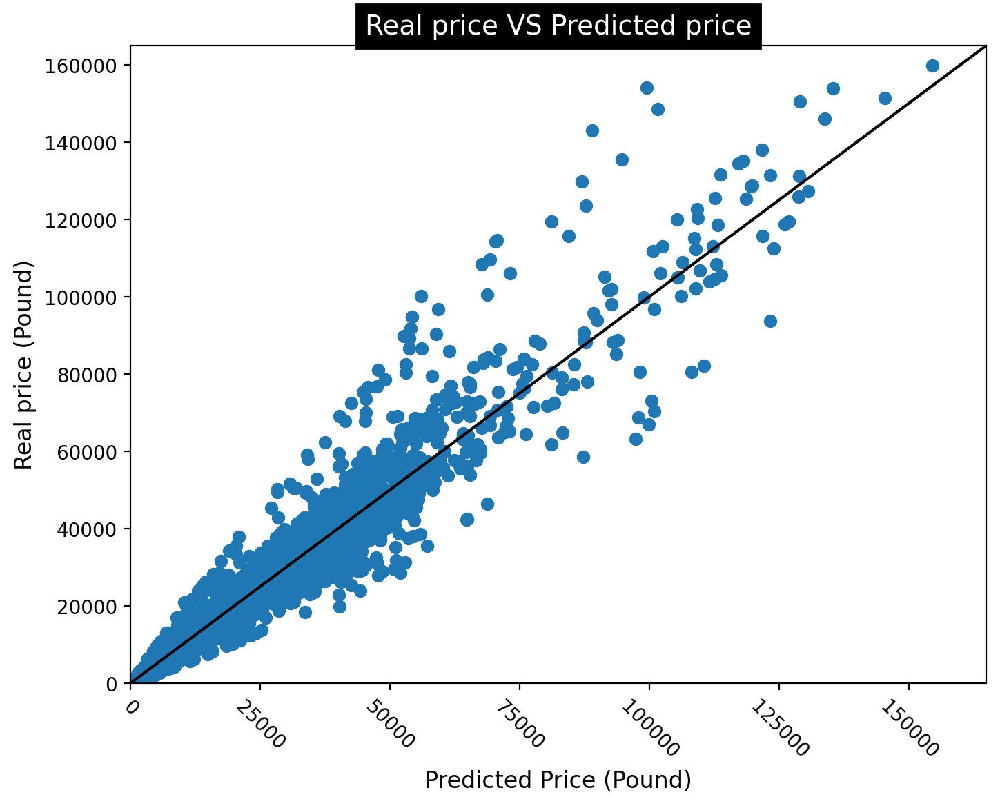

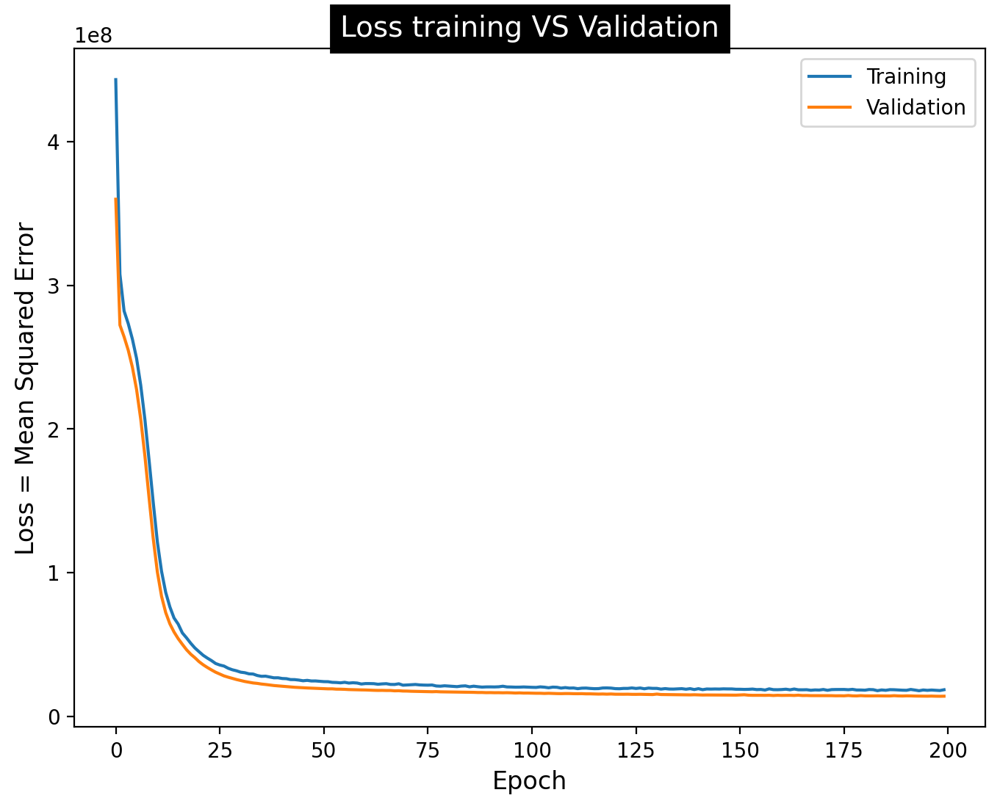

Evaluation Metrics for ANN model


Mean Absolte Error: 1948.4192

Mean Squared Error: 18517510.0000

Root Mean Squared Error: 4303.1976

R2 Score: 0.9450


In [22]:
# Plot measures for the ANN model
Plot_measures(price_pred_ann, y_test5, history)

It seems like with a smaller learning rate, the model predictions did not improve. After conducting these tests, it appears that the optimal value for the learning rate is the default value that was initially set at 0.001. Therefore, it's best to continue with this value.

The other hyperparameter to consider is the drop out rate that we applied in the first hidden layer. We would implement the neural network model with a drop out of 0.1.

#### dropout = 0.1

In [43]:
# Define a model configuration with '3 hidden layers' and 'dropout = 0.1'
model = get_model(layers=3, units=64, learning_rate=0.001, activation='relu', dropout=0.1)

# Train the model with the specified configuration
history = train_model(x_train5, y_train5, model, epochs=200)

# Make predictions using the trained model on the test data
price_pred_ann = model.predict(x_test5)

Model: "sequential_8"

_________________________________________________________________

 Layer (type)                Output Shape              Param #   


 dense_30 (Dense)            (None, 64)                448       

                                                                 

 dropout_8 (Dropout)         (None, 64)                0         

                                                                 

 dense_31 (Dense)            (None, 64)                4160      

                                                                 

 dense_32 (Dense)            (None, 64)                4160      

                                                                 

 dense_33 (Dense)            (None, 1)                 65        

                                                                 


Total params: 8833 (34.50 KB)

Trainable params: 8833 (34.50 KB)

Non-trainable params: 0 (0.00 Byte)

_________________________________________________________________

N

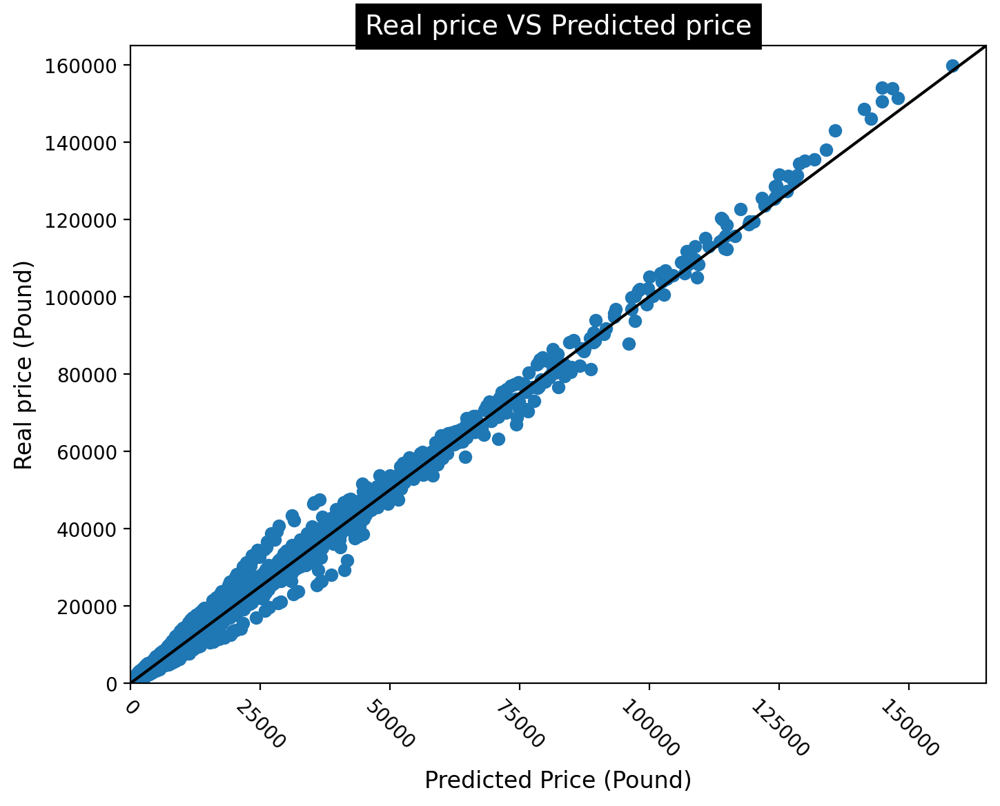

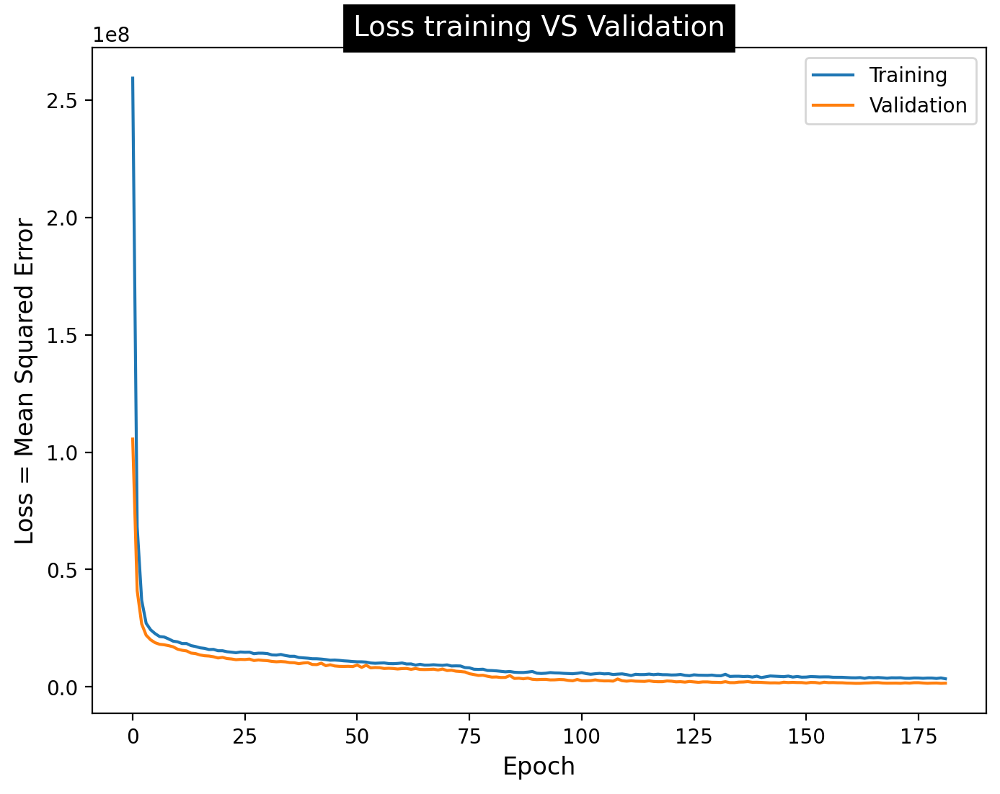

Evaluation Metrics for ANN model


Mean Absolte Error: 687.5224

Mean Squared Error: 3472716.0000

Root Mean Squared Error: 1863.5225

R2 Score: 0.9945


In [44]:
# Plot measures for the ANN model
Plot_measures(price_pred_ann, y_test5, history)

Here metric values are improved.

#### dropout = 0.3

In [35]:
# Define a model configuration with '3 hidden layers' and 'dropout = 0.3'
model = get_model(layers=3, units=64, learning_rate=0.001, activation='relu', dropout=0.3)

# Train the model with the specified configuration
history = train_model(x_train5, y_train5, model, epochs=200)

# Make predictions using the trained model on the test data
price_pred_ann = model.predict(x_test5)

Model: "sequential_4"

_________________________________________________________________

 Layer (type)                Output Shape              Param #   


 dense_14 (Dense)            (None, 64)                448       

                                                                 

 dropout_4 (Dropout)         (None, 64)                0         

                                                                 

 dense_15 (Dense)            (None, 64)                4160      

                                                                 

 dense_16 (Dense)            (None, 64)                4160      

                                                                 

 dense_17 (Dense)            (None, 1)                 65        

                                                                 


Total params: 8833 (34.50 KB)

Trainable params: 8833 (34.50 KB)

Non-trainable params: 0 (0.00 Byte)

_________________________________________________________________

N

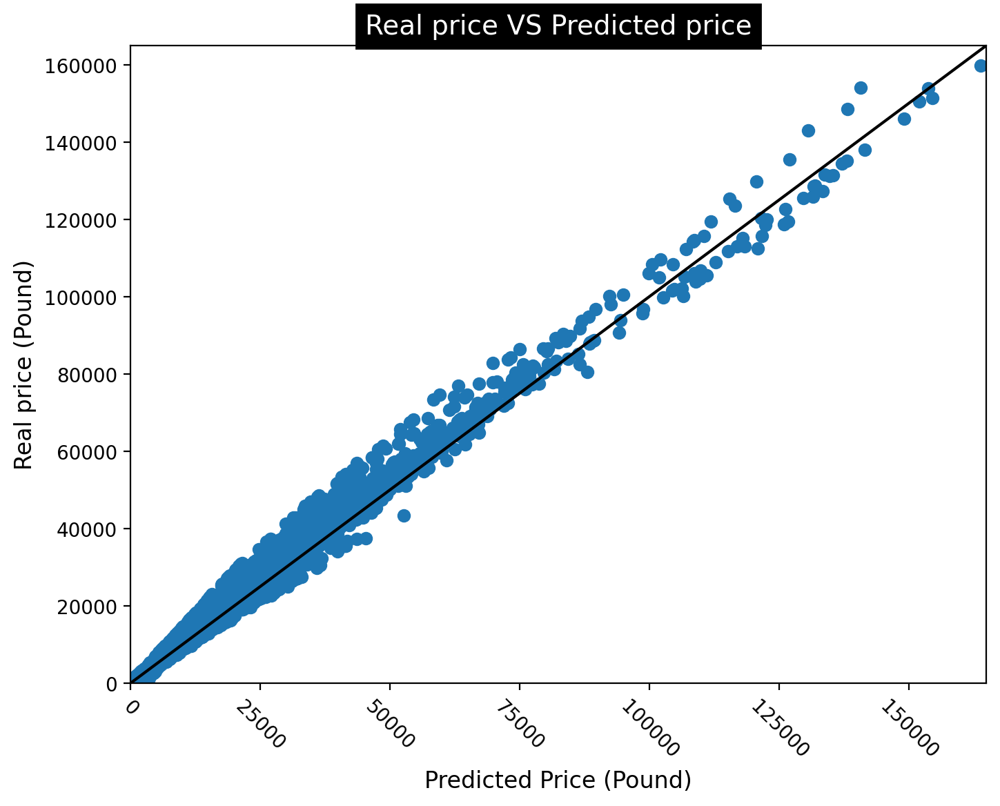

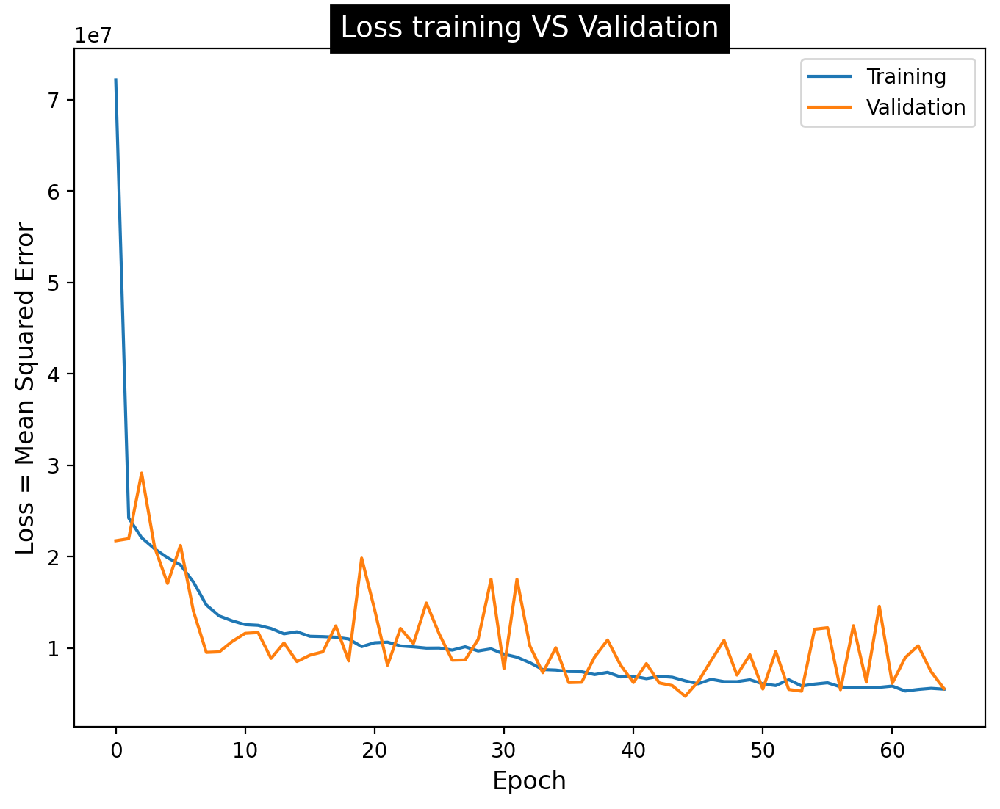

Evaluation Metrics for ANN model


Mean Absolte Error: 1449.3249

Mean Squared Error: 5504038.5000

Root Mean Squared Error: 2346.0687

R2 Score: 0.9796


In [36]:
# Plot measures for the ANN model
Plot_measures(price_pred_ann, y_test5, history)

Although the model trained too early, but the losses have not improved.

## F : Unsupervised learning models to identify clustering patterns

### k-Means Clustering – Year of manufacture versus Price

In [4]:
# select the columns
feature_names = ["Year of manufacture", "Price"]
# create a new DataFrame x_cl using selected the columns (feature_names)
x_cl = df[feature_names]

In [5]:
# Create a StandardScaler instance
scale_cl = StandardScaler()
# Fit the scaler to the data and transform the data
x_cl_scaled = scale_cl.fit_transform(x_cl)

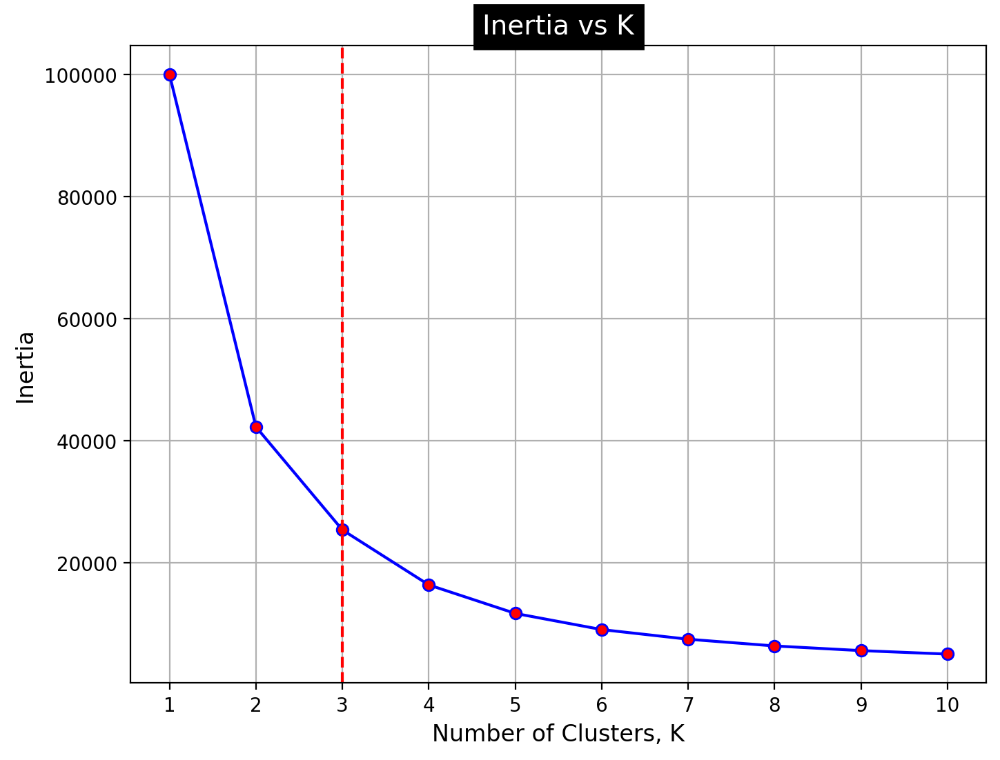

In [6]:
# List to store inertia scores
List_inertia = []

# Loop through different values of K
for k in range(1, 11):
    # Create a KMeans instance with the specified number of clusters (K)
    kmeans = KMeans(n_clusters = k, random_state = 42)
    # Fit the KMeans model to the data
    kmeans.fit(x_cl_scaled)
    # Append the inertia score to the list
    List_inertia.append(kmeans.inertia_)

# Create a list of K values
k_values = [i for i in range(1, 11)]
# Creating a KneeLocator instance to find the knee point
k1 = KneeLocator (range(1,11), List_inertia, curve = 'convex', direction = 'decreasing')
# Plot the inertia values against the number of clusters (K)
plt.figure(figsize=(8, 6), dpi=200)
plt.plot(k_values, List_inertia, marker='o', c='b', mfc='r')
# Adding a vertical dashed line at the identified elbow point
plt.axvline (x = k1.elbow, color = 'r', label = 'axvline - full height', ls = '--')
plt.xlabel("Number of Clusters, K", fontsize = 12)
plt.ylabel("Inertia", fontsize = 12)
plt.xticks(np.arange(1, 11, 1))
plt.title("Inertia vs K", backgroundcolor='black', color='white', fontsize=14)
plt.grid()
# Display the plot
plt.show()

__Note:__ the optimal value of k corresponds to the ”elbow” of this plot, i.e. where it starts to flatten out. 
From this plot, we see the best value to use is k=3.

We will now fit our final k-Means model, using the optimal number of clusters (k = 3) that we determined above. We will then record the cluster labels that this model predicts for each point in our dataset.

In [7]:
# Specify the number of clusters (k)
k = 3
# Create a KMeans instance with the specified number of clusters
kmeans_final = KMeans(n_clusters = k, random_state = 42)
# Fit the KMeans model to the scaled data
kmeans_labels_pred = kmeans_final.fit_predict(x_cl_scaled)

In [8]:
# Print a header for the section
print("Internal Evaluation Metrics")
print("===============================")

# Calculate and print the Davies-Bouldin score
davies_bouldin = davies_bouldin_score(x_cl_scaled, kmeans_labels_pred)
print(f"Davies Bouldin Index: {davies_bouldin:.4f}")
# The Davies-Bouldin score measures the average similarity-to-dissimilarity ratio between clusters.
# Lower values indicate better clustering.

# Calculate and print the Silhouette score
silhouette = silhouette_score(x_cl_scaled, kmeans_labels_pred)
print(f"Silhouette Coefficient: {silhouette:.4f}")
# The Silhouette score measures how well-defined the clusters are.
# It ranges from -1 to 1, where higher values indicate better-defined clusters.

Internal Evaluation Metrics


Davies Bouldin Index: 0.6865

Silhouette Coefficient: 0.5140


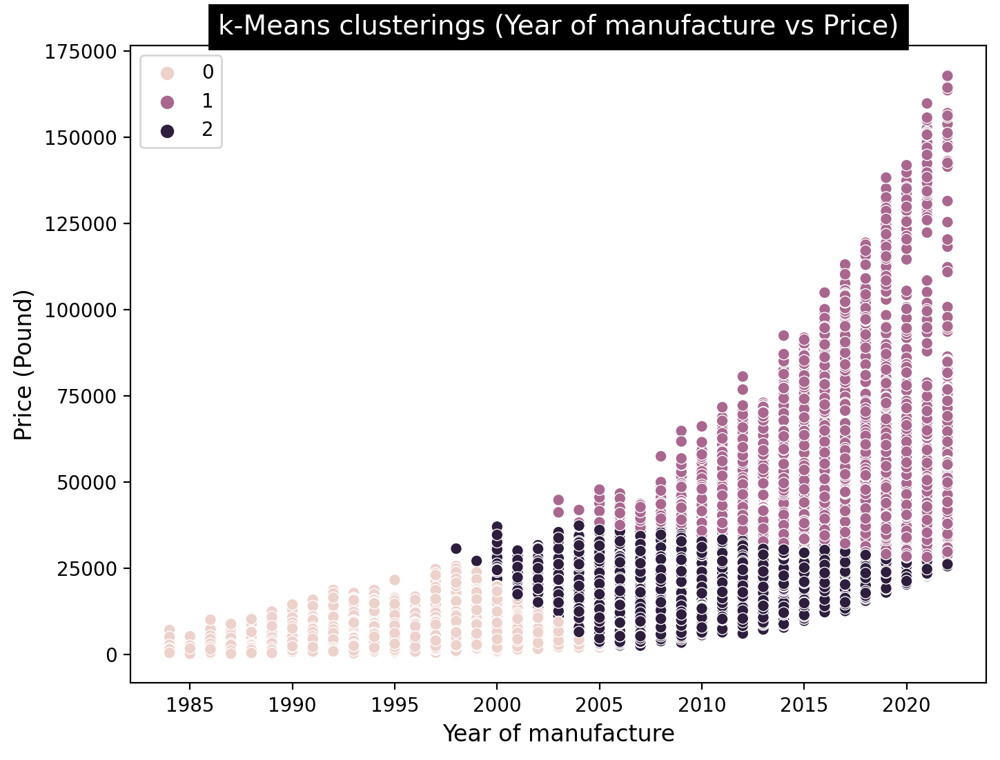

In [9]:
# Scatter plot: k-Means clustering Results- Year of manufacture vs Price
plt.figure(figsize=(8, 6), dpi=200)
sns.scatterplot(data = df, x = "Year of manufacture", y = "Price", hue = kmeans_labels_pred)
# Add a title to the plot
plt.title('k-Means clusterings (Year of manufacture vs Price)', backgroundcolor='black', color='white', fontsize=14)
plt.xlabel("Year of manufacture", fontsize = 12)
plt.ylabel("Price (Pound)", fontsize = 12)
# Display the plot
plt.show()

In [10]:
# Create a copy of the original DataFrame (df) to avoid modifying the original data
price_df_clust = df.copy()
# Add a new column ("Clus_Num") to price_df_clust
price_df_clust["Cluster_No"] = kmeans_labels_pred
# Select relevant columns from the DataFrame
selected_columns = ["Engine size", "Year of manufacture", "Mileage", "Price", "Cluster_No"]
# Group the DataFrame by the "Clus_Num" column and calculate the mean for each cluster
price_df_clust[selected_columns].groupby('Cluster_No').mean()

,Engine size,Year of manufacture,Mileage,Price
Cluster_No,,,,
0,1.740232,1995.512270,165776.160887,3595.044815
1,2.302805,2017.435170,30734.491938,48235.959019
2,1.656374,2010.451622,74474.609052,15666.171126


In [11]:
# Count the occurrences of each unique value in the "Clus_Num" column
clust_sizes = price_df_clust[selected_columns].groupby('Cluster_No').size().to_frame()
clust_sizes.columns = ["size"]
clust_sizes

,size
Cluster_No,
0,23675
1,5954
2,20371


### k-Means Clustering – Mileage versus Price

In [12]:
# select the columns
feature_names2 = ["Mileage", "Price"]
# create a new DataFrame x_cl2 using selected the columns (feature_names)
x_cl2 = df[feature_names2]

In [13]:
# Create a StandardScaler instance
scale_cl2 = StandardScaler()
# Fit the scaler to the data and transform the data
x_cl2_scaled = scale_cl2.fit_transform(x_cl2)

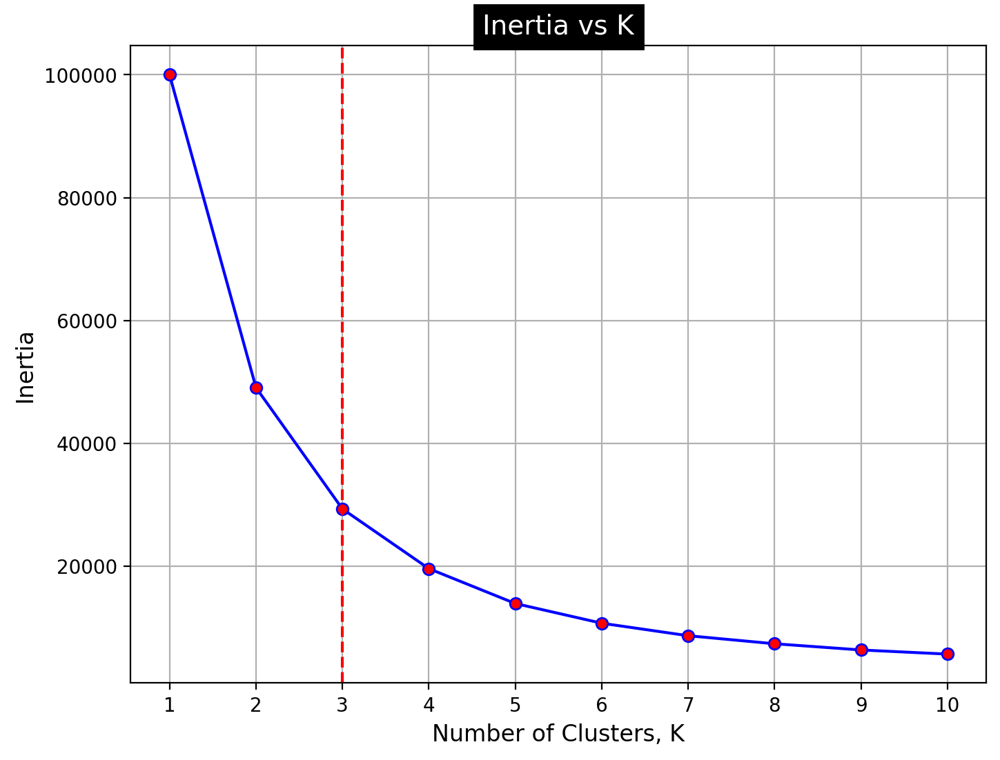

In [14]:
# List to store inertia scores
List_inertia2 = []

# Loop through different values of K
for k in range(1, 11):
    # Create a KMeans instance with the specified number of clusters (K)
    kmeans2 = KMeans(n_clusters = k, random_state = 42)
    # Fit the KMeans model to the data
    kmeans2.fit(x_cl2_scaled)
    # Append the inertia score to the list
    List_inertia2.append(kmeans2.inertia_)

# Create a list of K values
k_values = [i for i in range(1, 11)]
# Creating a KneeLocator instance to find the knee point
k1 = KneeLocator (range(1,11), List_inertia2, curve = 'convex', direction = 'decreasing')
# Plot the inertia values against the number of clusters (K)
plt.figure(figsize=(8, 6), dpi=200)
plt.plot(k_values, List_inertia2, marker='o', c='b', mfc='r')
# Adding a vertical dashed line at the identified elbow point
plt.axvline (x = k1.elbow, color = 'r', label = 'axvline - full height', ls = '--')
plt.xlabel("Number of Clusters, K", fontsize = 12)
plt.ylabel("Inertia", fontsize = 12)
plt.xticks(np.arange(1, 11, 1))
plt.title("Inertia vs K", backgroundcolor='black', color='white', fontsize=14)
plt.grid()
# Display the plot
plt.show()

In [15]:
# Specify the number of clusters (k)
k = 3
# Create a KMeans instance with the specified number of clusters
kmeans_final = KMeans(n_clusters = k, random_state = 42)
# Fit the KMeans model to the scaled data
kmeans_labels_pred2 = kmeans_final.fit_predict(x_cl2_scaled)

In [16]:
# Print a header for the section
print("Internal Evaluation Metrics")
print("===============================")
# Calculate and print the Davies-Bouldin score
davies_bouldin = davies_bouldin_score(x_cl2_scaled, kmeans_labels_pred2)
print(f"Davies Bouldin Index: {davies_bouldin:.4f}")
# Calculate and print the Silhouette score
silhouette = silhouette_score(x_cl2_scaled, kmeans_labels_pred2)
print(f"Silhouette Coefficient: {silhouette:.4f}")

Internal Evaluation Metrics


Davies Bouldin Index: 0.6881

Silhouette Coefficient: 0.4781


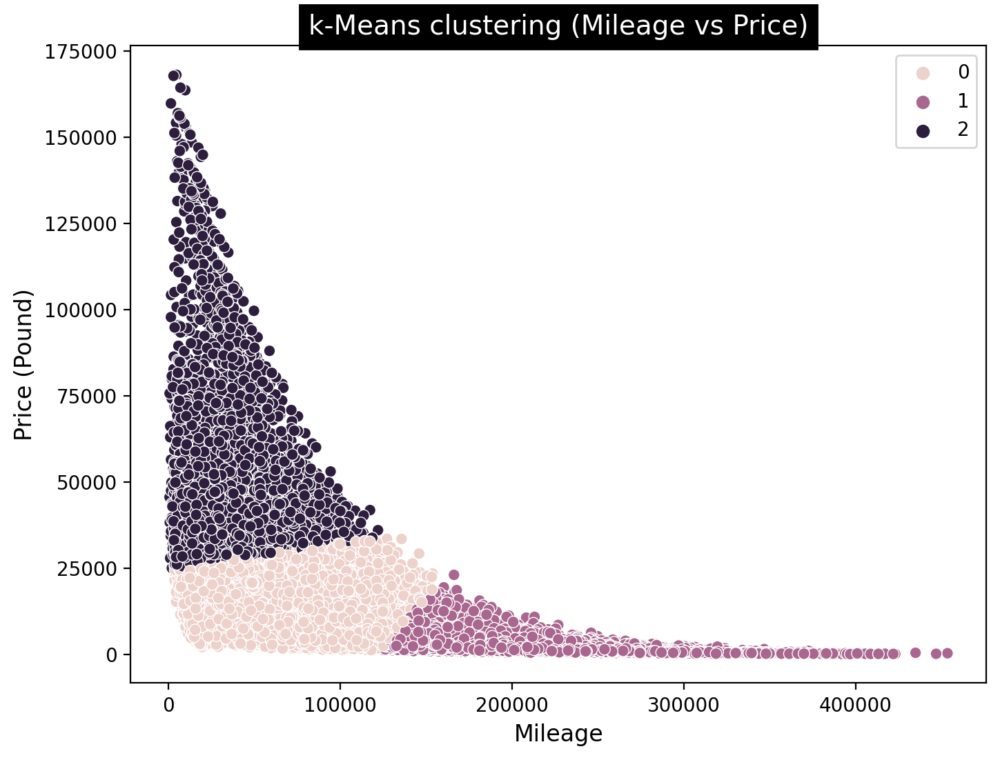

In [17]:
# Scatter plot: k-Means clustering Results- Mileage vs Price
plt.figure(figsize=(8, 6), dpi=200)
sns.scatterplot(data = df, x = "Mileage", y = "Price", hue = kmeans_labels_pred2)
# Add a title to the plot
plt.title('k-Means clustering (Mileage vs Price)', backgroundcolor='black', color='white', fontsize=14)
plt.xlabel("Mileage", fontsize = 12)
plt.ylabel("Price (Pound)", fontsize = 12)
# Display the plot
plt.show()

Now, we want to compare the clusters predicted by this model to the clusters that we obtained
in previous section. Do we still identify the same clusters in each case?
The easiest way to see this is by plotting Year of manufacture versus Price (as we had in previous section) but
now assigning the hue according to the new cluster labels that we have produced in this section.
We can then compare it to the plot that we produced in previous section.

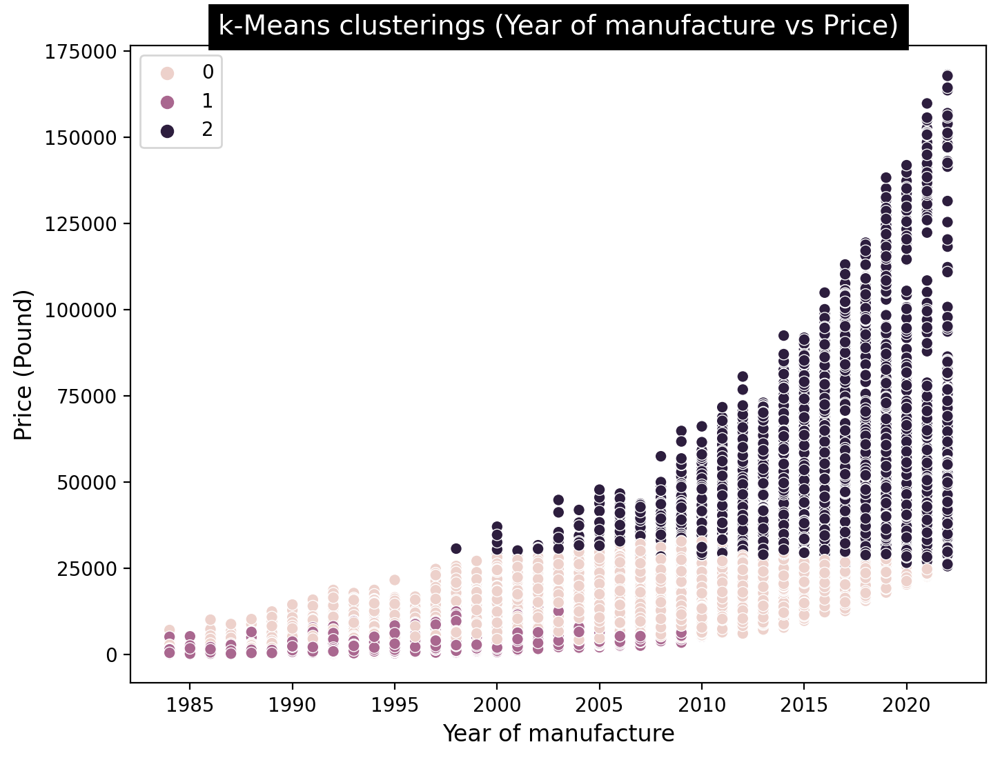

In [18]:
# Scatter plot: k-Means clustering Results- Year of manufacture vs Price
plt.figure(figsize=(8, 6), dpi=200)
sns.scatterplot(data = df, x = "Year of manufacture", y = "Price", hue = kmeans_labels_pred2)
# Add a title to the plot
plt.title('k-Means clusterings (Year of manufacture vs Price)', backgroundcolor='black', color='white', fontsize=14)
plt.xlabel("Year of manufacture", fontsize = 12)
plt.ylabel("Price (Pound)", fontsize = 12)
# Display the plot
plt.show()

In [19]:
# Create a copy of the original DataFrame  to avoid modifying the original data
price_df_clust = df.copy()
# Add a new column ("Clus_Num") to price_df_clust
price_df_clust["Cluster_No"] = kmeans_labels_pred2
# Select relevant columns from the DataFrame
selected_columns = ["Engine size", "Year of manufacture", "Mileage", "Price", "Cluster_No"]
# Group the DataFrame by the "Clus_Num" column and calculate the mean for each cluster
price_df_clust[selected_columns].groupby('Cluster_No').mean()

,Engine size,Year of manufacture,Mileage,Price
Cluster_No,,,,
0,1.658683,2006.911929,79014.283176,12725.973132
1,1.746495,1995.247075,192294.900259,2803.563119
2,2.238085,2016.977425,31700.407330,44990.084309


In [20]:
# Count the occurrences of each unique value in the "Clus_Num" column
clust_sizes = price_df_clust[selected_columns].groupby('Cluster_No').size().to_frame()
clust_sizes.columns = ["size"]
clust_sizes

,size
Cluster_No,
0,25048
1,17776
2,7176


### k-Means Clustering – Engine size versus Price

In [21]:
# select the columns
feature_names3 = ["Engine size", "Price"]
# create a new DataFrame x_cl3 using selected the columns (feature_names3)
x_cl3 = df[feature_names3]

In [22]:
# Create a StandardScaler instance
scale_cl3 = StandardScaler()
# Fit the scaler to the data and transform the data
x_cl3_scaled = scale_cl3.fit_transform(x_cl3)

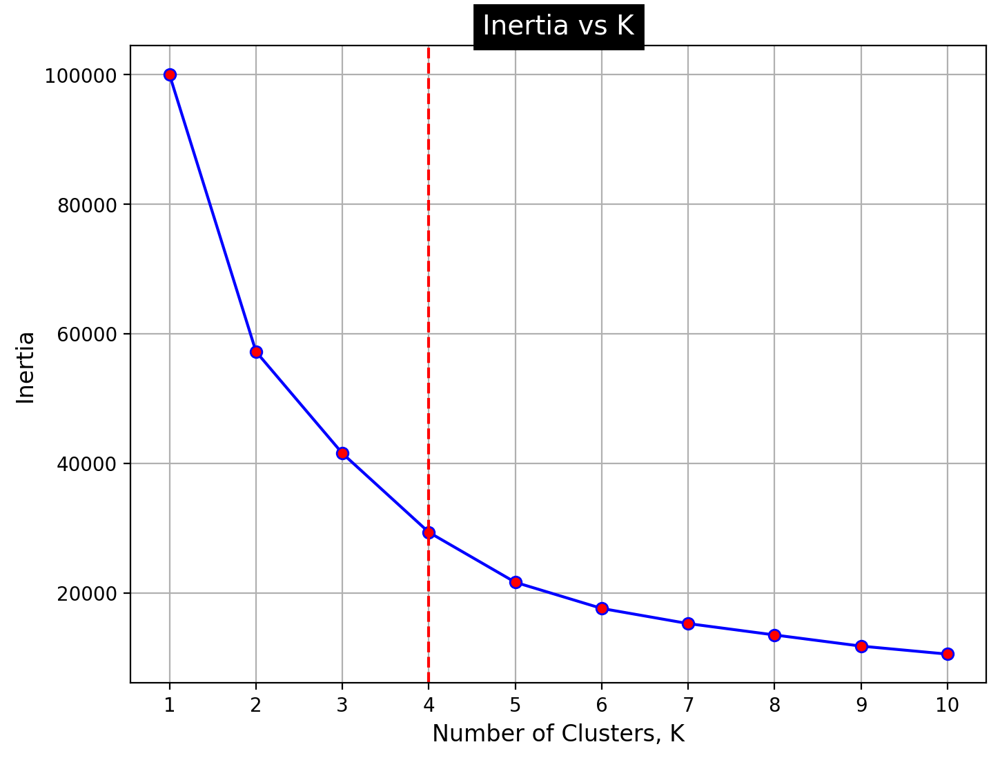

In [23]:
# List to store inertia scores
List_inertia = []

# Loop through different values of K
for k in range(1, 11):
    # Create a KMeans instance with the specified number of clusters (K)
    kmeans = KMeans(n_clusters = k, random_state = 42)
    # Fit the KMeans model to the data
    kmeans.fit(x_cl3_scaled)
    # Append the inertia score to the list
    List_inertia.append(kmeans.inertia_)

# Create a list of K values
k_values = [i for i in range(1, 11)]
# Creating a KneeLocator instance to find the knee point
k1 = KneeLocator (range(1,11), List_inertia, curve = 'convex', direction = 'decreasing')
# Plot the inertia values against the number of clusters (K)
plt.figure(figsize=(8, 6), dpi=200)
plt.plot(k_values, List_inertia, marker='o', c='b', mfc='r')
# Adding a vertical dashed line at the identified elbow point
plt.axvline (x = k1.elbow, color = 'r', label = 'axvline - full height', ls = '--')
plt.xlabel("Number of Clusters, K", fontsize=12)
plt.ylabel("Inertia", fontsize=12)
plt.xticks(np.arange(1, 11, 1))
plt.title("Inertia vs K", backgroundcolor='black', color='white', fontsize=14)
plt.grid()
# Display the plot
plt.show()

__Note:__ Unlike the two previous sections, we see the best value to use is k=4.

We will now fit our final k-Means model, using the optimal number of clusters (k = 4) that we determined above.

In [24]:
# Specify the number of clusters (k)
k = 4
# Create a KMeans instance with the specified number of clusters
kmeans_final = KMeans(n_clusters = k, random_state = 42)
# Fit the KMeans model to the scaled data
kmeans_labels_pred3 = kmeans_final.fit_predict(x_cl3_scaled)

In [25]:
# Print a header for the section
print("Internal Evaluation Metrics")
print("===============================")
# Calculate and print the Davies-Bouldin score
davies_bouldin = davies_bouldin_score(x_cl2_scaled, kmeans_labels_pred3)
print(f"Davies Bouldin Index: {davies_bouldin:.4f}")
# Calculate and print the Silhouette score
silhouette = silhouette_score(x_cl2_scaled, kmeans_labels_pred3)
print(f"Silhouette Coefficient: {silhouette:.4f}")

Internal Evaluation Metrics


Davies Bouldin Index: 1.9525

Silhouette Coefficient: 0.2200


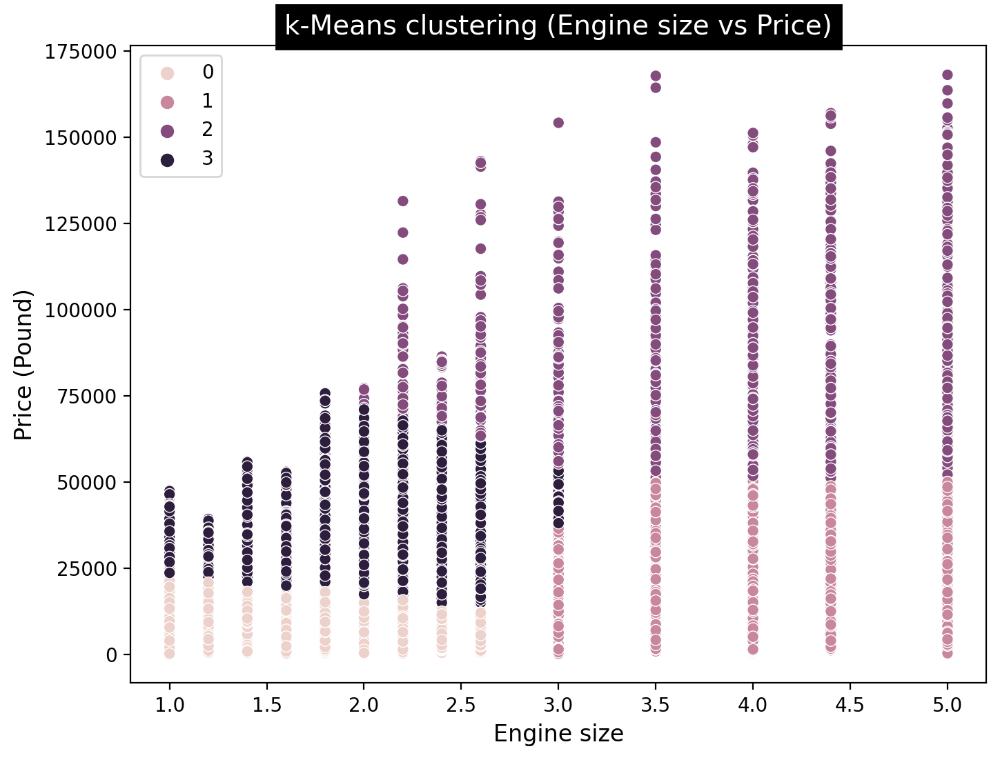

In [26]:
# Scatter plot: k-Means clustering Results- ngine size vs Price
plt.figure(figsize=(8, 6), dpi=200)
sns.scatterplot(data = df, x = "Engine size", y = "Price", hue = kmeans_labels_pred3)
# Add a title to the plot
plt.title('k-Means clustering (Engine size vs Price)', backgroundcolor='black', color='white', fontsize=14)
plt.xlabel("Engine size", fontsize = 12)
plt.ylabel("Price (Pound)", fontsize = 12)
# Display the plot
plt.show()

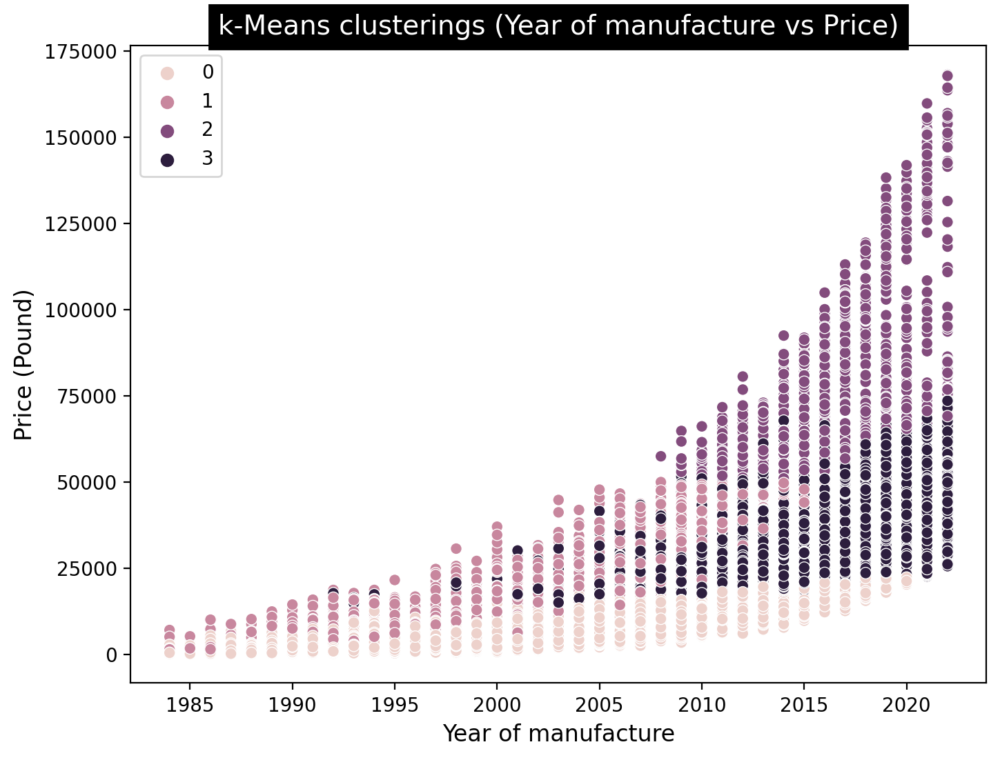

In [27]:
# Scatter plot: k-Means clustering Results- Year of manufacture vs Price
plt.figure(figsize=(8, 6), dpi=200)
sns.scatterplot(data = df, x = "Year of manufacture", y = "Price", hue = kmeans_labels_pred3)
# Add a title to the plot
plt.title('k-Means clusterings (Year of manufacture vs Price)', backgroundcolor='black', color='white', fontsize=14)
plt.xlabel("Year of manufacture", fontsize = 12)
plt.ylabel("Price (Pound)", fontsize = 12)
# Display the plot
plt.show()

In [28]:
# Create a copy of the original DataFrame  to avoid modifying the original data
price_df_clust = df.copy()
# Add a new column ("Clus_Num") to price_df_clust
price_df_clust["Cluster_No"] = kmeans_labels_pred3
# Select relevant columns from the DataFrame
selected_columns = ["Engine size", "Year of manufacture", "Mileage", "Price", "Cluster_No"]
# Group the DataFrame by the "Clus_Num" column and calculate the mean for each cluster
price_df_clust[selected_columns].groupby('Cluster_No').mean()

,Engine size,Year of manufacture,Mileage,Price
Cluster_No,,,,
0,1.541764,2000.829121,133851.184723,6503.981550
1,3.767223,2000.153506,139010.507148,16121.004765
2,3.754438,2016.938856,33100.651874,85037.236686
3,1.808354,2015.646676,39897.338187,31255.710385


In [29]:
# Count the occurrences of each unique value in the "Clus_Num" column
clust_sizes = price_df_clust[selected_columns].groupby('Cluster_No').size().to_frame()
clust_sizes.columns = ["size"]
clust_sizes

,size
Cluster_No,
0,35610
1,2938
2,1014
3,10438


### "Year of manufacture" vs "Mileage"

In [30]:
# select the columns
feature_names = ["Year of manufacture", "Mileage"]
# create a new DataFrame x_cl using selected the columns (feature_names)
x_cl = df[feature_names]

In [31]:
# Create a StandardScaler instance
scale_cl = StandardScaler()
# Fit the scaler to the data and transform the data
x_cl_scaled = scale_cl.fit_transform(x_cl)

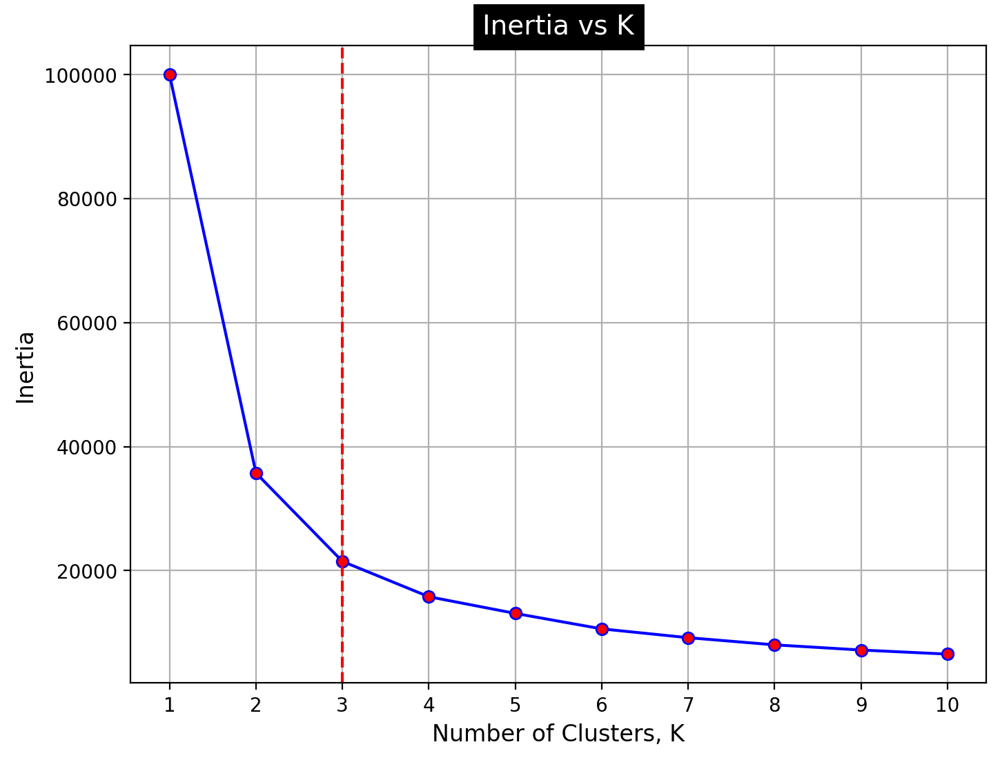

In [32]:
# List to store inertia scores
List_inertia = []

# Loop through different values of K
for k in range(1, 11):
    # Create a KMeans instance with the specified number of clusters (K)
    kmeans = KMeans(n_clusters = k, random_state = 42)
    # Fit the KMeans model to the data
    kmeans.fit(x_cl_scaled)
    # Append the inertia score to the list
    List_inertia.append(kmeans.inertia_)

# Create a list of K values
k_values = [i for i in range(1, 11)]
# Creating a KneeLocator instance to find the knee point
k1 = KneeLocator (range(1,11), List_inertia, curve = 'convex', direction = 'decreasing')
# Plot the inertia values against the number of clusters (K)
plt.figure(figsize=(8, 6), dpi=200)
plt.plot(k_values, List_inertia, marker='o', c='b', mfc='r')
# Adding a vertical dashed line at the identified elbow point
plt.axvline (x = k1.elbow, color = 'r', label = 'axvline - full height', ls = '--')
plt.xlabel("Number of Clusters, K", fontsize = 12)
plt.ylabel("Inertia", fontsize = 12)
plt.xticks(np.arange(1, 11, 1))
plt.title("Inertia vs K", backgroundcolor='black', color='white', fontsize=14)
plt.grid()
# Display the plot
plt.show()

In [33]:
# Specify the number of clusters (k)
k = 3
# Create a KMeans instance with the specified number of clusters
kmeans_final = KMeans(n_clusters = k, random_state = 42)
# Fit the KMeans model to the scaled data
kmeans_labels_pred = kmeans_final.fit_predict(x_cl_scaled)

In [34]:
# Print a header for the section
print("Internal Evaluation Metrics")
print("===============================")

# Calculate and print the Davies-Bouldin score
davies_bouldin = davies_bouldin_score(x_cl_scaled, kmeans_labels_pred)
print(f"Davies Bouldin Index: {davies_bouldin:.4f}")
# The Davies-Bouldin score measures the average similarity-to-dissimilarity ratio between clusters.
# Lower values indicate better clustering.

# Calculate and print the Silhouette score
silhouette = silhouette_score(x_cl_scaled, kmeans_labels_pred)
print(f"Silhouette Coefficient: {silhouette:.4f}")
# The Silhouette score measures how well-defined the clusters are.
# It ranges from -1 to 1, where higher values indicate better-defined clusters.

Internal Evaluation Metrics


Davies Bouldin Index: 0.7548

Silhouette Coefficient: 0.4648


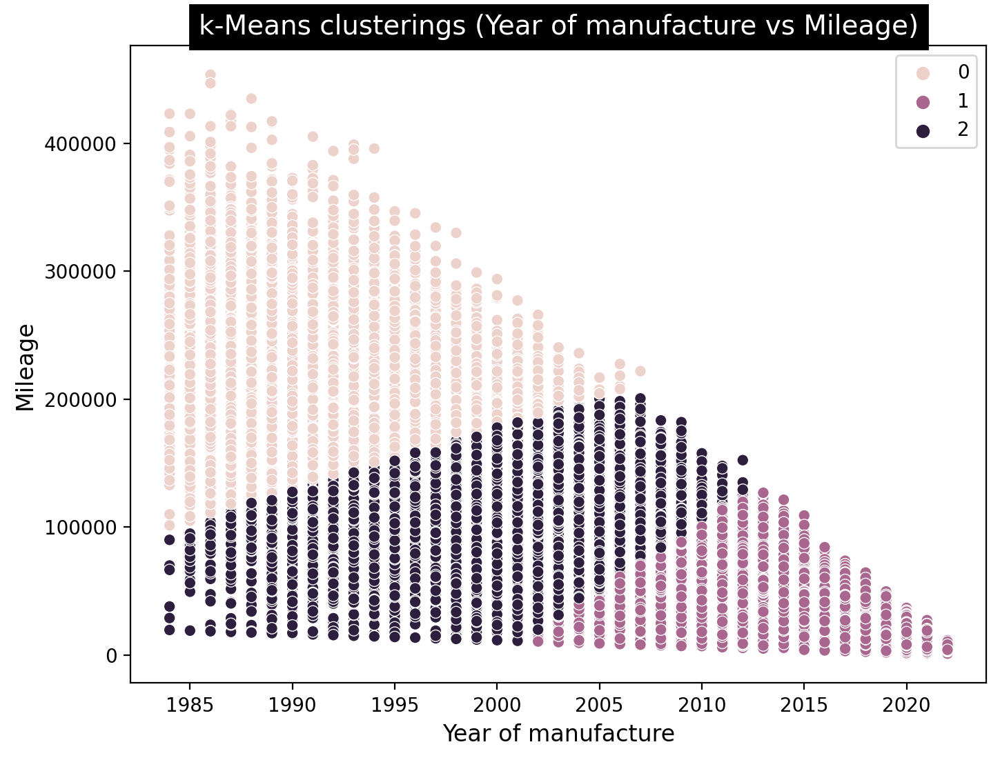

In [35]:
# Scatter plot: k-Means clustering Results- Year of manufacture vs Mileage
plt.figure(figsize=(8, 6), dpi=200)
sns.scatterplot(data = df, x = "Year of manufacture", y = "Mileage", hue = kmeans_labels_pred)
# Add a title to the plot
plt.title('k-Means clusterings (Year of manufacture vs Mileage)', backgroundcolor='black', color='white', fontsize=14)
plt.xlabel("Year of manufacture", fontsize = 12)
plt.ylabel("Mileage", fontsize = 12)
# Display the plot
plt.show()

## G. Other Clustering Algorithms

###  G.1.Hierarchical Clustering (Agglomerative)

#### Year of manufacture versus price

In [36]:
# select the columns
feature_names = ["Year of manufacture", "Price"]
# create a new DataFrame x_cl using selected the columns (feature_names)
x_cl = df[feature_names]

In [37]:
# Create a StandardScaler instance
scale_cl = StandardScaler()
# Fit the scaler to the data and transform the data
x_cl_scaled = scale_cl.fit_transform(x_cl)

In [38]:
# Initialise the model
agg_model = AgglomerativeClustering(n_clusters = 3, linkage = 'complete')

In [39]:
# Perform clustering and predict cluster labels
agg_labels_pred = agg_model.fit_predict(x_cl_scaled)

In [40]:
# Print a header for the section
print("Internal Evaluation Metrics")
print("===============================")
# Calculate and print the Davies-Bouldin score
davies_bouldin = davies_bouldin_score(x_cl_scaled, agg_labels_pred)
print(f"Davies Bouldin Index: {davies_bouldin:.4f}")
# Calculate and print the Silhouette score
silhouette = silhouette_score(x_cl_scaled, agg_labels_pred)
print(f"Silhouette Coefficient: {silhouette:.4f}")

Internal Evaluation Metrics


Davies Bouldin Index: 0.4639

Silhouette Coefficient: 0.6377


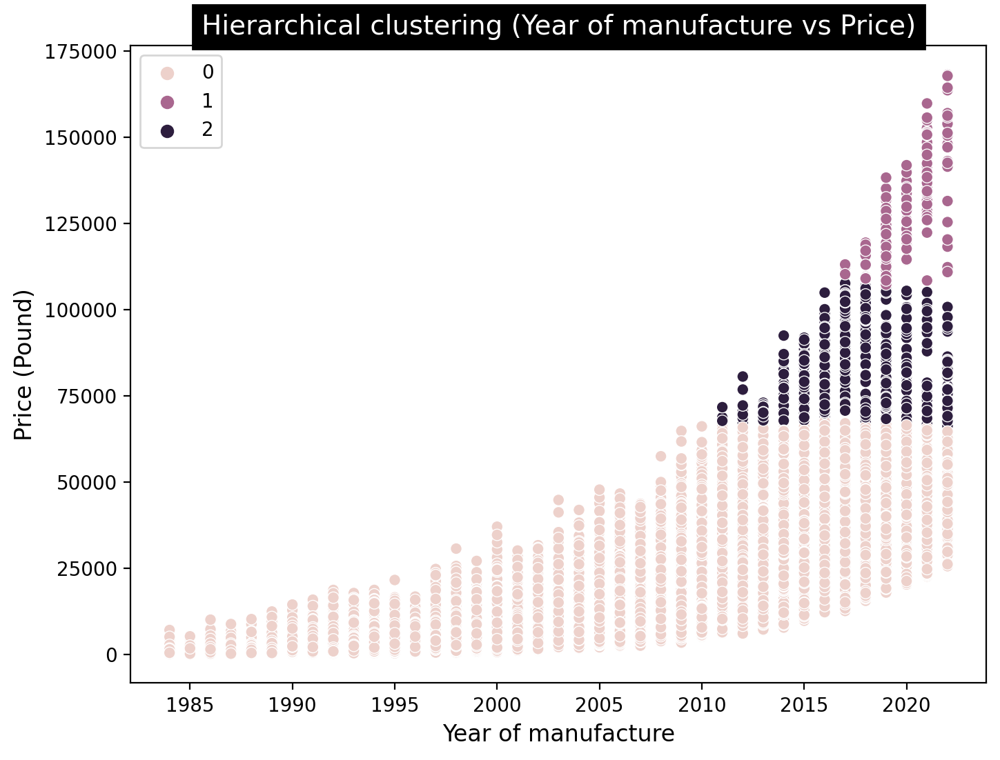

In [41]:
# Scatter plot: Hierarchical clustering Results- Year of manufacture vs Price
plt.figure(figsize=(8, 6), dpi=200)
sns.scatterplot(data = df, x = "Year of manufacture", y = "Price", hue = agg_labels_pred)
# Add a title to the plot
plt.title('Hierarchical clustering (Year of manufacture vs Price)', backgroundcolor='black', color='white', fontsize=14)
plt.xlabel("Year of manufacture", fontsize = 12)
plt.ylabel("Price (Pound)", fontsize = 12)
# Display the plot
plt.show()

In [42]:
# Create a copy of the original DataFrame to avoid modifying the original data
df_agg = df.copy()
# Add a new column ("Clus_Num") to df_agg
df_agg["Cluster_No"] = agg_labels_pred
# Select relevant columns from the DataFrame
selected_columns = ["Year of manufacture", "Mileage", "Engine size", "Price", "Cluster_No"]
# Group the DataFrame by the "Clus_Num" column and calculate the mean for each cluster
df_agg[selected_columns].groupby('Cluster_No').mean()

,Year of manufacture,Mileage,Engine size,Price
Cluster_No,,,,
0,2003.993907,113826.916873,1.743745,12588.330355
1,2019.936508,16454.306878,4.101058,128791.370370
2,2017.542757,29923.975567,3.524084,82512.005236


In [43]:
# Count the occurrences of each unique value in the "Clus_Num" column
clust_sizes = df_agg[selected_columns].groupby('Cluster_No').size().to_frame()
clust_sizes.columns = ["size"]
clust_sizes

,size
Cluster_No,
0,49238
1,189
2,573


#### Mileage versus Price

In [44]:
# select the columns
feature_names2 = ["Mileage", "Price"]
# create a new DataFrame x_cl2 using selected the columns (feature_names)
x_cl2 = df[feature_names2]

In [45]:
# Create a StandardScaler instance
scale_cl2 = StandardScaler()
# Fit the scaler to the data and transform the data
x_cl_scaled2 = scale_cl2.fit_transform(x_cl2)

In [46]:
# Initialise the model
agg_model2 = AgglomerativeClustering(n_clusters = 3, linkage = 'complete')

In [47]:
# Perform clustering and predict cluster labels
agg_labels_pred2 = agg_model2.fit_predict(x_cl_scaled2)

In [48]:
# Print a header for the section
print("Internal Evaluation Metrics")
print("===============================")
# Calculate and print the Davies-Bouldin score
davies_bouldin = davies_bouldin_score(x_cl_scaled2, agg_labels_pred2)
print(f"Davies Bouldin Index: {davies_bouldin:.4f}")
# Calculate and print the Silhouette score
silhouette = silhouette_score(x_cl_scaled2, agg_labels_pred2)
print(f"Silhouette Coefficient: {silhouette:.4f}")

Internal Evaluation Metrics


Davies Bouldin Index: 0.5643

Silhouette Coefficient: 0.4329


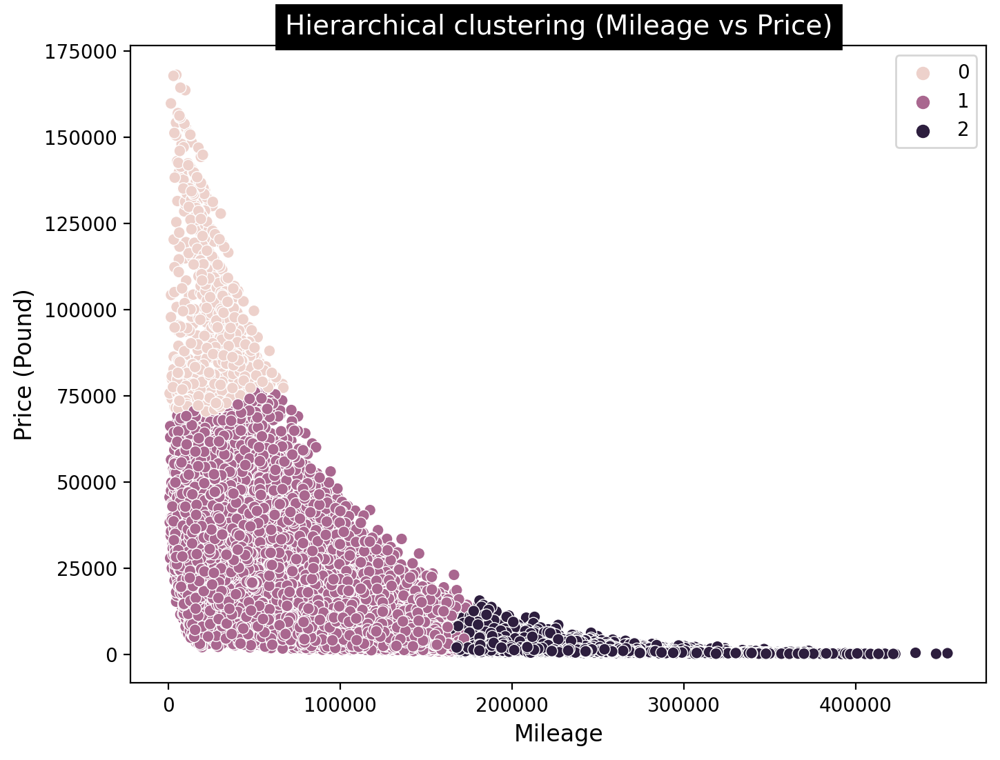

In [50]:
# Scatter plot: Hierarchical clustering Results- Mileage vs Price
plt.figure(figsize=(8, 6), dpi=200)
sns.scatterplot(data = df, x = "Mileage", y = "Price", hue = agg_labels_pred2)
# Add a title to the plot
plt.title('Hierarchical clustering (Mileage vs Price)', backgroundcolor='black', color='white', fontsize=14)
plt.xlabel("Mileage", fontsize = 12)
plt.ylabel("Price (Pound)", fontsize = 12)
# Display the plot
plt.show()

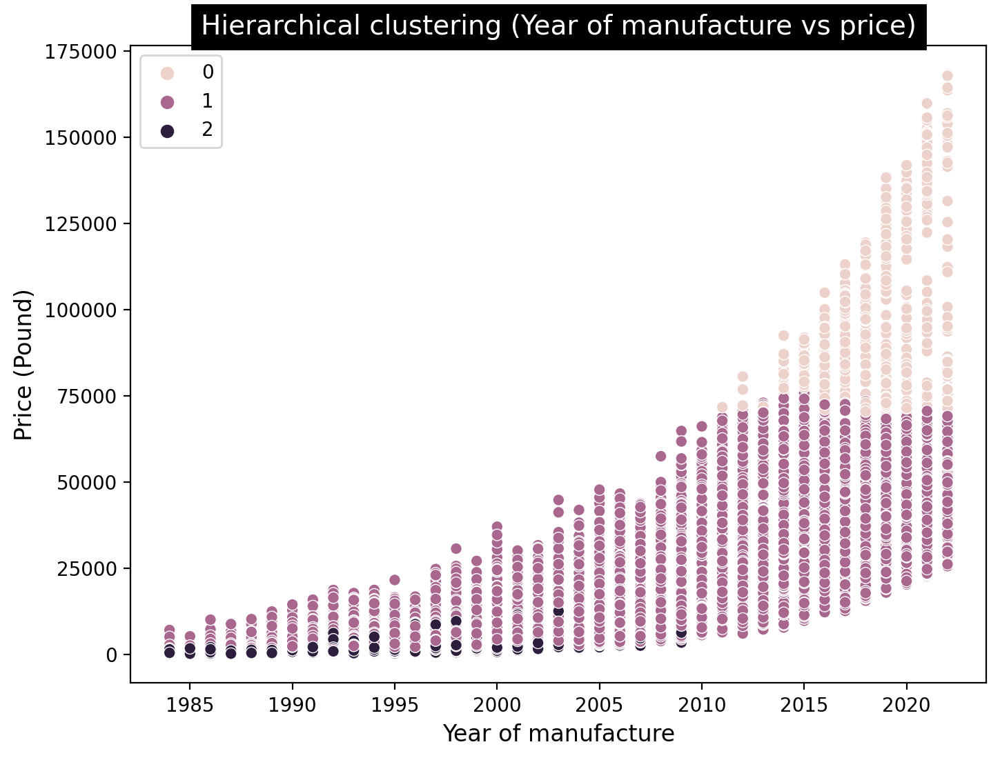

In [51]:
# Scatter plot: Hierarchical clustering Results- Year of manufacture vs price
plt.figure(figsize=(8, 6), dpi=200)
sns.scatterplot(data = df, x = "Year of manufacture", y = "Price", hue = agg_labels_pred2)
# Add a title to the plot
plt.title('Hierarchical clustering (Year of manufacture vs price)', backgroundcolor='black', color='white', fontsize=14)
plt.xlabel("Year of manufacture", fontsize = 12)
plt.ylabel("Price (Pound)", fontsize = 12)
# Display the plot
plt.show()

In [52]:
# Create a copy of the original DataFrame (df) to avoid modifying the original data
df_agg2 = df.copy()
# Add a new column ("Clus_Num") to df_agg2
df_agg2["Cluster_No"] = agg_labels_pred2
# Select relevant columns from the DataFrame
selected_columns = ["Year of manufacture", "Mileage", "Engine size", "Price", "Cluster_No"]
# Group the DataFrame by the "Clus_Num" column and calculate the mean for each cluster
df_agg2[selected_columns].groupby('Cluster_No').mean()

,Year of manufacture,Mileage,Engine size,Price
Cluster_No,,,,
0,2018.533762,24134.749196,3.717846,99357.209003
1,2006.929748,84262.798422,1.741009,15707.751579
2,1993.403154,221114.792048,1.776221,1922.466522


In [53]:
# Count the occurrences of each unique value in the "Clus_Num" column
clust_sizes2 = df_agg2[selected_columns].groupby('Cluster_No').size().to_frame()
clust_sizes2.columns = ["size"]
clust_sizes2

,size
Cluster_No,
0,622
1,38789
2,10589


### G.2. DBSCAN 

#### Year of manufacture versus price

In [54]:
# select the columns
feature_names = ["Year of manufacture", "Price"]
# create a new DataFrame x_cl using selected the columns (feature_names)
x_cl = df[feature_names]

In [55]:
# Create a StandardScaler instance
scale_cl = StandardScaler()
# Fit the scaler to the data and transform the data
x_cl_scaled = scale_cl.fit_transform(x_cl)

In [56]:
# Create a DBSCAN instance with specified parameters
dbscan = DBSCAN(eps=0.2, min_samples=3)

In [57]:
# Use DBSCAN to perform clustering and predict cluster labels
db_labels_pred = dbscan.fit_predict(x_cl_scaled)

Here we calculate the evaluation metrics for the clustering model.

In [58]:
# Print a header for the section
print("Internal Evaluation Metrics")
print("===============================")
# Calculate and print the Davies-Bouldin score
davies_bouldin = davies_bouldin_score(x_cl_scaled, db_labels_pred)
print(f"Davies Bouldin Index: {davies_bouldin:.4f}")
# Calculate and print the Silhouette score
silhouette = silhouette_score(x_cl_scaled, db_labels_pred)
print(f"Silhouette Coefficient: {silhouette:.4f}")

Internal Evaluation Metrics


Davies Bouldin Index: 1.4952

Silhouette Coefficient: 0.6763


Compared to the k-Means and Hierarchical Clustering models that we looked at previously, we see that the clustering produced by the DBSCAN algorithms has a much higher DB Index, but surprisingly a higher Silhouette Coefficient. So, in terms of metric avaluation there is a conflict between these two metrics.

So, lets visualise the clusters on a scatter plot to see whether the identified clusters are qualitatively logical.

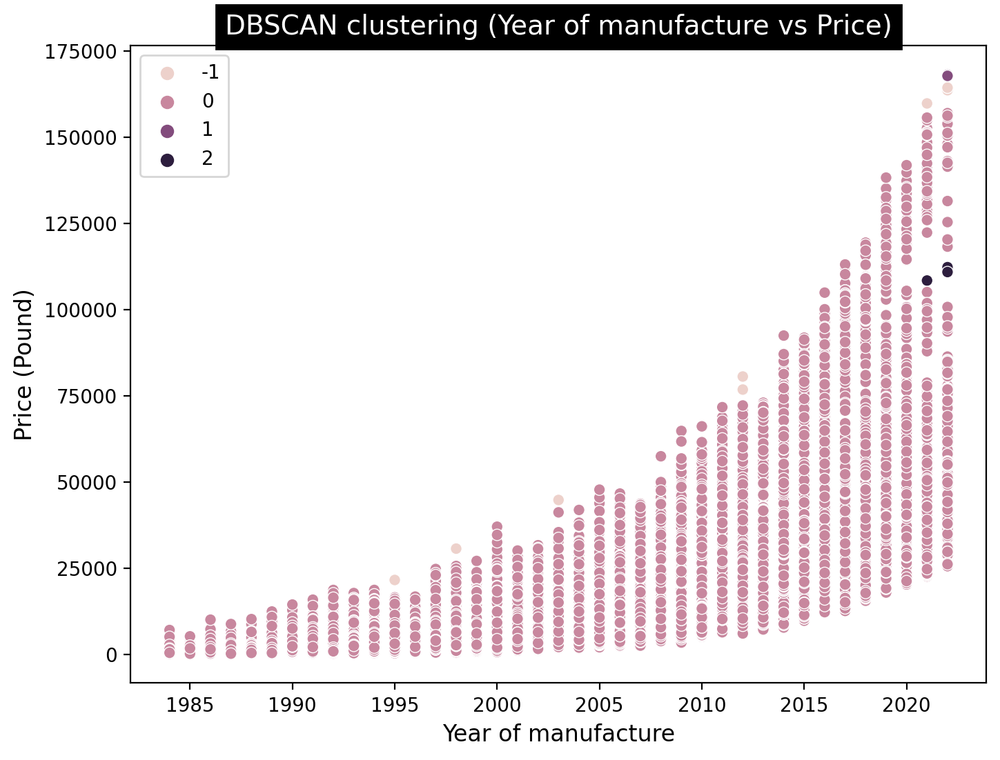

In [59]:
# Scatter plot: DBSCAN clustering Results- Year of manufacture vs price
plt.figure(figsize=(8, 6), dpi=200)
sns.scatterplot(data = df, x = "Year of manufacture", y = "Price", hue = db_labels_pred)
# Add a title to the plot
plt.title('DBSCAN clustering (Year of manufacture vs Price)', backgroundcolor='black', color='white', fontsize=14)
plt.xlabel("Year of manufacture", fontsize = 12)
plt.ylabel("Price (Pound)", fontsize = 12)
# Display the plot
plt.show()

From this plot we see that the DBSCAN has identified three clusters, labelled from 0 to 2, that there is no logical seperation between them. So, we can not consider this as a good clustering model for this dataset. 
It is worth mentioning that data points labelled as -1 have been flagged as noise and therefore are not assigned to a cluster.

In [60]:
# Number of clusters in labels, ignoring noise if present.
n_clusters = len(set(db_labels_pred)) - (1 if -1 in db_labels_pred else 0)
# Count the number of points classified as noise (-1)
n_noise = list(db_labels_pred).count(-1)
# Print the estimated number of clusters and noise points
print(f"Estimated number of clusters: {n_clusters}")
print(f"Estimated number of noise points: {n_noise}")

Estimated number of clusters: 3

Estimated number of noise points: 8


In [61]:
# Create a copy of the original DataFrame (df) to avoid modifying the original data
df_db = df.copy()
# Add a new column ("Clus_Num") to df_db
df_db["Cluster_No"] = db_labels_pred
# Select relevant columns from the DataFrame
selected_columns = ["Year of manufacture", "Mileage", "Engine size", "Price", "Cluster_No"]
# Group the DataFrame by the "Clus_Num" column and calculate the mean for each cluster
df_db[selected_columns].groupby('Cluster_No').mean()

,Year of manufacture,Mileage,Engine size,Price
Cluster_No,,,,
-1,2010.625000,12105.625000,4.300000,92764.000000
0,2004.206298,112526.251150,1.772376,13801.216441
1,2022.000000,4068.000000,4.500000,167952.000000
2,2021.666667,6598.666667,3.666667,110528.333333


In [62]:
# Count the occurrences of each unique value in the "Clus_Num" column
clust_sizes = df_db[selected_columns].groupby('Cluster_No').size().to_frame()
clust_sizes.columns = ["size"]
clust_sizes

,size
Cluster_No,
-1,8
0,49986
1,3
2,3


### Find the best values for DBSCAN parameters

In [28]:
from sklearn.model_selection import ParameterGrid

In [44]:
param_grid = {'eps': np.linspace(0.1, 1.0, 10),
              'min_samples': range(3, 10)
             }

# Create a list to store the results
results = []
no_of_clusters = []
sil_score = []

# Perform grid search
for params in ParameterGrid(param_grid):
    dbscan = DBSCAN(**params)
    db_labels_pred = dbscan.fit_predict(x_cl_scaled)
    
    # Check the number of unique labels
    n_clusters = len(set(db_labels_pred)) - (1 if -1 in db_labels_pred else 0)
    
    # Skip if there is only one label (no clusters)
    if n_clusters > 1:
        # Silhouette score metric
        silhouette = silhouette_score(x_cl_scaled, db_labels_pred)
    
        results.append({'params': params,
                        'silhouette_score': silhouette,
                        'n_clusters': n_clusters
                       })
        
        no_of_clusters.append(n_clusters)
        # Calculate the silhouette score for the current clustering
        sil_score.append(silhouette)

# Find the best parameters
best_result = max(results, key=lambda x: x['silhouette_score'])
best_params = best_result['params']
best_silhouette = best_result['silhouette_score']
n_clusters = best_result['n_clusters']

print("Best parameters:", best_params)
print("Best silhouette score:", best_silhouette)
print("Number of clusters:", n_clusters)

Best parameters: {'eps': 0.2, 'min_samples': 8}

Best silhouette score: 0.7079898884249649

Number of clusters: 2


In [46]:
best_results_for_three_clusters = [result for result in results if result['n_clusters'] == 3]
best_result = max(best_results_for_three_clusters, key=lambda x: x['silhouette_score'])
best_result

{'params': {'eps': 0.2, 'min_samples': 3},
 'silhouette_score': 0.6763268357510991,
 'n_clusters': 3}

__Note:__ If we want to make 3 clusters out of the dataset with global maximum value for silhouette Score , the DBSCAN parameters should be eps=0.2 and min_samples=3, and it is the same as what we choose in the previous section.